# Optimizers and Learning Rates, Measured

`loss.backward()` gives every weight a gradient. A gradient says which way a weight should move,
but not how far. `optimizer.step()` decides the distance, and this notebook takes that decision
apart. Each claim below is checked by computation or by a controlled training run, not taken on
trust.

Five questions, each answered with a measured number:

| | question | section |
|---|---|---|
| 1 | Does Adam computed by hand on one weight match PyTorch, quantity by quantity? | §1 |
| 2 | What does bias correction do, and after how many steps does it stop mattering? | §2, §4 |
| 3 | How large is each layer's update relative to its weights, and when does warmup stop shaping it? | §5 |
| 4 | Two runs planned for 300 steps, one cosine and one WSD, both stopped at 200: which model do you keep? | §6 |
| 5 | How does the best learning rate move with width, and what would you use at width 4,096? | §7 |

One principle runs through all of them: **tune both sides before accepting a comparison**. A
well-tuned method measured against a badly tuned baseline produces most of the optimizer claims
that later fail to replicate. §6, §M (Muon against AdamW) and §8 measure how large that effect is.

**How to read it.** Every section gives the intuition, then the math, then code that measures it.
Facts that must hold are written as `check(...)`, which stops the notebook if it is wrong. Outcomes
that are measured rather than guaranteed are written as `observe(...)`, which records whether they
held. Each section ends with one line to carry forward.

**Modes.**

| `MODE` | what runs | time |
|---|---|---|
| `learn` (default) | §R–§2 run live; every training result is replayed from `assets/results.json` (fetched once from GitHub, ~10 MB, if missing) | about a minute |
| `quick` | tiny models and short runs through every code path; writes `assets/quick/` | ~10 min on a GPU |
| `full` | the measured runs behind every number in this notebook | ~5 h of training on an RTX 3070 Laptop (resumable) |

**Contents.**

| part | sections |
|---|---|
| setup | §0 setup and decision rules |
| the arithmetic | §R the rules before Adam · §1 Adam by hand · §2 bias correction |
| training-time choices | §3 the testbed · §4 bias correction in a real model · §5 update-to-weight ratio and warmup · §6 cosine vs WSD · §M Muon vs AdamW |
| scaling | §7 learning rate vs width, and muP |
| method | §8 tuning both sides · §9 answers, limitations, references |

## §0 Setup and decision rules

The mode switch, the device and precision, a results store that makes long runs resumable, the plot
style, and the thresholds every later section uses to call a result.

In [1]:
MODE = "learn"          # "learn" | "quick" | "full"   (see the table above)
import os
MODE = os.environ.get("OPT_MODE", MODE)                 # lets a headless run choose the mode
FORCE = os.environ.get("FORCE", "0") == "1"             # ignore stored results and redo them
PRECISION_OVERRIDE = os.environ.get("OPT_PRECISION")    # e.g. "fp16" rehearses the T4 path on any GPU
assert MODE in ("learn", "quick", "full"), MODE
print(f"MODE={MODE}  FORCE={FORCE}  precision override={PRECISION_OVERRIDE}")

MODE=full  FORCE=False  precision override=None


In [2]:
# Install only what is missing (Colab already has all of it).
import importlib.util, subprocess, sys
_need = [pkg for pkg, mod in [("tokenizers", "tokenizers"), ("matplotlib", "matplotlib")]
         if importlib.util.find_spec(mod) is None]
if _need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_need])

In [3]:
import contextlib, copy, decimal, gc, json, math, platform, random, re, time, urllib.request
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from cycler import cycler

HERE = Path.cwd()
DATA = HERE / "data"
ASSETS = HERE / "assets" / ("quick" if MODE == "quick" else "")
RESULTS_FILE = ASSETS / "results.json"
REPO_RAW = "https://raw.githubusercontent.com/rahulni/Indic_LLM/main/11_Optimizers_LR"
for _d in (DATA, ASSETS):
    _d.mkdir(parents=True, exist_ok=True)


def _gpu_available():
    # device_count() first: with CUDA_VISIBLE_DEVICES="" is_available() can still say True
    try:
        return torch.cuda.device_count() > 0 and torch.cuda.is_available()
    except Exception:
        return False


DEV = "cuda" if _gpu_available() else "cpu"
CAP = torch.cuda.get_device_capability() if DEV == "cuda" else (0, 0)
if PRECISION_OVERRIDE:
    AMP = PRECISION_OVERRIDE
elif DEV == "cuda":
    AMP = "bf16" if CAP >= (8, 0) else "fp16"           # a T4 (sm75) has no bf16
else:
    AMP = "fp32"
AMP_DTYPE = {"bf16": torch.bfloat16, "fp16": torch.float16, "fp32": torch.float32}[AMP]

if DEV == "cuda" and platform.system() == "Windows" and "_MEM_CAP" not in globals():
    # Windows (WDDM) silently pages GPU memory to host RAM instead of raising OutOfMemoryError.
    # Capping the allocator at what is free now turns paging back into a real error.
    _free, _total = torch.cuda.mem_get_info()
    torch.cuda.set_per_process_memory_fraction(_free / _total)
    _MEM_CAP = _free
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def free_gpu():
    gc.collect()
    if DEV == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def autocast():
    if DEV != "cuda" or AMP == "fp32":
        return contextlib.nullcontext()
    return torch.autocast("cuda", dtype=AMP_DTYPE)


def qk(full, quick):
    """Pick a size by mode: quick mode shrinks everything, learn mode reads the full-run results."""
    return quick if MODE == "quick" else full


_gpu = torch.cuda.get_device_name(0) if DEV == "cuda" else "none"
print(f"device={DEV} ({_gpu})  precision={AMP}  torch={torch.__version__}  python={platform.python_version()}")

device=cuda (NVIDIA GeForce RTX 3070 Laptop GPU)  precision=bf16  torch=2.11.0+cu128  python=3.14.5


**The results store.** Every training experiment goes through `experiment(name, fn)`. In `quick`
and `full` mode it runs `fn` once, rounds the result to 5 significant figures, and saves it to
`results.json` straight away. An interrupted run therefore resumes where it stopped. In `learn`
mode nothing trains, and the stored result is returned (fetched from GitHub if the file is
missing).

In [4]:
def _clean(x, sig=5):
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().tolist()
    if isinstance(x, np.ndarray):
        x = x.tolist()
    if isinstance(x, (np.floating, np.integer, np.bool_)):
        x = x.item()
    if isinstance(x, bool) or x is None or isinstance(x, (int, str)):
        return x
    if isinstance(x, float):
        return float(f"{x:.{sig}g}") if math.isfinite(x) else None
    if isinstance(x, dict):
        return {str(k): _clean(v, sig) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v, sig) for v in x]
    return x


def save_results():
    if MODE == "learn":
        return
    tmp = RESULTS_FILE.with_suffix(".tmp")
    tmp.write_text(json.dumps(R, separators=(",", ":")), encoding="utf-8")
    for attempt in range(20):                     # Windows: an editor or virus scan can hold the file for a moment
        try:
            tmp.replace(RESULTS_FILE)
            return
        except PermissionError:
            time.sleep(0.5)
    tmp.replace(RESULTS_FILE)


def _load_results():
    if MODE == "learn":
        path = HERE / "assets" / "results.json"
        if not path.exists():
            try:
                path.parent.mkdir(parents=True, exist_ok=True)
                urllib.request.urlretrieve(f"{REPO_RAW}/assets/results.json", path)
            except Exception as e:                              # offline: the live sections still run
                print("could not fetch the stored results:", e)
                return {}
        return json.loads(path.read_text(encoding="utf-8"))
    if FORCE or not RESULTS_FILE.exists():
        return {}
    return json.loads(RESULTS_FILE.read_text(encoding="utf-8"))


R = _load_results()
ANS = R.setdefault("answers", {})                              # the measured answers, read by make_readme.py
_RAN = []                                                       # names run (not reused) in this session


def experiment(name, fn):
    if MODE == "learn":
        if name not in R:
            print(f"[{name}] is not in the stored results; skipped")
        return R.get(name)
    if name in R:
        return R[name]
    t0 = time.time()
    out = _clean(fn())
    R[name] = out
    R.setdefault("_seconds", {})[name] = round(time.time() - t0, 1)
    save_results()
    _RAN.append(name)
    print(f"  ran [{name}] in {time.time() - t0:.0f} s")
    return out


def check(cond, msg):
    assert cond, f"CHECK FAILED: {msg}"
    print(f"✓ {msg}")


def observe(key, cond, msg):
    """Record a measured outcome. It never stops the notebook; the README reports whether it held."""
    R.setdefault("_observations", {})[key] = dict(held=bool(cond), msg=msg)
    print(("✓ observed: " if cond else "✗ not observed: ") + msg)
    save_results()


def env_info():
    info = dict(date=time.strftime("%Y-%m-%d"), torch=torch.__version__, python=platform.python_version(),
                device=DEV, precision=AMP, platform=platform.platform())
    if DEV == "cuda":
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, vram_gib=round(p.total_memory / 2**30, 2))
        try:
            q = subprocess.run(["nvidia-smi", "--query-gpu=driver_version,clocks.sm,clocks.max.sm,temperature.gpu",
                                "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=10).stdout
            drv, sm, smax, temp = [s.strip() for s in q.strip().split(",")]
            info.update(driver=drv, sm_clock_mhz=int(sm), sm_clock_max_mhz=int(smax), gpu_temp_c=int(temp))
        except Exception:
            pass
    if platform.system() == "Windows":
        try:
            ps = "(Get-CimInstance Win32_Battery).BatteryStatus; powercfg /getactivescheme"
            out = subprocess.run(["powershell", "-NoProfile", "-Command", ps],
                                 capture_output=True, text=True, timeout=20).stdout.splitlines()
            info["on_ac_power"] = out[0].strip() == "2" if out else None
            info["power_plan"] = (re.findall(r"\((.*)\)", out[-1]) or [None])[0] if out else None
        except Exception:
            pass
    try:
        info["git_commit"] = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
                                            text=True, timeout=10, cwd=HERE).stdout.strip() or None
    except Exception:
        pass
    return info


if MODE != "learn":
    R.setdefault("env", _clean(env_info()))         # the environment of the first (measuring) run is kept
    R["env_last"] = _clean(env_info())              # and the latest session's is recorded next to it
    save_results()
def show_env(env, title):
    keys = ("date", "gpu", "precision", "torch", "python", "driver", "on_ac_power", "power_plan", "git_commit")
    print(title + ("  " + "  ·  ".join(f"{k}: {env[k]}" for k in keys if env and k in env) if env else "  (none stored)"))


show_env(R.get("env"), "environment of the measured run:" if MODE == "learn" else "environment:")

environment:  date: 2026-10-11  ·  gpu: NVIDIA GeForce RTX 3070 Laptop GPU  ·  precision: bf16  ·  torch: 2.11.0+cu128  ·  python: 3.14.5  ·  driver: 566.07  ·  on_ac_power: True  ·  power_plan: Turbo  ·  git_commit: f8cb932


In [5]:
# Plot style: dark surface, one y-axis per panel, direct labels instead of legends where possible.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#0d1117", "#ffffff", "#c3c2b7", "#898781", "#2c2c2a", "#383835"
C = dict(blue="#3987e5", orange="#d95926", aqua="#199e70", yellow="#c98500",
         magenta="#d55181", green="#008300", violet="#9085e9", red="#e66767")
SERIES = [C[k] for k in ("blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red")]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titlelocation": "left",
    "legend.frameon": False, "legend.labelcolor": INK2, "axes.prop_cycle": cycler(color=SERIES),
    "figure.dpi": 110, "savefig.dpi": 110, "savefig.bbox": "tight", "axes.axisbelow": True})


def label_end(ax, x, y, text, color, dx=4, dy=0):
    """Queue a direct label at a line's end; finish() places all of an axis's labels without overlaps."""
    if not hasattr(ax, "_end_labels"):
        ax._end_labels = []
    ax._end_labels.append((x, y, text, color, dx, dy))


def _place_labels(fig, gap_px=12):
    fig.canvas.draw()                                            # limits and scales are final now
    k = fig.dpi / 72
    for ax in fig.axes:
        items = getattr(ax, "_end_labels", [])
        rows = []
        for x, y, text, color, dx, dy in items:
            if x is None or y is None or not (np.isfinite(x) and np.isfinite(y)):
                continue
            px, py = ax.transData.transform((x, y))
            rows.append([py + dy * k, py, x, y, text, color, dx])
        rows.sort(key=lambda r: r[0])
        for i in range(1, len(rows)):                            # push apart labels closer than gap_px
            rows[i][0] = max(rows[i][0], rows[i - 1][0] + gap_px)
        for ty, py, x, y, text, color, dx in rows:
            ax.annotate(text, (x, y), xytext=(dx * k, ty - py), textcoords="offset pixels", color=color,
                        fontsize=8.5, va="center", annotation_clip=False)
        ax._end_labels = []


def finish(fig, name):
    _place_labels(fig)
    if MODE != "learn":
        fig.savefig(ASSETS / f"{name}.png")
    plt.show()
    plt.close(fig)

### Decision rules, fixed before any measurement

Several answers below need a threshold: when a difference "stops mattering", when warmup "stops
changing" a ratio, which model to "keep". Choosing a threshold after seeing the data invites
choosing the one that gives the nicer answer. So the rules are written here, before any training
run. They are stored in `results.json` on the first full run, and every later run `check`s that
they have not changed.

In [6]:
RULES = {
    "bias_correction_stop": dict(
        rule="The per-step multiplier (1-b1^t)/sqrt(1-b2^t) is within p of 1 for every later step. "
             "Headline p = 1%; 5% and 10% also reported. In a real model: the 20-step EMA of the paired "
             "loss gap stays inside +-2 seed s.d. from that step on.",
        p=[0.01, 0.05, 0.10], headline=0.01, ema_steps=20, band_sd=2.0),
    "warmup_stop": dict(
        rule="For each tensor, the 9-step rolling median of its update/weight ratio stays within p of the "
             "no-warmup run's ratio from that step on. Headline p = 10%; 5% and 20% for sensitivity.",
        p=[0.05, 0.10, 0.20], headline=0.10, window=9),
    "keep_at_200": dict(
        rule="Both runs are stopped at step 200. For each, take the best finished model reachable with at "
             "most 20% more compute (cosine: its step-200 or step-240 model; WSD: its step-200 model or a "
             "40-step cooldown from it). Keep the run whose option has the lower paired-mean validation "
             "loss. If they are within 2 paired standard errors, keep WSD, because it can still continue.",
        extra_compute=0.2, tie_se=2.0),
    "lr_minimum": dict(
        rule="Vertex of a parabola in log2(lr) through the five sqrt(2)-spaced points around the argmin of "
             "the seed-mean final loss. 90% interval from 2,000 bootstrap resamples over seeds.",
        points=5, boot=2000, ci=0.90),
    "confidence_4096": dict(
        rule="High: the width-2,048 prediction is off by < 0.5 octave AND the 90% interval at 4,096 is "
             "narrower than 1 octave. Medium: off by < 1 octave. Otherwise low.",
        high_err_oct=0.5, high_ci_oct=1.0, medium_err_oct=1.0),
    "optimizer_claim": dict(
        rule="A speedup is claimed only if the tuned-vs-tuned paired loss difference exceeds 2 standard "
             "errors. Speedup = steps the tuned AdamW run needs to reach its final loss, divided by the "
             "steps the challenger needs to reach that same loss.",
        se=2.0),
}
if "_rules" in R:
    check(R["_rules"] == _clean(RULES), "decision rules are unchanged since the first measurement")
elif MODE != "learn":
    R["_rules"] = _clean(RULES)
    save_results()
    print("decision rules stored before the first measurement")
for k, v in RULES.items():
    print(f"- {k}: {v['rule']}")

✓ decision rules are unchanged since the first measurement
- bias_correction_stop: The per-step multiplier (1-b1^t)/sqrt(1-b2^t) is within p of 1 for every later step. Headline p = 1%; 5% and 10% also reported. In a real model: the 20-step EMA of the paired loss gap stays inside +-2 seed s.d. from that step on.
- warmup_stop: For each tensor, the 9-step rolling median of its update/weight ratio stays within p of the no-warmup run's ratio from that step on. Headline p = 10%; 5% and 20% for sensitivity.
- keep_at_200: Both runs are stopped at step 200. For each, take the best finished model reachable with at most 20% more compute (cosine: its step-200 or step-240 model; WSD: its step-200 model or a 40-step cooldown from it). Keep the run whose option has the lower paired-mean validation loss. If they are within 2 paired standard errors, keep WSD, because it can still continue.
- lr_minimum: Vertex of a parabola in log2(lr) through the five sqrt(2)-spaced points around the argmin of the s

## §R The rules before Adam

Adam combines four earlier ideas. Each fixes a specific failure of the one before it, and each fits
in a few lines of arithmetic. This section reproduces the standard worked numbers for each one,
on a CPU, so the later sections can take them as given.

### R.1 One learning rate, one curvature

Gradient descent moves a weight against its gradient by a fixed fraction:
$$w \leftarrow w - \eta\, g.$$
Take the loss $\mathcal{L} = (w-5)^2$, whose gradient is $2(w-5)$. Let $d = w - 5$ be the distance
still to travel. Substituting the gradient into the update gives
$$d_\text{new} = d\,(1 - 2\eta).$$
Every step multiplies the remaining distance by the same number $1-2\eta$:
- Its **sign** says whether the weight overshot the minimum.
- Its **size** says whether the distance shrank.

So convergence needs $|1 - 2\eta| < 1$. With a general curvature $c$ (gradient $c\,d$) the
multiplier is $1 - \eta c$. The safe learning rate is set by the curvature.

In [7]:
def gd_path(eta, steps=5, w0=0.0, target=5.0, c=2.0):
    w, out = w0, []
    for _ in range(steps):
        w -= eta * c * (w - target)                     # gradient of (w - target)^2 is c * (w - target), c = 2
        out.append(w)
    return out


print(f"{'eta':>5} {'multiplier':>10}   w over five steps")
for eta in (0.01, 0.10, 0.90, 1.10):
    print(f"{eta:5.2f} {1 - 2 * eta:+10.2f}   " + ", ".join(f"{w:.2f}" for w in gd_path(eta)))
check([round(w, 2) for w in gd_path(0.01)] == [0.10, 0.20, 0.29, 0.39, 0.48], "eta=0.01 crawls: 0.10 … 0.48")
check([round(w, 2) for w in gd_path(0.10)] == [1.00, 1.80, 2.44, 2.95, 3.36], "eta=0.10 converges cleanly")
check([round(w, 2) for w in gd_path(0.90)] == [9.00, 1.80, 7.56, 2.95, 6.64], "eta=0.90 overshoots but converges")
check([round(w, 1) for w in gd_path(1.10)] == [11.0, -2.2, 13.6, -5.4, 17.4], "eta=1.10 diverges")

  eta multiplier   w over five steps
 0.01      +0.98   0.10, 0.20, 0.29, 0.39, 0.48
 0.10      +0.80   1.00, 1.80, 2.44, 2.95, 3.36
 0.90      -0.80   9.00, 1.80, 7.56, 2.95, 6.64
 1.10      -1.20   11.00, -2.20, 13.64, -5.37, 17.44
✓ eta=0.01 crawls: 0.10 … 0.48
✓ eta=0.10 converges cleanly
✓ eta=0.90 overshoots but converges
✓ eta=1.10 diverges


A real loss has a different curvature along every direction, and one $\eta$ has to serve all of
them. Take $\mathcal{L} = \tfrac12(20u^2 + v^2)$, starting at $(1, 1)$. Each step multiplies $u$
by $(1-20\eta)$ and $v$ by $(1-\eta)$. An $\eta$ that suits $u$ leaves $v$ almost frozen. An $\eta$
large enough to move $v$ makes $u$ diverge.

eta=0.01  u multiplier +0.80  v multiplier 0.99  after 5 steps u=+0.328 v=0.951
eta=0.09  u multiplier -0.80  v multiplier 0.91  after 5 steps u=-0.328 v=0.624
eta=0.11  u multiplier -1.20  v multiplier 0.89  after 5 steps u=-2.488 v=0.558
✓ eta=0.01: v has barely moved (0.951)
✓ eta=0.09: v still slow (0.624) while u overshoots
✓ eta=0.11: u has diverged to -2.49


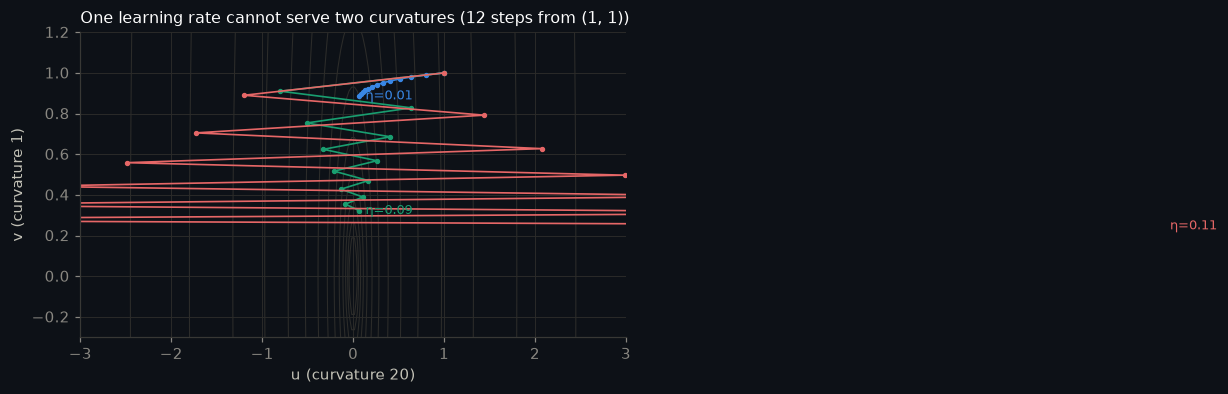

In [8]:
def gd_2d(eta, steps):
    u, v, path = 1.0, 1.0, [(1.0, 1.0)]
    for _ in range(steps):
        u, v = u * (1 - 20 * eta), v * (1 - eta)
        path.append((u, v))
    return np.array(path)


for eta in (0.01, 0.09, 0.11):
    u5, v5 = gd_2d(eta, 5)[-1]
    print(f"eta={eta:.2f}  u multiplier {1 - 20 * eta:+.2f}  v multiplier {1 - eta:.2f}  after 5 steps u={u5:+.3f} v={v5:.3f}")
check(round(gd_2d(0.01, 5)[-1, 1], 3) == 0.951, "eta=0.01: v has barely moved (0.951)")
check(round(gd_2d(0.09, 5)[-1, 1], 3) == 0.624, "eta=0.09: v still slow (0.624) while u overshoots")
check(round(gd_2d(0.11, 5)[-1, 0], 2) == -2.49, "eta=0.11: u has diverged to -2.49")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
uu, vv = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-0.3, 1.2, 200))
ax.contour(uu, vv, 0.5 * (20 * uu**2 + vv**2), levels=np.geomspace(0.02, 60, 14), colors=GRID, linewidths=0.7)
for eta, col in ((0.01, C["blue"]), (0.09, C["aqua"]), (0.11, C["red"])):
    p = gd_2d(eta, 12)
    ax.plot(p[:, 0], p[:, 1], "-o", ms=2.5, color=col, lw=1.1)
    label_end(ax, p[-1, 0], p[-1, 1], f"η={eta}", col)
ax.set(xlim=(-3, 3), ylim=(-0.3, 1.2), xlabel="u (curvature 20)", ylabel="v (curvature 1)",
       title="One learning rate cannot serve two curvatures (12 steps from (1, 1))")
finish(fig, "gd_two_curvatures")

> **Carry forward:** a single learning rate shared by every weight breaks first, because the weights
> do not share a curvature.

### R.2 Momentum: average what is consistent

A weight whose gradient keeps its sign can safely move further than one whose gradient flips. An
exponential moving average stores one number and remembers about $1/(1-\beta_1)$ recent gradients:
$$m \leftarrow \beta_1 m + (1-\beta_1)\,g, \qquad \beta_1 = 0.9 \;\Rightarrow\; \text{about 10 steps of memory}.$$
Along a steep direction the sign flips every step, so the average cancels. Along a shallow direction
it accumulates.

In [9]:
def ema(seq, beta=0.9):
    m, out = 0.0, []
    for g in seq:
        m = beta * m + (1 - beta) * g
        out.append(m)
    return out


steep, shallow = ema([1, -1, 1, -1, 1]), ema([0.2] * 5)
for t, (a, b) in enumerate(zip(steep, shallow), 1):
    print(f"step {t}: alternating ±1 → {a:+.3f}    constant 0.2 → {b:.3f}")
check([round(x, 3) for x in steep] == [0.100, -0.010, 0.091, -0.018, 0.084], "alternating gradients cancel")
check([round(x, 3) for x in shallow] == [0.020, 0.038, 0.054, 0.069, 0.082], "a constant gradient accumulates")
check(abs(steep[-1] - shallow[-1]) < 0.003, "after five steps the two averages are nearly equal despite a 5x gradient gap")

step 1: alternating ±1 → +0.100    constant 0.2 → 0.020
step 2: alternating ±1 → -0.010    constant 0.2 → 0.038
step 3: alternating ±1 → +0.091    constant 0.2 → 0.054
step 4: alternating ±1 → -0.018    constant 0.2 → 0.069
step 5: alternating ±1 → +0.084    constant 0.2 → 0.082
✓ alternating gradients cancel
✓ a constant gradient accumulates
✓ after five steps the two averages are nearly equal despite a 5x gradient gap


> **Carry forward:** an exponential moving average cancels what alternates and accumulates what is
> consistent.

### R.3 A learning rate per parameter

A second average, this time of the squared gradient, estimates how large a parameter's gradients
usually are:
$$v \leftarrow \beta_2 v + (1-\beta_2)\,g^2, \qquad w \leftarrow w - \frac{\eta}{\sqrt{v}}\, g.$$
The quantity $\eta/\sqrt v$ is a learning rate that belongs to that parameter alone. Dividing by
$\sqrt v$ removes the gradient's magnitude and keeps only its sign and its consistency. A rare token's
embedding row, which gets a gradient once in a thousand batches, still takes a full-sized step
when the gradient arrives.

In [10]:
def per_param(g, steps=200, b2=0.999, eta=1.0):
    v = 0.0
    for t in range(1, steps + 1):
        v = b2 * v + (1 - b2) * g * g
    v_hat = v / (1 - b2 ** steps)                               # bias-corrected, see §1
    return math.sqrt(v_hat), eta / math.sqrt(v_hat), eta * g / math.sqrt(v_hat)


for name, g in (("A", 1.0), ("B", 0.01)):
    s, lr_own, step = per_param(g)
    print(f"parameter {name}: gradient {g:.4f}  sqrt(v_hat) {s:.4f}  its own learning rate {lr_own:7.2f} η  step {step:.4f} η")
check(abs(per_param(1.0)[2] - per_param(0.01)[2]) < 1e-9, "gradients 100x apart, identical steps")
check(round(per_param(0.01)[1], 2) == 100.00, "the small-gradient parameter gets a 100x larger learning rate")

parameter A: gradient 1.0000  sqrt(v_hat) 1.0000  its own learning rate    1.00 η  step 1.0000 η
parameter B: gradient 0.0100  sqrt(v_hat) 0.0100  its own learning rate  100.00 η  step 1.0000 η
✓ gradients 100x apart, identical steps
✓ the small-gradient parameter gets a 100x larger learning rate


### R.4 What the optimizer costs in memory

Mixed-precision training keeps five things per weight:
- the bf16 weight (2 bytes)
- its bf16 gradient (2)
- an fp32 master copy (4)
- Adam's $m$ (4)
- Adam's $v$ (4)

That is 16 bytes, and half of it is optimizer state. The fp32 master copy is there because many
updates are smaller than bf16's spacing between neighbouring numbers, especially once the learning
rate has decayed. §5 measures how many.

In [11]:
rules = [("gradient descent", 8), ("with momentum", 12), ("AdamW", 16), ("8-bit AdamW", 10), ("Muon (keeps only m)", 12)]
gib = {name: 9e9 * b / 2**30 for name, b in rules}
for name, b in rules:
    print(f"{name:<22} {b:>2} bytes/weight   9B model: {gib[name]:6.1f} GiB")
check([round(gib[n], 1) for n, _ in rules[:4]] == [67.1, 100.6, 134.1, 83.8], "9B model: 67.1 / 100.6 / 134.1 / 83.8 GiB")

gradient descent        8 bytes/weight   9B model:   67.1 GiB
with momentum          12 bytes/weight   9B model:  100.6 GiB
AdamW                  16 bytes/weight   9B model:  134.1 GiB
8-bit AdamW            10 bytes/weight   9B model:   83.8 GiB
Muon (keeps only m)    12 bytes/weight   9B model:  100.6 GiB
✓ 9B model: 67.1 / 100.6 / 134.1 / 83.8 GiB


### R.5 Batch size and the learning rate

The mean of $N$ independent samples has $1/\sqrt N$ of a single sample's noise. A larger batch
therefore gives a more accurate gradient, and a more accurate gradient can be trusted over a longer
step:
- For SGD the rule is linear: 4× the batch allows 4× the rate.
- For Adam it is the square root: 4× the batch allows 2× the rate, because Adam has already divided
  out the gradient's magnitude.

Accumulation steps and extra GPUs are the same change to the optimizer:
$$\text{global batch} = \text{micro-batch} \times \text{GPUs} \times \text{accumulation steps}.$$
Both rules stop working past the *critical batch size*, beyond which extra samples buy almost
nothing.

In [12]:
rng = np.random.default_rng(0)
print(f"{'batch':>6} {'theory sqrt(8/N)':>17} {'measured':>9}")
for N in (8, 32, 56, 128, 512):
    sd = rng.standard_normal((20000, N)).mean(1).std() / rng.standard_normal((20000, 8)).mean(1).std()
    print(f"{N:>6} {math.sqrt(8 / N):17.3f} {sd:9.3f}")
check(abs(math.sqrt(8 / 56) - 0.378) < 5e-4, "a batch of 56 has 0.378x the noise of a batch of 8")
for change, mult in (("accumulation 1 → 4", 4), ("GPUs 8 → 32", 4), ("both together", 16)):
    print(f"{change:<20} global batch x{mult:<3} → Adam learning rate x{math.sqrt(mult):g}")
check(math.sqrt(16) == 4, "16x the global batch allows 4x the learning rate under Adam (square-root rule)")

 batch  theory sqrt(8/N)  measured
     8             1.000     0.996
    32             0.500     0.501
    56             0.378     0.378
   128             0.250     0.252


   512             0.125     0.124
✓ a batch of 56 has 0.378x the noise of a batch of 8
accumulation 1 → 4   global batch x4   → Adam learning rate x2
GPUs 8 → 32          global batch x4   → Adam learning rate x2
both together        global batch x16  → Adam learning rate x4
✓ 16x the global batch allows 4x the learning rate under Adam (square-root rule)


### R.6 Muon: orthogonalize the update

Adam scales each number in a weight matrix on its own. A matrix maps input directions to output
directions, though, and its momentum matrix is usually dominated by a few large singular values.
Muon replaces the momentum matrix with the nearest matrix whose singular values are all about 1, so
every direction moves by a similar amount. It does this cheaply, with five Newton–Schulz iterations
instead of an SVD.

Muon applies only to 2-D hidden matrices. Embeddings, norm gains and the output head stay on AdamW.
§M tunes both and compares them.

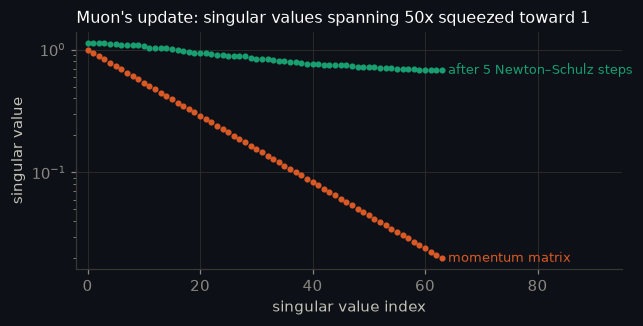

singular values before: 1.000 … 0.020 (ratio 50x)
after Newton–Schulz:    1.134 … 0.682 (ratio 1.66x)
✓ five Newton–Schulz steps bring every singular value into [0.5, 1.5]


In [13]:
def newton_schulz5(G, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
    a, b, c = coeffs
    X = G / (G.norm() + 1e-7)
    tall = X.shape[0] > X.shape[1]
    if tall:
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if tall else X


torch.manual_seed(0)
U, _ = torch.linalg.qr(torch.randn(256, 64, dtype=torch.float64))
V, _ = torch.linalg.qr(torch.randn(64, 64, dtype=torch.float64))
s = torch.logspace(0, math.log10(0.02), 64, dtype=torch.float64)          # singular values 1 … 0.02
G = U @ torch.diag(s) @ V.T
s_after = torch.linalg.svdvals(newton_schulz5(G))
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.semilogy(s.numpy(), "o", ms=3, color=C["orange"]); label_end(ax, 63, s[-1].item(), "momentum matrix", C["orange"])
ax.semilogy(s_after.numpy(), "o", ms=3, color=C["aqua"]); label_end(ax, 63, s_after[-1].item(), "after 5 Newton–Schulz steps", C["aqua"])
ax.set(xlabel="singular value index", ylabel="singular value", xlim=(-2, 95),
       title="Muon's update: singular values spanning 50x squeezed toward 1")
finish(fig, "muon_orthogonalize")
print(f"singular values before: {s.max():.3f} … {s.min():.3f} (ratio {s.max() / s.min():.0f}x)")
print(f"after Newton–Schulz:    {s_after.max():.3f} … {s_after.min():.3f} (ratio {s_after.max() / s_after.min():.2f}x)")
check(s_after.min() > 0.5 and s_after.max() < 1.5, "five Newton–Schulz steps bring every singular value into [0.5, 1.5]")

> **Carry forward:** momentum fixes direction, a per-parameter scale fixes size, the batch sets how
> much the gradient can be trusted, and Muon treats a matrix as a matrix. Adam, next, is the first
> two together.

## §1 One weight, five gradients: Adam by hand

**Intuition.** Adam keeps two running averages per weight:
- The first, $m$, is the average gradient. It sets the **direction**.
- The second, $v$, is the average squared gradient. It sets the **scale**.

Their ratio is close to $\pm1$ whenever the gradients agree. So every weight moves by about $\eta$,
whatever its gradient's size. The gradient decides the direction and the learning rate decides the
distance.

**Math.** With $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$, at step $t$:
$$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1-\beta_1)\,g_t, &
v_t &= \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2,\\
\hat m_t &= \frac{m_t}{1-\beta_1^t}, &
\hat v_t &= \frac{v_t}{1-\beta_2^t},\\
\Delta w_t &= -\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.
\end{aligned}
$$

The hats are **bias correction**. Both averages start at zero, so early on they read too low. A
constant gradient $g$ gives $m_t = g(1-\beta_1^t)$ exactly, and dividing by $1-\beta_1^t$ undoes
that. The same holds for $v$. §2 switches the correction off.

The worked example: one weight at $w_0 = 1$, $\eta = 10^{-3}$, gradients 0.50, 0.40, 0.60, 0.45,
0.55. We compute it three ways:
1. **Exactly**, with 50-digit decimals. This is the reference.
2. **By hand** in ordinary floats, the five lines above.
3. **With `torch.optim.Adam`**, reading its internal state after every step.

The same check exists as a standalone script, `adam_by_hand.py`. It exits with code 1 on any
mismatch.

In [14]:
GRADS = [0.50, 0.40, 0.60, 0.45, 0.55]
LR1, BETA1, BETA2, EPS, W0 = 1e-3, 0.9, 0.999, 1e-8, 1.0
FIELDS = ("m", "v", "m_hat", "v_hat", "step", "w")


def adam_exact(grads=GRADS):
    """The reference: every operation in 50-digit decimal arithmetic."""
    D = decimal.Decimal
    decimal.getcontext().prec = 50
    b1, b2, lr, eps = D("0.9"), D("0.999"), D("0.001"), D("1e-8")
    w, m, v, rows = D(1), D(0), D(0), []
    for t, g in enumerate(grads, 1):
        g = D(str(g))
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        m_hat, v_hat = m / (1 - b1 ** t), v / (1 - b2 ** t)
        step = -lr * m_hat / (v_hat.sqrt() + eps)
        w += step
        rows.append(dict(m=m, v=v, m_hat=m_hat, v_hat=v_hat, step=step, w=w))
    return rows


def adam_by_hand(grads=GRADS, bias_correction=True, b1=BETA1, b2=BETA2, lr=LR1, eps=EPS, w0=W0):
    """The five lines, in ordinary floats."""
    w, m, v, rows = w0, 0.0, 0.0, []
    for t, g in enumerate(grads, 1):
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        m_hat = m / (1 - b1 ** t) if bias_correction else m
        v_hat = v / (1 - b2 ** t) if bias_correction else v
        step = -lr * m_hat / (math.sqrt(v_hat) + eps)
        w += step
        rows.append(dict(m=m, v=v, m_hat=m_hat, v_hat=v_hat, step=step, w=w))
    return rows


ref = adam_exact()
hand = adam_by_hand()
print(f"{'t':>2} {'g':>5} {'m':>8} {'v':>9} {'m_hat':>7} {'v_hat':>7} {'step':>10} {'w':>9}")
for t, (g, r) in enumerate(zip(GRADS, hand), 1):
    print(f"{t:>2} {g:5.2f} {r['m']:8.4f} {r['v']:9.6f} {r['m_hat']:7.4f} {r['v_hat']:7.4f} {r['step']:10.6f} {r['w']:9.6f}")

# The standard worked table, to the digits it is usually printed with:
PRINTED = dict(m=[0.0500, 0.0850, 0.1365, 0.1678, 0.2061], v=[0.000250, 0.000410, 0.000769, 0.000971, 0.001273],
               m_hat=[0.5000, 0.4474, 0.5037, 0.4881, 0.5032], v_hat=[0.2500, 0.2050, 0.2567, 0.2431, 0.2550],
               step=[-0.001000, -0.000988, -0.000994, -0.000990, -0.000996],
               w=[0.999000, 0.998012, 0.997018, 0.996028, 0.995031])
DIGITS = dict(m=4, v=6, m_hat=4, v_hat=4, step=6, w=6)
check(all(round(r[f], DIGITS[f]) == PRINTED[f][i] for i, r in enumerate(hand) for f in FIELDS),
      "the hand computation reproduces the worked table to every printed digit")
worst = max(abs(r["step"] + LR1) for r in hand) / LR1
check(worst < 0.015, f"every step is within {worst:.1%} of η, although the gradients range from 0.40 to 0.60 (±20%)")

 t     g        m         v   m_hat   v_hat       step         w
 1  0.50   0.0500  0.000250  0.5000  0.2500  -0.001000  0.999000
 2  0.40   0.0850  0.000410  0.4474  0.2050  -0.000988  0.998012
 3  0.60   0.1365  0.000769  0.5037  0.2567  -0.000994  0.997018
 4  0.45   0.1678  0.000971  0.4881  0.2431  -0.000990  0.996028
 5  0.55   0.2061  0.001273  0.5032  0.2550  -0.000996  0.995031
✓ the hand computation reproduces the worked table to every printed digit
✓ every step is within 1.2% of η, although the gradients range from 0.40 to 0.60 (±20%)


**The same five steps in PyTorch.** `torch.optim.Adam` stores exactly two tensors per weight:
- `exp_avg`, which is $m$
- `exp_avg_sq`, which is $v$

plus the step count. These are the "two values per weight" counted in R.4.

It never stores $\hat m$ or $\hat v$. It folds both corrections into the step instead:
$$\Delta w = -\frac{\eta}{1-\beta_1^t}\cdot\frac{m}{\sqrt{v}/\sqrt{1-\beta_2^t}+\epsilon},$$
which is the textbook formula rearranged. So $\hat m$ and $\hat v$ are derived below from the stored
state, and the step is read as $w_\text{after} - w_\text{before}$.

In [15]:
def adam_torch(grads=GRADS, dtype=torch.float64, device="cpu", **impl):
    p = torch.nn.Parameter(torch.tensor([W0], dtype=dtype, device=device))
    opt = torch.optim.Adam([p], lr=LR1, betas=(BETA1, BETA2), eps=EPS, **impl)
    rows = []
    for g in grads:
        before = p.detach().clone()
        p.grad = torch.tensor([g], dtype=dtype, device=device)
        opt.step()
        st = opt.state[p]
        t = int(st["step"])
        m, v = st["exp_avg"].item(), st["exp_avg_sq"].item()
        rows.append(dict(m=m, v=v, m_hat=m / (1 - BETA1 ** t), v_hat=v / (1 - BETA2 ** t),
                         step=(p.detach() - before).item(), w=p.item()))
    return rows


IMPLS = [("by hand, float64", lambda: adam_by_hand(), 1e-12),
         ("torch float64, for-loop", lambda: adam_torch(foreach=False), 1e-12),
         ("torch float64, foreach", lambda: adam_torch(foreach=True), 1e-12),
         ("torch float32, for-loop", lambda: adam_torch(dtype=torch.float32, foreach=False), 1e-6),
         ("torch float32, foreach", lambda: adam_torch(dtype=torch.float32, foreach=True), 1e-6)]
if DEV == "cuda":
    IMPLS += [("torch float64, fused CUDA", lambda: adam_torch(device="cuda", fused=True), 1e-12),
              ("torch float32, fused CUDA", lambda: adam_torch(dtype=torch.float32, device="cuda", fused=True), 1e-5)]

# Step by step, side by side: the hand computation and PyTorch's own numbers (float32, the default dtype).
torch_rows = adam_torch(dtype=torch.float32, foreach=False)
print(f"{'t':>2} {'':<8}" + "".join(f"{f:>13}" for f in FIELDS))
for t, (h, p) in enumerate(zip(hand, torch_rows), 1):
    print(f"{t:>2} {'by hand':<8}" + "".join(f"{h[f]:13.8f}" for f in FIELDS))
    print(f"{'':>2} {'PyTorch':<8}" + "".join(f"{p[f]:13.8f}" for f in FIELDS))
agree = min(int(-math.log10(max(abs(h[f] - p[f]) for h, p in zip(hand, torch_rows)) + 1e-30)) for f in FIELDS)
print(f"every quantity at every step agrees to at least {agree} decimal places (float32 PyTorch vs float64 by hand)\n")
check(agree >= 6, f"hand and PyTorch agree to {agree} decimal places on m, v, m̂, v̂, the step and w at every step")

diffs = {}
print("largest |difference| from the 50-digit reference over the five steps:")
print(f"{'implementation':<27}" + "".join(f"{f:>9}" for f in FIELDS) + "  tolerance")
for name, fn, tol in IMPLS:
    rows = fn()
    diffs[name] = {f: max(abs(float(r[f]) - float(e[f])) for r, e in zip(rows, ref)) for f in FIELDS}
    print(f"{name:<27}" + "".join(f"{diffs[name][f]:9.1e}" for f in FIELDS) + f"  {tol:.0e}")
for name, _, tol in IMPLS:
    check(max(diffs[name].values()) <= tol, f"{name}: every quantity within {tol:.0e} of the exact value")
if MODE != "learn":
    ANS["adam_by_hand"] = _clean(dict(table=[{k: float(v) for k, v in r.items()} for r in ref], grads=GRADS,
                                      torch_rows=torch_rows, agree_decimals=agree,
                                      diffs=diffs, tolerances={n: t for n, _, t in IMPLS}), sig=8)
    save_results()

 t                     m            v        m_hat        v_hat         step            w
 1 by hand    0.05000000   0.00025000   0.50000000   0.25000000  -0.00100000   0.99900000
   PyTorch    0.05000000   0.00025000   0.50000001   0.25000001  -0.00099999   0.99900001
 2 by hand    0.08500000   0.00040975   0.44736842   0.20497749  -0.00098813   0.99801187
   PyTorch    0.08500000   0.00040975   0.44736843   0.20497751  -0.00098813   0.99801189
 3 by hand    0.13650000   0.00076934   0.50369004   0.25670337  -0.00099414   0.99701773
   PyTorch    0.13650000   0.00076934   0.50369004   0.25670339  -0.00099415   0.99701774
 4 by hand    0.16785000   0.00097107   0.48807793   0.24313218  -0.00098985   0.99602789
   PyTorch    0.16785000   0.00097107   0.48807794   0.24313219  -0.00098985   0.99602789
 5 by hand    0.20606500   0.00127260   0.50319895   0.25502952  -0.00099642   0.99503146
   PyTorch    0.20606500   0.00127260   0.50319894   0.25502953  -0.00099641   0.99503148
every quan

Every implementation agrees with the exact reference. float64 agrees to rounding error (~1e-16),
and the float32 loop and foreach kernels to ~1e-8. The fused CUDA kernel in float32 is the
exception: its $v$ differs by about 1e-5 *relative*, which shows up as ~3e-6 in $\hat v$, while its
step and weight still agree to 1e-8.

The cause is one subtraction. The fused kernel computes $1-\beta_2$ in float32. float32 cannot
represent 0.999 exactly, and subtracting it from 1 leaves an error of about 1.3e-5 relative. The
loop kernels compute $1-\beta_2$ in Python's float64 instead.

The step escapes the error because the kernel's own bias correction, $1-\beta_2^t$, uses the same
float32 $\beta_2$. Inside the kernel, $v/(1-\beta_2^t)$ is therefore still a properly normalised
average. The 3e-6 appears only in the $\hat v$ derived here from the stored $v$ with the exact
$\beta_2$.

In [16]:
one_minus_b2_f32 = float(np.float32(1.0) - np.float32(0.999))
rel = abs(one_minus_b2_f32 - 0.001) / 0.001
print(f"1 - 0.999 in float32 = {one_minus_b2_f32:.10f}   relative error {rel:.2e}")
check(1e-5 < rel < 2e-5, "float32 computes 1 - 0.999 with a relative error of about 1.3e-5")
if DEV == "cuda":
    fused = adam_torch(dtype=torch.float32, device="cuda", fused=True)
    v_rel = max(abs(r["v"] - float(e["v"])) / float(e["v"]) for r, e in zip(fused, ref))
    observe("fused_fp32_v_error", abs(v_rel - rel) / rel < 0.2,
            f"the fused kernel's v is off by {v_rel:.2e} relative, the same size as float32's 1 - 0.999 error")

1 - 0.999 in float32 = 0.0009999871   relative error 1.29e-05
✓ float32 computes 1 - 0.999 with a relative error of about 1.3e-5
✓ observed: the fused kernel's v is off by 1.29e-05 relative, the same size as float32's 1 - 0.999 error


**How large can one Adam step be?** "About $\eta$" is a typical value, not a bound. The paper that
introduced Adam gives the bound:
$$|\Delta w| \le \eta\cdot\max\!\Big(1,\; \frac{1-\beta_1}{\sqrt{1-\beta_2}}\Big).$$
With $\beta_2 = 0.999$ that is $3.16\,\eta$. With $\beta_2 = 0.95$ it is $\eta$.

The bound is reached in exactly one situation: a parameter whose gradient has been **zero for a
long time** suddenly receives one. Then $m$ jumps to $0.1g$ while $v$ is only $0.001g^2$. This is
the rare-token case. An embedding row for a word seen once in ten thousand batches takes the
largest step any weight in the model can take, at the moment it is least informed. After a
*short* silence the opposite happens: the step is smaller than $\eta$. The correction treats the
zeros as real gradients and divides by a $1-\beta^t$ that is still small.

In [17]:
def step_after_silence(gap, b1=0.9, b2=0.999, g=1.0, eps=EPS):
    """Gradients are zero for `gap` steps, then one gradient g arrives (bias-corrected Adam)."""
    t = gap + 1
    m, v = (1 - b1) * g, (1 - b2) * g * g                    # zeros contributed nothing
    return (m / (1 - b1 ** t)) / (math.sqrt(v / (1 - b2 ** t)) + eps)


print(f"{'zero-gradient steps before':>27} {'step / η, β2=0.999':>19} {'step / η, β2=0.95':>18}")
for gap in (0, 10, 100, 1000, 10000):
    print(f"{gap:>27} {step_after_silence(gap):19.3f} {step_after_silence(gap, b2=0.95):18.3f}")
check(abs(step_after_silence(10**6) - 0.1 / math.sqrt(0.001)) < 1e-3, "after a long silence the step approaches 3.16 η (β2=0.999)")
check(step_after_silence(10**6, b2=0.95) <= 1.0, "with β2 = 0.95 even the rare-token step stays at or below η")

 zero-gradient steps before  step / η, β2=0.999  step / η, β2=0.95
                          0               1.000              1.000
                         10               0.482              0.428
                        100               0.980              0.446
                       1000               2.515              0.447
                      10000               3.162              0.447
✓ after a long silence the step approaches 3.16 η (β2=0.999)
✓ with β2 = 0.95 even the rare-token step stays at or below η


**Weight decay: why AdamW exists.** L2 regularization adds $\tfrac12\lambda w^2$ to the loss, so
$\lambda w$ joins the gradient. Inside Adam that term gets divided by $\sqrt{\hat v}$ along with
everything else, so the decay a weight receives depends on its gradient history:
- Two weights at $w = 0.5$, $\lambda = 0.1$, $\eta = 10^{-3}$.
- One has $\sqrt{\hat v} = 1$, the other $\sqrt{\hat v} = 0.01$.
- L2 shrinks them by $5\times10^{-5}$ and $5\times10^{-3}$ per step.

AdamW applies the decay *after* the Adam step, where nothing divides it:
$$w \leftarrow w - \eta\frac{\hat m}{\sqrt{\hat v}+\epsilon} - \eta\lambda w.$$
Both weights then shrink by $\eta\lambda w = 5\times10^{-5}$.

A sharper way to see the L2 problem: with **no** loss gradient, L2-in-Adam turns the decay term
into a sign, so every weight shrinks by $\eta$ whatever its size. Decoupled decay shrinks each
weight in proportion to itself.

In [18]:
lam = 0.1
for name, sq in (("A", 1.00), ("B", 0.01)):
    print(f"parameter {name}: sqrt(v_hat)={sq:.2f}   L2 shrink {LR1 * lam * 0.5 / sq:.1e}   decoupled shrink {LR1 * lam * 0.5:.1e}")
check(math.isclose(LR1 * lam * 0.5 / 0.01, 5e-3) and math.isclose(LR1 * lam * 0.5, 5e-5),
      "L2 decays the small-gradient weight 100x harder; decoupled decay treats both the same")


def one_decay_step(opt_cls, w):
    p = torch.nn.Parameter(torch.tensor([w], dtype=torch.float64))
    opt = opt_cls([p], lr=LR1, weight_decay=lam, foreach=False)
    p.grad = torch.zeros_like(p)                         # no loss gradient at all: only the decay acts
    opt.step()
    return w - p.item()


for w in (0.5, 0.05):
    print(f"w={w}:  Adam with L2 shrinks by {one_decay_step(torch.optim.Adam, w):.2e}   "
          f"AdamW shrinks by {one_decay_step(torch.optim.AdamW, w):.2e}")
check(all(abs(one_decay_step(torch.optim.Adam, w) - LR1) < 1e-6 for w in (0.5, 0.05)),
      "L2 inside Adam shrinks every weight by η regardless of its size")
check(all(abs(one_decay_step(torch.optim.AdamW, w) - LR1 * lam * w) < 1e-15 for w in (0.5, 0.05)),
      "AdamW shrinks each weight by exactly ηλw")

parameter A: sqrt(v_hat)=1.00   L2 shrink 5.0e-05   decoupled shrink 5.0e-05
parameter B: sqrt(v_hat)=0.01   L2 shrink 5.0e-03   decoupled shrink 5.0e-05
✓ L2 decays the small-gradient weight 100x harder; decoupled decay treats both the same
w=0.5:  Adam with L2 shrinks by 1.00e-03   AdamW shrinks by 5.00e-05
w=0.05:  Adam with L2 shrinks by 1.00e-03   AdamW shrinks by 5.00e-06
✓ L2 inside Adam shrinks every weight by η regardless of its size
✓ AdamW shrinks each weight by exactly ηλw


> **Carry forward:** Adam moves every weight by about $\eta$, at most $3.16\,\eta$ with
> $\beta_2=0.999$, and it hits that maximum on rare tokens. PyTorch matches the hand computation to
> rounding error, except for a 1e-5 relative wobble in the fused float32 kernel's $v$. Decay
> belongs outside the Adam ratio.

## §2 Bias correction off: the first twenty steps

**Intuition.** Both averages start at zero, but they recover at very different speeds. $m$ forgets
its zero start in about 10 steps ($\beta_1 = 0.9$). $v$ takes about 1,000 ($\beta_2 = 0.999$). Without
correction, $v$ reads far too low for far longer than $m$ does. Dividing by $\sqrt{v}$ then makes the
step too **large**, not too small.

**Math.** The corrections are plain scalars, so the uncorrected step divided by the corrected step
is the same for every gradient sequence ($\epsilon$ aside):
$$f(t) \;=\; \frac{m_t/\sqrt{v_t}}{\hat m_t/\sqrt{\hat v_t}} \;=\; \frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}}.$$
At $t=1$, $f = 0.1/\sqrt{0.001} = 3.16$. The first step without correction is 3.16 times too large.

"When does the difference stop mattering?" has a precise answer: the first step after which
$|f(t) - 1|$ stays below a threshold for good. The rule fixed in §0 uses 1%.

✓ measured step ratio equals (1-β1^t)/sqrt(1-β2^t) at every step (ε shifts it by < 1e-5)


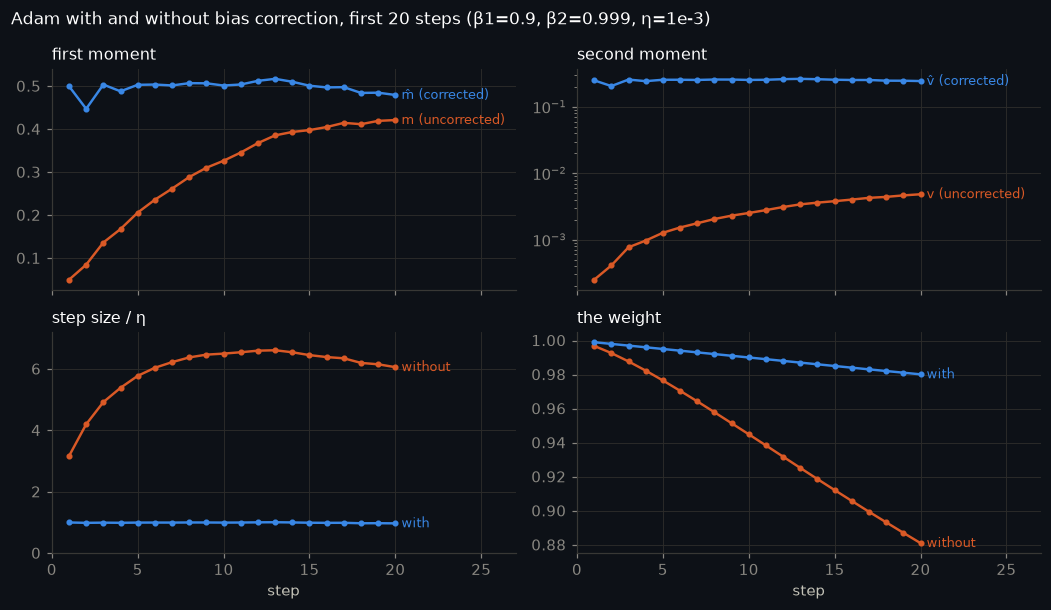

step/η without correction: t=1 3.16, peak 6.57 at t=12, t=20 6.24
after 20 steps the weight is at 0.88104 without correction vs 0.98014 with: 6.0x as far from where it started
✓ the first uncorrected step is 3.16 η
✓ at step 20 the gap is wider than at step 1: it has not started closing


In [19]:
rng = np.random.default_rng(0)
G20 = GRADS + list(np.round(0.5 + 0.05 * rng.standard_normal(15), 3))      # the five above, then 15 more around 0.5
on, off = adam_by_hand(G20, True), adam_by_hand(G20, False)
t20 = np.arange(1, 21)
f_closed = (1 - BETA1 ** t20) / np.sqrt(1 - BETA2 ** t20)
f_measured = np.array([b["step"] / a["step"] for a, b in zip(on, off)])
check(np.max(np.abs(f_measured / f_closed - 1)) < 1e-5, "measured step ratio equals (1-β1^t)/sqrt(1-β2^t) at every step (ε shifts it by < 1e-5)")

fig, axs = plt.subplots(2, 2, figsize=(9.6, 5.6), sharex=True)
panels = [("m", "m_hat", "first moment", "m (uncorrected)", "m̂ (corrected)"),
          ("v", "v_hat", "second moment", "v (uncorrected)", "v̂ (corrected)")]
for ax, (raw, hat, title, l1, l2) in zip(axs[0], panels):
    ax.plot(t20, [r[raw] for r in on], "-o", ms=3, color=C["orange"]); label_end(ax, 20, on[-1][raw], l1, C["orange"])
    ax.plot(t20, [r[hat] for r in on], "-o", ms=3, color=C["blue"]); label_end(ax, 20, on[-1][hat], l2, C["blue"])
    ax.set(title=title, xlim=(0, 27))
axs[0, 1].set_yscale("log")
ax = axs[1, 0]
ax.plot(t20, [-r["step"] / LR1 for r in off], "-o", ms=3, color=C["orange"]); label_end(ax, 20, -off[-1]["step"] / LR1, "without", C["orange"])
ax.plot(t20, [-r["step"] / LR1 for r in on], "-o", ms=3, color=C["blue"]); label_end(ax, 20, -on[-1]["step"] / LR1, "with", C["blue"])
ax.set(title="step size / η", xlabel="step", ylim=(0, 7.2))
ax = axs[1, 1]
ax.plot(t20, [r["w"] for r in off], "-o", ms=3, color=C["orange"]); label_end(ax, 20, off[-1]["w"], "without", C["orange"])
ax.plot(t20, [r["w"] for r in on], "-o", ms=3, color=C["blue"]); label_end(ax, 20, on[-1]["w"], "with", C["blue"])
ax.set(title="the weight", xlabel="step")
fig.suptitle("Adam with and without bias correction, first 20 steps (β1=0.9, β2=0.999, η=1e-3)", color=INK, x=0.01, ha="left")
fig.tight_layout()
finish(fig, "bias_correction_first20")
print(f"step/η without correction: t=1 {f_closed[0]:.2f}, peak {f_closed.max():.2f} at t={t20[f_closed.argmax()]}, t=20 {f_closed[-1]:.2f}")
print(f"after 20 steps the weight is at {off[-1]['w']:.5f} without correction vs {on[-1]['w']:.5f} with: "
      f"{(1 - off[-1]['w']) / (1 - on[-1]['w']):.1f}x as far from where it started")
check(round(f_closed[0], 2) == 3.16, "the first uncorrected step is 3.16 η")
check(f_closed[-1] > f_closed[0], "at step 20 the gap is wider than at step 1: it has not started closing")

Within the first twenty steps the difference **grows**. It rises from 3.16× at step 1 to a peak near
step 12, because $m$ recovers in tens of steps while $v$ needs thousands. Twenty steps is far too
early to call. The same closed form, carried out to 100,000 steps for several $\beta_2$:

    β2  memory 1/(1-β2)    t=1         peak   steps until within  1%  5%  10%
  0.95               20   0.45   1.10 @ t=20        76     43      6
  0.98               50   0.71   1.55 @ t=14       195    118     87
  0.99              100   1.00   2.13 @ t=13       391    237    175
 0.999             1000   3.16   6.57 @ t=12      3925   2375   1751
split for β2=0.999 at 1%: the m correction stops mattering after 44 steps, the v correction after 3925
✓ with β2=0.999 the v correction, not m, sets how long bias correction matters


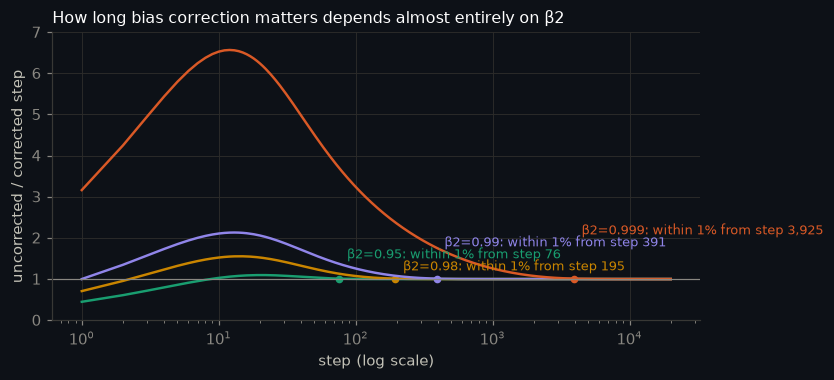

In [20]:
T_LONG = np.arange(1, 200_001)


def multiplier(b2, b1=BETA1, t=T_LONG):
    return (1 - b1 ** t) / np.sqrt(1 - b2 ** t)


def stop_step(dev, p):
    """First step after which |dev| < p for every later step (dev indexed from t = 1)."""
    bad = np.nonzero(np.abs(dev) >= p)[0]
    return int(bad[-1]) + 2 if bad.size else 1


BC_STOP = {}
print(f"{'β2':>6} {'memory 1/(1-β2)':>16} {'t=1':>6} {'peak':>12}   steps until within  " + "  ".join(f"{p:.0%}" for p in RULES["bias_correction_stop"]["p"]))
for b2 in (0.95, 0.98, 0.99, 0.999):
    f = multiplier(b2)
    stops = {p: stop_step(f - 1, p) for p in RULES["bias_correction_stop"]["p"]}
    BC_STOP[b2] = stops
    print(f"{b2:>6} {1 / (1 - b2):16.0f} {f[0]:6.2f} {f.max():6.2f} @ t={f.argmax() + 1:<4}   " +
          "  ".join(f"{stops[p]:>5}" for p in RULES["bias_correction_stop"]["p"]))
m_part = stop_step(-(BETA1 ** T_LONG), 0.01)
v_part = stop_step(1 / np.sqrt(1 - 0.999 ** T_LONG) - 1, 0.01)
print(f"split for β2=0.999 at 1%: the m correction stops mattering after {m_part} steps, the v correction after {v_part}")
check(abs(BC_STOP[0.999][0.01] - v_part) <= 2 and v_part > 50 * m_part, "with β2=0.999 the v correction, not m, sets how long bias correction matters")

fig, ax = plt.subplots(figsize=(7.6, 3.4))
for b2, col in zip((0.95, 0.98, 0.99, 0.999), (C["aqua"], C["yellow"], C["violet"], C["orange"])):
    f = multiplier(b2)[:20000]
    ax.semilogx(T_LONG[:20000], f, color=col)
    s1 = BC_STOP[b2][0.01]
    ax.plot(s1, f[s1 - 1], "o", ms=4, color=col)
    label_end(ax, s1, f[s1 - 1], f"β2={b2}: within 1% from step {s1:,}", col, dx=5, dy=8)
ax.axhline(1, color=MUTED, lw=0.8)
ax.set(xlabel="step (log scale)", ylabel="uncorrected / corrected step", ylim=(0, 7),
       title="How long bias correction matters depends almost entirely on β2")
finish(fig, "bias_correction_long")

**The per-step ratio converges, but the displacement does not.** With consistently signed gradients,
every uncorrected step overshoots by $(f(t)-1)\,\eta$, and those overshoots add up. The total is the
extra distance the weight has travelled by the time the ratio has converged. That distance is never
taken back.

In [21]:
for b2 in (0.95, 0.999):
    excess = np.sum(multiplier(b2) - 1)
    print(f"β2={b2}: cumulative extra displacement {excess:+.0f} η (consistent gradients, upper bound)")
EXCESS_0999 = float(np.sum(multiplier(0.999) - 1))
check(EXCESS_0999 > 1000, "with β2=0.999, switching bias correction off adds over a thousand η of displacement")

β2=0.95: cumulative extra displacement +2 η (consistent gradients, upper bound)
β2=0.999: cumulative extra displacement +1213 η (consistent gradients, upper bound)
✓ with β2=0.999, switching bias correction off adds over a thousand η of displacement


**Where ε starts to matter.** $\epsilon = 10^{-8}$ is added to $\sqrt{v}$. Uncorrected,
$\sqrt{v_1} = 0.0316\,|g|$ at the first step, so ε competes with gradients 30× larger than it does
with correction. This matters for weights whose gradients are tiny, as in many real layers.

In [22]:
print(f"{'|g|':>8} {'step/η with correction':>23} {'without':>9}")
for g in (1e-2, 1e-4, 1e-6, 1e-7, 1e-8):
    with_bc = g / (g + EPS)
    without = 0.1 * g / (math.sqrt(0.001) * g + EPS)
    print(f"{g:8.0e} {with_bc:23.3f} {without:9.3f}")
on_1e7, off_1e7 = 1e-7 / (1e-7 + EPS), 0.1 * 1e-7 / (math.sqrt(0.001) * 1e-7 + EPS)
check(on_1e7 > 0.9 and off_1e7 < 1.0, "at |g| = 1e-7, ε already cancels the uncorrected 3.16x overshoot")

     |g|  step/η with correction   without
   1e-02                   1.000     3.162
   1e-04                   1.000     3.152
   1e-06                   0.990     2.403
   1e-07                   0.909     0.760
   1e-08                   0.500     0.097
✓ at |g| = 1e-7, ε already cancels the uncorrected 3.16x overshoot


### Two fixes that are often confused

*Bias correction* and *decoupled weight decay* (the "W" in AdamW) are separate fixes for separate
problems:

| fix | problem it solves | what switching it off does |
|---|---|---|
| bias correction ($\hat m$, $\hat v$) | both averages start at zero | early steps are up to 6.6× too large (β2 = 0.999) |
| decoupled decay (AdamW) | L2 decay gets divided by $\sqrt{\hat v}$ | how much a weight decays depends on its gradient history |

Below, the same weight ($w_0 = 1$, $\lambda = 0.1$, the 20 gradients above) is run four ways, each
fix toggled separately.

In [23]:
def adam_variant(grads, bias_correction, decoupled, lam=0.1, b1=BETA1, b2=BETA2, lr=LR1):
    w, m, v, ws = 1.0, 0.0, 0.0, []
    for t, g in enumerate(grads, 1):
        if decoupled:
            w -= lr * lam * w                                   # AdamW: decay first, outside the ratio
        else:
            g = g + lam * w                                     # L2: decay joins the gradient
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        mh, vh = (m / (1 - b1 ** t), v / (1 - b2 ** t)) if bias_correction else (m, v)
        w -= lr * mh / (math.sqrt(vh) + EPS)
        ws.append(w)
    return ws


variants = {(bc, dec): adam_variant(G20, bc, dec) for bc in (True, False) for dec in (True, False)}
print(f"{'':<26}{'decoupled (AdamW)':>18}{'L2 (Adam)':>12}")
for bc in (True, False):
    print(f"{'bias correction ' + ('on' if bc else 'off'):<26}{1 - variants[(bc, True)][-1]:18.5f}{1 - variants[(bc, False)][-1]:12.5f}   ← distance moved in 20 steps")
d_bc = abs(variants[(False, True)][-1] - variants[(True, True)][-1])
d_dec = abs(variants[(True, False)][-1] - variants[(True, True)][-1])
print(f"switching bias correction off moves w by {d_bc:.2e}; switching decoupling off moves it by {d_dec:.2e}")
check(d_bc > 10 * d_dec, "over the first 20 steps bias correction matters far more than how decay is applied")

                           decoupled (AdamW)   L2 (Adam)
bias correction on                   0.02184     0.01990   ← distance moved in 20 steps
bias correction off                  0.12085     0.11904   ← distance moved in 20 steps
switching bias correction off moves w by 9.90e-02; switching decoupling off moves it by 1.94e-03
✓ over the first 20 steps bias correction matters far more than how decay is applied


> **Carry forward:** without bias correction, early Adam steps are up to 6.6× too large at
> $\beta_2=0.999$, and the gap *widens* over the first dozen steps. It is within 1% only after
> ~3,900 steps, or ~76 at $\beta_2 = 0.95$. The weights keep the extra displacement for good. §4
> measures what that does to a real model's loss.

## §3 The testbed

Every training experiment from here on uses the pieces defined in this section. Each piece is
built so that comparisons between runs are **paired**: two runs with the same seed start from the
same weights and see the same batches in the same order. Any difference between them then comes
from the one setting that changed.

**Data.**
- TinyStories (GPT-4 version), tokenized with the SmolLM2 tokenizer (49,152 tokens).
- The token stream is cut into non-overlapping windows. A seed fixes a permutation of those
  windows, so no window repeats within a run.
- Validation loss always uses the same fixed set of held-out windows.

**Two model families.**
| | base model | width family |
|---|---|---|
| used in | §4, §5, §6, §M | §7 |
| shape | width 384, 8 layers, 6 query / 2 key-value heads (GQA), SwiGLU 1024, RoPE | width 256…2,048, 4 layers, head size 64, SwiGLU ≈ 8/3·width |
| vocabulary | 49,152, tied input/output embedding | the 8,191 most frequent ids + one "other" id, untied |
| initialization | GPT-2 style: N(0, 0.02), residual projections scaled by 1/√(2·layers) | standard parameterization: N(0, 1/fan_in), embedding N(0, 1) |
| parameters | 31.5M | 7M … 234M |
| tokens per step | 32 × 512 = 16,384 | 64 × 256 = 16,384 |

The width family predicts only the most frequent ids, so that width rather than a 49k-row
embedding dominates its parameter count.

**Training.**
- Optimizer: AdamW with $\beta=(0.9, 0.95)$, $\epsilon=10^{-8}$, weight decay 0.1 on matrices only
  (not on norm gains).
- Clipping: gradient norm 1.0.
- Precision: bf16 autocast with fp32 master weights.
- Logging, on every step that is logged:
  - loss, learning rate, gradient norm, whether clipping fired
  - each tensor's update-to-weight ratio $\lVert\Delta W\rVert/\lVert W\rVert$

In [24]:
TRAIN_URL = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-train.txt"
VALID_URL = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt"
TOK_URL = "https://huggingface.co/HuggingFaceTB/SmolLM2-135M/resolve/main/tokenizer.json"
TRAIN_MB, VALID_MB = qk(60, 5), qk(8, 2)
EOT = 0                                         # <|endoftext|> in the SmolLM2 vocabulary
V_BASE, V_WIDTH = 49152, 8192


def fetch(url, dest, max_bytes=None, tries=12):
    """Resumable download into dest.part using HTTP Range requests (large downloads do drop)."""
    dest = Path(dest)
    if dest.exists():
        return dest
    part = dest.with_name(dest.name + ".part")
    for attempt in range(tries):
        have = part.stat().st_size if part.exists() else 0
        if max_bytes and have >= max_bytes:
            break
        req = urllib.request.Request(url, headers={"User-Agent": "python-urllib",
                                                   "Range": f"bytes={have}-{max_bytes - 1 if max_bytes else ''}"})
        try:
            with urllib.request.urlopen(req, timeout=60) as r, open(part, "ab") as f:
                if r.status == 200 and have:            # the server ignored Range: start over
                    f.truncate(0)
                while chunk := r.read(1 << 20):
                    f.write(chunk)
            if not max_bytes:
                break
        except urllib.error.HTTPError as e:
            if e.code == 416:                           # nothing left to send
                break
            print(f"  download error ({e}); retrying"); time.sleep(min(30, 2 ** attempt))
        except Exception as e:
            print(f"  download error ({e}); retrying"); time.sleep(min(30, 2 ** attempt))
    else:
        raise RuntimeError(f"could not download {url}")
    if max_bytes and part.stat().st_size > max_bytes:
        with open(part, "r+b") as f:
            f.truncate(max_bytes)
    part.replace(dest)
    return dest


def load_tokens(split):
    mb = TRAIN_MB if split == "train" else VALID_MB
    cache = DATA / f"{split}_{mb}mb.npy"
    if cache.exists():
        return np.load(cache)
    url = TRAIN_URL if split == "train" else VALID_URL
    text = fetch(url, DATA / f"tinystories_{split}_{mb}mb.txt", max_bytes=mb * 2**20).read_text(encoding="utf-8", errors="ignore")
    docs = [d.strip() for d in text.split("<|endoftext|>")[:-1] if d.strip()]     # the last piece may be cut mid-story
    enc = TOK.encode_batch(docs)
    ids = np.fromiter((i for e in enc for i in (*e.ids, EOT)), dtype=np.uint16)
    np.save(cache, ids)
    return ids


TOK = None
if MODE != "learn":
    from tokenizers import Tokenizer
    TOK = Tokenizer.from_file(str(fetch(TOK_URL, DATA / "smollm2_tokenizer.json")))
    check(TOK.get_vocab_size() == V_BASE and TOK.token_to_id("<|endoftext|>") == EOT, "SmolLM2 tokenizer: 49,152 ids, <|endoftext|> = 0")
    train_ids, valid_ids = load_tokens("train"), load_tokens("valid")
    counts = np.bincount(train_ids, minlength=V_BASE)
    rank = np.argsort(-counts, kind="stable")
    REMAP = torch.full((V_BASE,), V_WIDTH - 1, dtype=torch.long)                # everything rare → "other"
    REMAP[torch.from_numpy(rank[:V_WIDTH - 1].copy())] = torch.arange(V_WIDTH - 1)
    FREQ_RANK = torch.empty(V_BASE, dtype=torch.long)
    FREQ_RANK[torch.from_numpy(rank.copy())] = torch.arange(V_BASE)
    coverage = counts[rank[:V_WIDTH - 1]].sum() / counts.sum()
    R["data"] = _clean(dict(train_tokens=len(train_ids), valid_tokens=len(valid_ids), train_mb=TRAIN_MB,
                            bytes_per_token=TRAIN_MB * 2**20 / len(train_ids), distinct_ids=int((counts > 0).sum()),
                            top8191_coverage=float(coverage)))
    save_results()
D_INFO = R.get("data", {})
print(f"train tokens {D_INFO.get('train_tokens', 0):,}  valid tokens {D_INFO.get('valid_tokens', 0):,}  "
      f"bytes/token {D_INFO.get('bytes_per_token', 0):.2f}  distinct ids {D_INFO.get('distinct_ids', 0):,}  "
      f"top-8,191 coverage {D_INFO.get('top8191_coverage', 0):.4%}")
if D_INFO:
    check(D_INFO["top8191_coverage"] >= 0.999, "the width family's 8,191 most frequent ids cover ≥ 99.9% of tokens")

✓ SmolLM2 tokenizer: 49,152 ids, <|endoftext|> = 0


train tokens 15,292,486  valid tokens 2,038,288  bytes/token 4.11  distinct ids 14,162  top-8,191 coverage 99.9040%
✓ the width family's 8,191 most frequent ids cover ≥ 99.9% of tokens


In [25]:
class Windows:
    """Non-overlapping (T+1)-token windows of a token stream; the order is a pure function of the seed."""

    def __init__(self, ids, T):
        self.ids, self.T = torch.from_numpy(ids.astype(np.int64)), T
        self.n = (len(ids) - 1) // T
        self._perm = {}

    def batch(self, seed, step, B):
        if seed not in self._perm:
            self._perm[seed] = torch.from_numpy(np.random.default_rng(10_000 + seed).permutation(self.n))
        k = step * B
        if k + B > self.n and not getattr(self, "_warned", False):
            print(f"  note: step {step} wraps the {self.n:,} training windows"); self._warned = True
        idx = self._perm[seed][torch.arange(k, k + B) % self.n]
        win = self.ids[(idx * self.T)[:, None] + torch.arange(self.T + 1)]
        return win


BASE_T, WIDTH_T = qk(512, 128), qk(256, 64)
BASE_B, WIDTH_B = qk(32, 16), qk(64, 16)            # windows per optimizer step
BASE_ACCUM = qk(4, 2)                                # base model: micro-batch of 8 windows (16 OOMs on 8 GB)
N_EVAL_WIN = qk(384, 32)
if MODE != "learn":
    WIN = {"base": Windows(train_ids, BASE_T), "width": Windows(train_ids, WIDTH_T)}
    EVAL_WIN = {"base": Windows(valid_ids, BASE_T).ids[: N_EVAL_WIN * BASE_T + 1],
                "width": Windows(valid_ids, WIDTH_T).ids[: N_EVAL_WIN * WIDTH_T + 1]}
    print(f"training windows: base {WIN['base'].n:,} of {BASE_T} tokens, width family {WIN['width'].n:,} of {WIDTH_T}")


def eval_batches(fam, micro):
    """The fixed validation set, as micro-batches on the device (cached)."""
    key = (fam, micro)
    if key not in _EVAL_CACHE:
        T = BASE_T if fam == "base" else WIDTH_T
        ids = EVAL_WIN[fam]
        win = ids[(torch.arange(N_EVAL_WIN) * T)[:, None] + torch.arange(T + 1)]
        if fam == "width":
            win = REMAP[win]
        _EVAL_CACHE[key] = [(w[:, :-1].to(DEV), w[:, 1:].to(DEV)) for w in win.split(micro)]
    return _EVAL_CACHE[key]


_EVAL_CACHE = {}

training windows: base 29,868 of 512 tokens, width family 59,736 of 256


**Models.** One decoder class serves both families:
- RMSNorm before attention and before the MLP.
- Rotary position embeddings.
- `scaled_dot_product_attention` with grouped key-value heads.
- A SwiGLU MLP.

The width family can also be built in a **muP** variant (§7), which changes three things:
- hidden-matrix learning rates are multiplied by $256/\text{width}$
- the logits are multiplied by $256/\text{width}$
- the output head keeps its width-256 initialization

At width 256 the two variants are the same model, and a `check` below confirms it.

In [26]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.weight, self.eps = nn.Parameter(torch.ones(d)), eps

    def forward(self, x):
        return F.rms_norm(x, (x.shape[-1],), self.weight, self.eps)


def rope(x, cos, sin):
    x1, x2 = x[..., ::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)


class Block(nn.Module):
    def __init__(self, d, n_head, n_kv, ffn):
        super().__init__()
        self.n_head, self.n_kv, self.hd = n_head, n_kv, d // n_head
        self.norm1, self.norm2 = RMSNorm(d), RMSNorm(d)
        self.q = nn.Linear(d, d, bias=False)
        self.kv = nn.Linear(d, 2 * n_kv * self.hd, bias=False)
        self.o = nn.Linear(d, d, bias=False)
        self.up = nn.Linear(d, 2 * ffn, bias=False)            # gate and up projections, fused
        self.down = nn.Linear(ffn, d, bias=False)

    def qk(self, x, cos, sin):
        B, T, D = x.shape
        h = self.norm1(x)
        q = self.q(h).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.kv(h).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        return rope(q, cos, sin), rope(k, cos, sin), v

    def forward(self, x, cos, sin):
        B, T, D = x.shape
        q, k, v = self.qk(x, cos, sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True, enable_gqa=self.n_kv != self.n_head)
        x = x + self.o(y.transpose(1, 2).reshape(B, T, D))
        a, b = self.up(self.norm2(x)).chunk(2, -1)
        return x + self.down(F.silu(a) * b)


class LM(nn.Module):
    def __init__(self, vocab, d, n_layer, n_head, n_kv, ffn, tied, T_max, init, mup=False, base_width=256):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.blocks = nn.ModuleList(Block(d, n_head, n_kv, ffn) for _ in range(n_layer))
        self.norm = RMSNorm(d)
        self.head = None if tied else nn.Linear(d, vocab, bias=False)
        self.mup, self.width_mult = mup, d / base_width
        self.logit_mult = 1 / self.width_mult if mup else 1.0
        hd = d // n_head
        inv = 1e4 ** (-torch.arange(0, hd, 2).float() / hd)
        f = torch.outer(torch.arange(T_max).float(), inv)
        self.register_buffer("cos", f.cos(), persistent=False)
        self.register_buffer("sin", f.sin(), persistent=False)
        resid = 1 / math.sqrt(2 * n_layer)
        for name, p in self.named_parameters():
            if p.ndim < 2:
                continue
            is_resid = name.endswith(("o.weight", "down.weight"))
            if init == "gpt2":
                nn.init.normal_(p, 0.0, 0.02 * (resid if is_resid else 1.0))
            elif name == "emb.weight":
                nn.init.normal_(p, 0.0, 1.0)
            elif name == "head.weight":
                nn.init.normal_(p, 0.0, (base_width if mup else d) ** -0.5)
            else:
                nn.init.normal_(p, 0.0, p.shape[1] ** -0.5 * (resid if is_resid else 1.0))

    def hidden_matrices(self):
        return [p for n, p in self.named_parameters() if n.startswith("blocks.") and p.ndim == 2]

    def forward(self, idx, targets=None, collect=None):
        T = idx.shape[1]
        cos, sin = self.cos[:T], self.sin[:T]
        x = self.emb(idx)
        if collect is not None:
            collect.append(("embedding", x.float().pow(2).mean().sqrt().item()))
        for i, b in enumerate(self.blocks):
            x = b(x, cos, sin)
            if collect is not None:
                collect.append((f"block {i}", x.float().pow(2).mean().sqrt().item()))
        x = self.norm(x)
        logits = F.linear(x, self.emb.weight if self.head is None else self.head.weight) * self.logit_mult
        if collect is not None:
            collect.append(("logits", logits.float().pow(2).mean().sqrt().item()))
        if targets is None:
            return logits
        return F.cross_entropy(logits.float().view(-1, logits.shape[-1]), targets.reshape(-1))

    @torch.no_grad()
    def diagnostics(self, idx):
        """Largest attention logit q·k/sqrt(d) in any layer and head, and the RMS of the output logits."""
        T = idx.shape[1]
        cos, sin = self.cos[:T], self.sin[:T]
        x, worst = self.emb(idx), 0.0
        mask = torch.ones(T, T, dtype=torch.bool, device=idx.device).tril()
        for b in self.blocks:
            q, k, _ = b.qk(x, cos, sin)
            k = k.repeat_interleave(b.n_head // b.n_kv, dim=1)
            s = (q.float() @ k.float().transpose(-1, -2)) / math.sqrt(b.hd)
            worst = max(worst, s.masked_fill(~mask, 0).abs().max().item())
            x = b(x, cos, sin)
        logits = self.forward(idx)
        return dict(max_attn_logit=worst, logit_rms=logits.float().pow(2).mean().sqrt().item())


BASE_ARCH = dict(vocab=V_BASE, d=qk(384, 128), n_layer=qk(8, 2), n_head=qk(6, 2), n_kv=qk(2, 1), ffn=qk(1024, 384),
                 tied=True, T_max=BASE_T, init="gpt2")
BASE_WIDTH_MUP = qk(256, 64)                       # muP's reference width = the smallest width in the sweep


def width_arch(width, mup=False):
    return dict(vocab=V_WIDTH, d=width, n_layer=qk(4, 2), n_head=width // 64, n_kv=width // 64,
                ffn=int(8 * width / 3) // 64 * 64, tied=False, T_max=WIDTH_T, init="fan_in",
                mup=mup, base_width=BASE_WIDTH_MUP)


def make_model(cfg):
    arch = BASE_ARCH if cfg["family"] == "base" else width_arch(cfg["width"], cfg.get("mup", False))
    return LM(**arch)


with torch.device("meta"):
    _m = LM(**BASE_ARCH)
N_BASE = sum(p.numel() for p in _m.parameters())
N_BASE_NONEMB = N_BASE - _m.emb.weight.numel()
print(f"base model: {N_BASE / 1e6:.2f}M parameters ({N_BASE_NONEMB / 1e6:.2f}M outside the tied embedding)")
if MODE != "quick":
    check(abs(N_BASE - 31.46e6) < 0.05e6, "the base model has 31.5M parameters")
WIDTH_PARAMS = {}
for w in qk([256, 512, 1024, 2048], [64, 128, 256, 512]):
    with torch.device("meta"):
        WIDTH_PARAMS[w] = sum(p.numel() for p in LM(**width_arch(w)).parameters())
print("width family parameters: " + ", ".join(f"{w}: {n / 1e6:.1f}M" for w, n in WIDTH_PARAMS.items()))

seed_all(0); _sp = LM(**width_arch(BASE_WIDTH_MUP, mup=False))
seed_all(0); _mp = LM(**width_arch(BASE_WIDTH_MUP, mup=True))
_ids = torch.randint(0, V_WIDTH, (2, 16))
check(torch.equal(_sp(_ids), _mp(_ids)) and _mp.logit_mult == 1.0,
      f"at the reference width {BASE_WIDTH_MUP}, the muP model is the standard model, bit for bit")
del _m, _sp, _mp

base model: 31.46M parameters (12.59M outside the tied embedding)


✓ the base model has 31.5M parameters
width family parameters: 256: 7.2M, 512: 20.8M, 1024: 66.6M, 2048: 234.4M


✓ at the reference width 256, the muP model is the standard model, bit for bit


**Learning-rate schedules.** All three start with a linear warmup over $W$ steps. They differ in
what follows:
- **cosine** follows half a cosine down to a floor of 10% of the peak, reached at the planned
  final step
- **WSD** (warmup–stable–decay) holds the peak, then decays to the same floor over the last
  `decay_frac` of the run, either linearly or as $1-\sqrt{x}$
- **constant** holds the peak forever

A WSD run planned for $N$ steps is identical to one planned for $M > N$ until its decay starts. So
a checkpoint taken in the flat phase can be decayed into a finished model at any time.

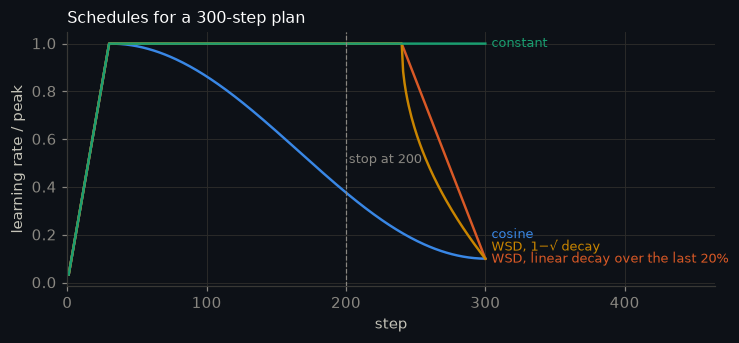

✓ WSD planned for 300 and WSD planned for 200 are identical until step 160


In [27]:
def sched_frac(s, step, total):
    """Learning rate at update number step+1, as a fraction of the peak."""
    W, floor = s.get("warmup", 0), s.get("floor", 0.1)
    if step < W:
        return (step + 1) / W
    kind = s["kind"]
    if kind == "constant":
        return 1.0
    if kind == "cosine":
        p = min(1.0, (step - W) / max(1, total - W))
        return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p))
    if kind == "wsd":
        d0 = total - round(s["decay_frac"] * total)
        if step < d0:
            return 1.0
        p = min(1.0, (step - d0 + 1) / max(1, total - d0))
        shape = (1 - p) if s.get("shape", "linear") == "linear" else (1 - math.sqrt(p))
        return floor + (1 - floor) * shape
    raise ValueError(kind)


TOTAL, STOP = qk(300, 60), qk(200, 40)
WARM = qk(30, 6)
BRANCH, COOL = STOP - round(0.2 * STOP), round(0.2 * STOP)          # 160 and 40 in the full run
fig, ax = plt.subplots(figsize=(7.6, 3.0))
xs = np.arange(TOTAL)
for s, col, lab in ((dict(kind="cosine", warmup=WARM), C["blue"], "cosine"),
                    (dict(kind="wsd", warmup=WARM, decay_frac=0.2), C["orange"], "WSD, linear decay over the last 20%"),
                    (dict(kind="wsd", warmup=WARM, decay_frac=0.2, shape="sqrt"), C["yellow"], "WSD, 1−√ decay"),
                    (dict(kind="constant", warmup=WARM), C["aqua"], "constant")):
    ys = [sched_frac(s, i, TOTAL) for i in xs]
    ax.plot(xs + 1, ys, color=col); label_end(ax, TOTAL, ys[-1], lab, col)
ax.axvline(STOP, color=MUTED, lw=0.8, ls="--"); ax.text(STOP + 2, 0.5, f"stop at {STOP}", color=MUTED, fontsize=8.5)
ax.set(xlabel="step", ylabel="learning rate / peak", xlim=(0, TOTAL * 1.55), title=f"Schedules for a {TOTAL}-step plan")
finish(fig, "schedules")
check(all(sched_frac(dict(kind="wsd", warmup=WARM, decay_frac=0.2), i, TOTAL) ==
          sched_frac(dict(kind="wsd", warmup=WARM, decay_frac=COOL / STOP), i, STOP) for i in range(BRANCH)),
      f"WSD planned for {TOTAL} and WSD planned for {STOP} are identical until step {BRANCH}")

**A hand-written AdamW.** PyTorch's AdamW has no switch for bias correction. So here is AdamW
written out line for line, in the same operation order PyTorch uses, with `bias_correction` as a
flag. With `track=True` it also computes, from the *same* optimizer state, the update both with and
without correction. Their ratio measures what turning correction off would have done at that exact
step (§4).

In [28]:
class HandAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.95), eps=1e-8, weight_decay=0.0, bias_correction=True, track=False):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
        self.bias_correction, self.track, self.counterfactual = bias_correction, track, None

    @torch.no_grad()
    def step(self, closure=None):
        cf = []
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g, st = p.grad, self.state[p]
                if not st:
                    st["step"], st["exp_avg"], st["exp_avg_sq"] = 0, torch.zeros_like(p), torch.zeros_like(p)
                st["step"] += 1
                t, m, v = st["step"], st["exp_avg"], st["exp_avg_sq"]
                p.mul_(1 - lr * wd)                                  # decoupled weight decay
                m.lerp_(g, 1 - b1)                                   # m = b1*m + (1-b1)*g
                v.mul_(b2).addcmul_(g, g, value=1 - b2)              # v = b2*v + (1-b2)*g^2
                bc1, bc2 = 1 - b1 ** t, 1 - b2 ** t
                if self.bias_correction:
                    denom = (v.sqrt() / math.sqrt(bc2)).add_(eps)
                    p.addcdiv_(m, denom, value=-lr / bc1)
                else:
                    p.addcdiv_(m, v.sqrt().add_(eps), value=-lr)
                if self.track:
                    corrected = (m / bc1) / (v.sqrt() / math.sqrt(bc2) + eps)
                    uncorrected = m / (v.sqrt() + eps)
                    cf.append(torch.stack([uncorrected.norm(), corrected.norm()]))
        if self.track and cf:
            r = torch.stack(cf).float()
            self.counterfactual = (r[:, 0] / r[:, 1]).cpu()


def param_groups(model, wd, hidden_lr_mult=1.0):
    hidden = model.hidden_matrices()
    hid_ids = {id(p) for p in hidden}
    other_2d = [p for p in model.parameters() if p.ndim == 2 and id(p) not in hid_ids]
    gains = [p for p in model.parameters() if p.ndim < 2]
    return [dict(params=hidden, weight_decay=wd, lr_mult=hidden_lr_mult, name="hidden"),
            dict(params=other_2d, weight_decay=wd, lr_mult=1.0, name="embedding/head"),
            dict(params=gains, weight_decay=0.0, lr_mult=1.0, name="norm gains")]


def make_opts(model, oc):
    kind, lr, betas, eps, wd = oc["kind"], oc["lr"], tuple(oc.get("betas", (0.9, 0.95))), oc.get("eps", 1e-8), oc.get("wd", 0.1)
    mult = 1 / model.width_mult if model.mup else 1.0
    groups = param_groups(model, wd, mult)
    for g in groups:
        g["peak"] = lr * g["lr_mult"]
    if kind == "adamw":
        return [torch.optim.AdamW(groups, lr=lr, betas=betas, eps=eps, fused=DEV == "cuda")]
    if kind == "hand":
        return [HandAdamW(groups, lr=lr, betas=betas, eps=eps, bias_correction=oc.get("bias_correction", True),
                          track=oc.get("track", False))]
    if kind == "radam":
        return [torch.optim.RAdam(groups, lr=lr, betas=betas, eps=eps, decoupled_weight_decay=True)]
    if kind == "muon":
        hidden = dict(params=groups[0]["params"], peak=oc["muon_lr"])
        muon = torch.optim.Muon([hidden], lr=oc["muon_lr"], weight_decay=wd, momentum=0.95, nesterov=True,
                                adjust_lr_fn="match_rms_adamw")
        return [muon, torch.optim.AdamW(groups[1:], lr=lr, betas=betas, eps=eps, fused=DEV == "cuda")]
    raise ValueError(kind)

**The training loop.** `train(cfg)` runs one configuration. Everything it measures is returned as
plain numbers, and every hook is optional:

| hook | what it records |
|---|---|
| `eval_at` | validation loss (and each eval batch's loss, for paired error bars) after those steps |
| `log_every` | each tensor's update/weight ratio, with and without its decay part, and Adam's step as a fraction of η |
| `detail_every` | spectral update/weight ratio for four matrices; the share of updates smaller than half a bf16 spacing; embedding rows by token frequency |
| `ema` | exponential moving averages of the weights, evaluated at `eval_at` |
| `ckpt_at` | in-memory copies of model and optimizer, to branch from |
| `sample_at` | a short generated story |

A run is marked **diverged** when its loss becomes non-finite or rises above the untrained model's
loss after warmup.

In [29]:
@torch.no_grad()
def evaluate(model, fam):
    model.eval()
    micro = 8 if fam == "base" else (16 if model.emb.weight.shape[1] >= 2048 else 64)
    losses = []
    for xb, yb in eval_batches(fam, micro):
        with autocast():
            losses.append(model(xb, yb).float())
    model.train()
    per = torch.stack(losses).cpu().numpy()
    return dict(loss=float(per.mean()), batches=per)


@torch.no_grad()
def sample_story(model, prompt="Once upon a time", n=48, seed=0):
    model.eval()
    g = torch.Generator(device=DEV).manual_seed(seed)
    ids = torch.tensor([TOK.encode(prompt).ids], device=DEV)
    for _ in range(n):
        with autocast():
            logits = model(ids[:, -BASE_T:])[:, -1].float() / 0.8
        top = logits.topk(40)
        nxt = top.indices.gather(-1, torch.multinomial(top.values.softmax(-1), 1, generator=g))
        if nxt.item() == EOT:
            break
        ids = torch.cat([ids, nxt], 1)
    model.train()
    return TOK.decode(ids[0].tolist())


def _named_tensors(model):
    return [(n.replace("blocks.", "b").replace(".weight", ""), p) for n, p in model.named_parameters()]


def train(cfg):
    fam = cfg["family"]
    total, stop = cfg["steps"], cfg.get("stop", cfg["steps"])
    seed_all(cfg["seed"])
    model = make_model(cfg).to(DEV)
    opts = make_opts(model, cfg["opt"])
    scaler = torch.amp.GradScaler("cuda") if (AMP == "fp16" and DEV == "cuda") else None
    start = 0
    if cfg.get("resume") is not None:
        ck = cfg["resume"]
        model.load_state_dict(ck["model"])
        for o, sd in zip(opts, ck["opts"]):
            o.load_state_dict(sd)
        start = ck["step"]
    B = BASE_B if fam == "base" else WIDTH_B
    accum = BASE_ACCUM if fam == "base" else (4 if cfg.get("width", 0) >= 2048 else 1)
    names = [n for n, _ in _named_tensors(model)]
    params = [p for _, p in _named_tensors(model)]
    group_of = {}
    for o in opts:
        for g in o.param_groups:
            for p in g["params"]:
                group_of[id(p)] = g
    hist = dict(loss=[], lr=[], gnorm=[], clipped=[])
    out = dict(evals={}, ratios=dict(steps=[], total=[], grad=[], adam_frac=[]), tensors=names,
               detail=dict(steps=[], spectral=[], bf16_lost=[], bf16_lost_floor=[], emb_rows=[]), samples={}, ema_evals={},
               counterfactual=dict(steps=[], ratio=[]), diverged_at=None)
    log_every, detail_every = cfg.get("log_every", 0), cfg.get("detail_every", 0)
    spectral_ids = [names.index(n) for n in ("b0.q", f"b{len(model.blocks) // 2}.up", f"b{len(model.blocks) - 1}.down", "emb")]
    ema_decays = cfg.get("ema") or []
    ema = [[p.detach().float().clone().zero_() for p in params] for _ in ema_decays]
    ckpts, loss0 = {}, None
    wd_frac = (lambda: [group_of[id(p)]["lr"] * group_of[id(p)]["weight_decay"] for p in params])
    for s in range(start, stop):
        frac = sched_frac(cfg["sched"], s, total)
        for o in opts:
            for g in o.param_groups:
                g["lr"] = g["peak"] * frac
        win = WIN[fam].batch(cfg["seed"], s, B)
        if fam == "width":
            win = REMAP[win]
        win = win.to(DEV, non_blocking=True)
        loss_acc = torch.zeros((), device=DEV)
        for chunk in win.chunk(accum):
            with autocast():
                loss = model(chunk[:, :-1], chunk[:, 1:])
            (scaler.scale(loss / accum) if scaler else loss / accum).backward()
            loss_acc += loss.detach() / accum
        if scaler:
            for o in opts:
                scaler.unscale_(o)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.get("clip", 1.0))
        log_now = log_every and ((s + 1) % log_every == 0 or s < 10 or (s + 1) in cfg.get("eval_at", []))
        detail_now = detail_every and ((s + 1) % detail_every == 0 or s == 0)
        if log_now or detail_now:
            before = [p.detach().clone() for p in params]
            decay = wd_frac()
        if scaler:
            for o in opts:
                scaler.step(o)
            scaler.update()
        else:
            for o in opts:
                o.step()
        for o in opts:
            o.zero_grad(set_to_none=True)
        L = loss_acc.item()
        loss0 = L if loss0 is None else loss0
        hist["loss"].append(L); hist["lr"].append(frac); hist["gnorm"].append(gnorm.item())
        hist["clipped"].append(bool(gnorm.item() > cfg.get("clip", 1.0)))
        if not math.isfinite(L) or (s >= cfg["sched"].get("warmup", 0) and s > 5 and L > loss0 + 0.5):
            out["diverged_at"] = s + 1
            break
        if log_now or detail_now:
            with torch.no_grad():
                after = [p.detach() for p in params]
                delta = torch._foreach_sub(after, before)
                wn = torch.stack(torch._foreach_norm(before)).float()
                dn = torch.stack(torch._foreach_norm(delta)).float()
                torch._foreach_add_(delta, torch._foreach_mul(before, decay))     # remove the decay part exactly
                gn = torch.stack(torch._foreach_norm(delta)).float()
                numel = torch.tensor([p.numel() for p in params], device=DEV, dtype=torch.float32)
                lrs = torch.tensor([group_of[id(p)]["lr"] for p in params], device=DEV, dtype=torch.float32)
                if log_now:
                    out["ratios"]["steps"].append(s + 1)
                    out["ratios"]["total"].append((dn / wn).cpu())
                    out["ratios"]["grad"].append((gn / wn).cpu())
                    out["ratios"]["adam_frac"].append((gn / (lrs * numel.sqrt())).cpu())
                if detail_now:
                    full_delta = torch._foreach_sub(after, before)
                    out["detail"]["steps"].append(s + 1)
                    out["detail"]["spectral"].append([
                        (torch.linalg.matrix_norm(full_delta[i].float(), ord=2) /
                         torch.linalg.matrix_norm(before[i].float(), ord=2)).item() for i in spectral_ids])
                    lost, lost_floor = [], []
                    for b_, d_ in zip(before, full_delta):
                        half_ulp = torch.ldexp(torch.ones_like(b_), torch.frexp(b_).exponent - 9)
                        lost.append((d_.abs() < half_ulp).float().mean())
                        lost_floor.append((0.1 * d_.abs() < half_ulp).float().mean())      # the same step at a 10x smaller lr
                    out["detail"]["bf16_lost"].append(torch.stack(lost).cpu())
                    out["detail"]["bf16_lost_floor"].append(torch.stack(lost_floor).cpu())
                    e_i = names.index("emb")
                    row_r = full_delta[e_i].norm(dim=1) / before[e_i].norm(dim=1).clamp_min(1e-12)
                    present = torch.zeros(row_r.shape[0], dtype=torch.bool, device=DEV)
                    present[win[:, :-1].reshape(-1)] = True
                    fr = FREQ_RANK.to(DEV) if fam == "base" else torch.arange(row_r.shape[0], device=DEV)
                    buckets = [(fr < 100), (fr >= 100) & (fr < 1000), (fr >= 1000) & (fr < 8000), (fr >= 8000)]
                    out["detail"]["emb_rows"].append([row_r[bk].mean().item() for bk in buckets] +
                                                     [row_r[present].mean().item(), row_r[~present].mean().item() if (~present).any() else None])
                    del full_delta
                del before, delta, after                 # each is a full copy of the model: free it before the next forward pass
        if getattr(opts[0], "counterfactual", None) is not None and ((s + 1) % 5 == 0 or s < 30):
            out["counterfactual"]["steps"].append(s + 1)
            out["counterfactual"]["ratio"].append(opts[0].counterfactual)
        if ema:
            with torch.no_grad():
                for d, e in zip(ema_decays, ema):
                    torch._foreach_lerp_(e, [p.detach().float() for p in params], 1 - d)
        if (s + 1) in cfg.get("ckpt_at", []):
            ckpts[s + 1] = dict(step=s + 1, model={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                                opts=[copy.deepcopy(_to_cpu(o.state_dict())) for o in opts])
        if (s + 1) in cfg.get("eval_at", []):
            out["evals"][s + 1] = evaluate(model, fam)
            for d, e in zip(ema_decays, ema):
                n_upd = s + 1 - start
                saved = [p.detach().clone() for p in params]
                with torch.no_grad():
                    for p, ev in zip(params, e):
                        p.copy_(ev / (1 - d ** n_upd))                 # bias-corrected average, as in Adam
                out["ema_evals"].setdefault(str(d), {})[s + 1] = evaluate(model, fam)["loss"]
                with torch.no_grad():
                    for p, sv in zip(params, saved):
                        p.copy_(sv)
        if (s + 1) in cfg.get("sample_at", []) and TOK is not None and fam == "base":
            out["samples"][s + 1] = sample_story(model)
    if cfg.get("diag") and out["diverged_at"] is None:
        xb, _ = eval_batches(fam, 8 if fam == "base" else 16)[0]
        out["diag"] = model.diagnostics(xb[:4])
    out["hist"] = hist
    out["peak_mem_gib"] = torch.cuda.max_memory_allocated() / 2**30 if DEV == "cuda" else None
    for k in ("ratios", "detail"):
        for kk, vv in out[k].items():
            out[k][kk] = [x.tolist() if isinstance(x, torch.Tensor) else x for x in vv]
    out["counterfactual"]["ratio"] = [x.tolist() for x in out["counterfactual"]["ratio"]]
    for st in out["evals"]:
        out["evals"][st]["batches"] = out["evals"][st]["batches"].tolist()
    del model, opts
    free_gpu()
    return out, ckpts


def _to_cpu(obj):
    if isinstance(obj, torch.Tensor):
        return obj.detach().cpu().clone()
    if isinstance(obj, dict):
        return {k: _to_cpu(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [_to_cpu(v) for v in obj]
    return obj

**Helpers for naming, running and reading experiments.** A configuration's name is built from its
settings, so two sections that need the same run share one stored result instead of training
twice.

In [30]:
def cfg_name(cfg, tag=""):
    o, s = cfg["opt"], cfg["sched"]
    fam = "base" if cfg["family"] == "base" else f"w{cfg['width']}{'-mup' if cfg.get('mup') else ''}"
    opt = o["kind"] + ("" if o.get("bias_correction", True) else "-nobc") + (f"-b2{o['betas'][1]}" if o.get("betas") else "")
    lr = f"lr{o['lr']:.3g}" + (f"-mu{o['muon_lr']:.3g}" if o["kind"] == "muon" else "")
    sch = s["kind"] + f"-w{s.get('warmup', 0)}" + (f"-d{s['decay_frac']:g}{s.get('shape', 'linear')[0]}" if s["kind"] == "wsd" else "") \
        + (f"-fl{s['floor']:g}" if "floor" in s else "")
    stop = f"-stop{cfg['stop']}" if cfg.get("stop", cfg["steps"]) != cfg["steps"] else ""
    return f"{fam}|{opt}|{lr}|{sch}|T{cfg['steps']}{stop}|s{cfg['seed']}" + (f"|{tag}" if tag else "")


BASE_HOOKS = dict(eval_at=sorted({qk(100, 20), qk(150, 30), STOP, qk(240, 48), qk(250, 50), TOTAL}),
                  log_every=10, sample_at=[STOP, TOTAL])


def base_cfg(lr, seed=0, kind="cosine", warmup=WARM, opt="adamw", **kw):
    sched = dict(kind=kind, warmup=warmup)
    sched.update({k: kw.pop(k) for k in ("decay_frac", "shape", "floor") if k in kw})
    o = dict(kind=opt, lr=lr, betas=kw.pop("betas", (0.9, 0.95)), wd=0.1)
    o.update({k: kw.pop(k) for k in ("bias_correction", "track", "muon_lr") if k in kw})
    cfg = dict(family="base", seed=seed, steps=kw.pop("steps", TOTAL), sched=sched, opt=o, clip=1.0)
    cfg.update(BASE_HOOKS)
    cfg.update(kw)
    return cfg


def run(cfg, tag=""):
    """Run (or reuse) one configuration; returns the stored result."""
    return experiment(cfg_name(cfg, tag), lambda: train(cfg)[0])


def final_loss(res, step=None):
    """Validation loss at `step` (default: the last evaluation); inf if the run diverged first."""
    if res is None:
        return float("nan")
    ev = res["evals"]
    key = str(step) if step is not None else max(ev, key=int, default=None)
    if key is None or key not in ev:
        return float("inf")
    return ev[key]["loss"]


def ema_curve(xs, n=20):
    """Bias-corrected exponential moving average with a time constant of n steps (the same correction Adam uses)."""
    out, m, a = [], 0.0, 1 / n
    for i, x in enumerate(xs, 1):
        m = (1 - a) * m + a * x
        out.append(m / (1 - (1 - a) ** i))
    return np.array(out)


def lr_sweep(make_cfg, lrs, metric, factor=2.0, max_ext=2, tag=""):
    """Run make_cfg(lr) for each lr; extend the grid at an edge whose point is the best, up to max_ext times."""
    res = {}
    lrs = sorted(lrs)
    for lr in lrs:
        res[lr] = run(make_cfg(lr), tag)
    for _ in range(max_ext):
        finite = {lr: metric(r) for lr, r in res.items() if math.isfinite(metric(r))}
        if not finite:
            break
        best = min(finite, key=finite.get)
        lo, hi = min(res), max(res)
        if best == lo:
            new = lo / factor
        elif best == hi:
            new = hi * factor
        else:
            break
        res[new] = run(make_cfg(new), tag)
    return dict(sorted(res.items()))

**Checking the hand-written AdamW against PyTorch's, at full model scale.** §1 checked one weight.
Here every one of the base model's 31.5M weights is checked:
- PyTorch's AdamW and `HandAdamW` each update their own copy of the parameters for 20 steps.
- At each step both get the *same* gradient, computed on the first copy and in float32.
- Any difference that builds up is pure optimizer arithmetic.

In [31]:
def hand_vs_torch(steps=20):
    seed_all(0)
    m_a = LM(**BASE_ARCH).to(DEV)
    m_b = copy.deepcopy(m_a)
    pa, pb = list(m_a.parameters()), list(m_b.parameters())
    opt_a = torch.optim.AdamW(param_groups(m_a, 0.1), lr=2e-3, betas=(0.9, 0.95), eps=1e-8, foreach=False)
    opt_b = HandAdamW(param_groups(m_b, 0.1), lr=2e-3, betas=(0.9, 0.95), eps=1e-8)
    worst = []
    for s in range(steps):
        win = WIN["base"].batch(0, s, 4).to(DEV)
        m_a(win[:, :-1], win[:, 1:]).backward()                     # float32, no autocast
        for a, b in zip(pa, pb):
            b.grad = a.grad.clone()
        opt_a.step(); opt_b.step()
        opt_a.zero_grad(); opt_b.zero_grad()
        worst.append(max((a - b).abs().max().item() for a, b in zip(pa, pb)))
    del m_a, m_b, opt_a, opt_b
    free_gpu()
    return dict(max_abs_diff_per_step=worst, n_params=sum(p.numel() for p in pa))


hv = experiment("handadamw_vs_torch", hand_vs_torch)
if hv:
    print(f"largest |difference| across {hv['n_params']:,} weights after each of 20 steps: "
          + ", ".join(f"{x:.0e}" for x in hv["max_abs_diff_per_step"][::4]))
    check(max(hv["max_abs_diff_per_step"]) < 1e-6, "HandAdamW matches torch.optim.AdamW on every weight of the base model for 20 steps")

largest |difference| across 31,463,808 weights after each of 20 steps: 0e+00, 0e+00, 0e+00, 0e+00, 0e+00
✓ HandAdamW matches torch.optim.AdamW on every weight of the base model for 20 steps


### Tuning the base model's learning rate

Sections §4–§6 and §M need one well-chosen peak learning rate for the base model. It is chosen the
same way every comparison in this notebook is tuned:
- a factor-2 grid, scored by validation loss at the final step
- extended at an edge whenever the best point sits on that edge, so the minimum is bracketed
- two more seeds at the winner, which measure how much the loss moves from seed to seed
- one repeat of seed 0, which measures how much the GPU's non-deterministic kernels move it on
  their own

That repeat is the **noise floor**: a smaller difference than this cannot mean anything.

  peak lr   val@200   val@300
 5.00e-04    2.9020    2.7243  
 1.00e-03    2.7675    2.5796    ← best
 2.00e-03    2.8724    2.6425  
 4.00e-03    3.8402    3.5150  
 8.00e-03    4.2955    3.9491  
✓ the best peak learning rate (1e-03) is bracketed by the grid
✓ untrained loss 10.83 ≈ ln(49,152) = 10.80: the initial predictions are close to uniform

seed-to-seed: validation loss 2.6064 ± 0.0235 (s.d., 3 seeds); smoothed training loss s.d. 0.0336 per step (median)
same seed, run twice: validation loss differs by 0.00000; smoothed training loss by at most 0.0000
✓ observed: re-running the same seed moves the validation loss less than changing the seed does


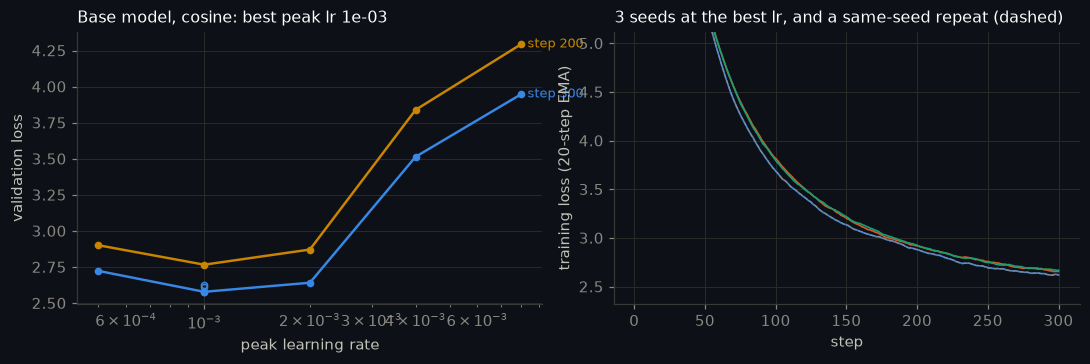


sample from the tuned model at step 300 :
  Once upon a time, there was a little boy named Tim. Tim had a big toy box all day. It was very big and shiny. Tim loved to play outside with his ball.
One day, Tim was playing with a ball from the sky.


In [32]:
GRID_BASE = qk([5e-4, 1e-3, 2e-3, 4e-3, 8e-3], [1e-3, 4e-3, 1.6e-2])
SEEDS = qk([0, 1, 2], [0, 1])

cos_grid = lr_sweep(lambda lr: base_cfg(lr), GRID_BASE, final_loss, max_ext=3)
finite = {lr: final_loss(r) for lr, r in cos_grid.items() if math.isfinite(final_loss(r))}
LR_BASE = min(finite, key=finite.get)
cos_seeds = {s: run(base_cfg(LR_BASE, seed=s)) for s in SEEDS}
cos_repeat = run(base_cfg(LR_BASE, seed=0), tag="repeat")

print(f"{'peak lr':>9} {'val@' + str(STOP):>9} {'val@' + str(TOTAL):>9}")
for lr, r in cos_grid.items():
    note = f"diverged at step {r['diverged_at']}" if r["diverged_at"] else ""
    print(f"{lr:9.2e} {final_loss(r, STOP):9.4f} {final_loss(r, TOTAL):9.4f}  {note}{'  ← best' if lr == LR_BASE else ''}")
check(LR_BASE not in (min(cos_grid), max(cos_grid)), f"the best peak learning rate ({LR_BASE:.0e}) is bracketed by the grid")

loss0 = cos_seeds[0]["hist"]["loss"][0]
check(abs(loss0 - math.log(V_BASE)) < 0.3, f"untrained loss {loss0:.2f} ≈ ln(49,152) = {math.log(V_BASE):.2f}: the initial predictions are close to uniform")

smooth = np.array([ema_curve(cos_seeds[s]["hist"]["loss"], 20) for s in SEEDS])
SEED_SD = float(np.median(smooth[:, WARM * 2:].std(0, ddof=1)))
vals = np.array([final_loss(cos_seeds[s]) for s in SEEDS])
nondet_val = abs(final_loss(cos_repeat) - final_loss(cos_seeds[0]))
nondet_train = float(np.max(np.abs(ema_curve(cos_repeat["hist"]["loss"], 20) - smooth[0])))
print(f"\nseed-to-seed: validation loss {vals.mean():.4f} ± {vals.std(ddof=1):.4f} (s.d., {len(SEEDS)} seeds); "
      f"smoothed training loss s.d. {SEED_SD:.4f} per step (median)")
print(f"same seed, run twice: validation loss differs by {nondet_val:.5f}; smoothed training loss by at most {nondet_train:.4f}")
observe("nondeterminism_below_seed_noise", nondet_val < vals.std(ddof=1),
        "re-running the same seed moves the validation loss less than changing the seed does")
if MODE != "learn":
    ANS["base"] = _clean(dict(lr=LR_BASE, grid={f"{lr:.3g}": final_loss(r) for lr, r in cos_grid.items()},
                              val_mean=vals.mean(), val_sd=vals.std(ddof=1), seed_sd_train=SEED_SD,
                              nondet_val=nondet_val, nondet_train=nondet_train, loss0=loss0, n_params=N_BASE))
    save_results()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
lrs = list(cos_grid)
for step, col in ((STOP, C["yellow"]), (TOTAL, C["blue"])):
    a1.plot(lrs, [final_loss(cos_grid[lr], step) for lr in lrs], "-o", ms=4, color=col)
    label_end(a1, lrs[-1], final_loss(cos_grid[lrs[-1]], step), f"step {step}", col)
a1.plot([LR_BASE] * len(SEEDS), vals, "o", ms=4, mfc="none", color=C["blue"])
a1.set(xscale="log", xlabel="peak learning rate", ylabel="validation loss",
       title=f"Base model, cosine: best peak lr {LR_BASE:.0e}")
steps = np.arange(1, len(smooth[0]) + 1)
for i, s in enumerate(SEEDS):
    a2.plot(steps, smooth[i], color=SERIES[i], lw=1.1)
a2.plot(steps, ema_curve(cos_repeat["hist"]["loss"], 20), color=MUTED, lw=0.8, ls="--")
a2.set(ylim=(smooth[:, -1].min() - 0.3, smooth[:, -1].min() + 2.5), xlabel="step", ylabel="training loss (20-step EMA)",
       title=f"{len(SEEDS)} seeds at the best lr, and a same-seed repeat (dashed)")
fig.tight_layout()
finish(fig, "base_lr_tuning")
print("\nsample from the tuned model at step", TOTAL, ":\n ", cos_seeds[0]["samples"].get(str(TOTAL), "(not stored)"))

> **Carry forward:** the base model's peak learning rate is tuned and bracketed, and the seed noise
> and the GPU noise floor are measured. Later sections compare against these numbers instead of
> eyeballing curves.

## §4 Bias correction in a real model

§2 answered "when does bias correction stop mattering?" for one weight, in closed form. A model
has 31.5M weights, an ε that competes with tiny gradients, and warmup scaling down exactly the
early steps where the correction acts. So the question is asked again here, of the loss.

**Setup.**
- The base model at its tuned learning rate, cosine schedule, 300 steps.
- `HandAdamW` with bias correction on and off.
- Crossed with $\beta_2 \in \{0.95, 0.999\}$ and warmup $\in \{0, 30\}$ steps.
- All eight runs share seed 0, so they start from the same weights and see the same batches.

**Rule (§0).** The difference stops mattering at the first step after which the 20-step-EMA loss
gap between "off" and "on" stays inside ±2 seed standard deviations, as measured in §3.

**Counterfactual.** In every "on" run, the optimizer also computes what the uncorrected update would
have been at that exact step, from the same state. The ratio of the two, per tensor, can be set
against §2's closed form $f(t)$. A tensor whose ratio falls below $f(t)$ is one where ε is
competing with $\sqrt{v}$.

In [33]:
BC_RUNS = {}
for b2 in (0.95, 0.999):
    for w in (0, WARM):
        for bc in (True, False):
            BC_RUNS[(b2, w, bc)] = run(base_cfg(LR_BASE, warmup=w, opt="hand", betas=(0.9, b2), bias_correction=bc,
                                                track=bc, log_every=0))

band = RULES["bias_correction_stop"]["band_sd"] * SEED_SD
MODEL_STOP, VAL_TABLE = {}, {}
print(f"seed band: ±{band:.4f} (2 s.d. of the smoothed training loss, from §3)\n")
print(f"{'β2':>6} {'warmup':>7} {'val on':>8} {'val off':>8} {'off - on':>9}   loss gap stays inside the seed band from step")
for b2 in (0.95, 0.999):
    for w in (0, WARM):
        on_r, off_r = BC_RUNS[(b2, w, True)], BC_RUNS[(b2, w, False)]
        n = min(len(on_r["hist"]["loss"]), len(off_r["hist"]["loss"]))
        gap = ema_curve(off_r["hist"]["loss"][:n], 20) - ema_curve(on_r["hist"]["loss"][:n], 20)
        stop = stop_step(np.where(np.isfinite(gap), gap, np.inf), band) if n == TOTAL else None
        stop = stop if (stop is not None and stop <= n) else None
        MODEL_STOP[(b2, w)] = stop
        v_on, v_off = final_loss(on_r), final_loss(off_r)
        VAL_TABLE[(b2, w)] = (v_on, v_off)
        div = f" (off diverged at {off_r['diverged_at']})" if off_r["diverged_at"] else ""
        print(f"{b2:>6} {w:>7} {v_on:8.4f} {v_off:8.4f} {v_off - v_on:+9.4f}   "
              f"{stop if stop else 'never within ' + str(TOTAL)}{div}")

val_sd = ANS.get("base", {}).get("val_sd") or float(np.std([final_loss(cos_seeds[s]) for s in SEEDS], ddof=1))
d = {k: v[1] - v[0] for k, v in VAL_TABLE.items()}
observe("bc_off_hurts_0999_no_warmup", d[(0.999, 0)] > 2 * val_sd,
        f"β2=0.999 without warmup: switching bias correction off costs {d[(0.999, 0)]:+.3f} in final loss (seed s.d. {val_sd:.3f})")
observe("warmup_hides_bc_0999", abs(d[(0.999, WARM)]) < abs(d[(0.999, 0)]),
        f"expected warmup to shrink that cost (β2=0.999); measured {d[(0.999, 0)]:+.3f} without warmup and "
        f"{d[(0.999, WARM)]:+.3f} with it")
observe("bc_negligible_095", max(abs(d[(0.95, 0)]), abs(d[(0.95, WARM)])) < 2 * val_sd,
        f"expected switching bias correction off to be harmless at β2=0.95 (within 2 seed s.d. = {2 * val_sd:.3f}); "
        f"measured {d[(0.95, 0)]:+.3f} without warmup and {d[(0.95, WARM)]:+.3f} with it")

seed band: ±0.0671 (2 s.d. of the smoothed training loss, from §3)

    β2  warmup   val on  val off  off - on   loss gap stays inside the seed band from step
  0.95       0   3.5534   2.9547   -0.5987   never within 300
  0.95      30   2.6041   2.6313   +0.0272   16
 0.999       0   3.5265   4.2360   +0.7095   never within 300
 0.999      30   2.6179   4.5932   +1.9753   never within 300
✓ observed: β2=0.999 without warmup: switching bias correction off costs +0.709 in final loss (seed s.d. 0.024)


✗ not observed: expected warmup to shrink that cost (β2=0.999); measured +0.709 without warmup and +1.975 with it


✗ not observed: expected switching bias correction off to be harmless at β2=0.95 (within 2 seed s.d. = 0.047); measured -0.599 without warmup and +0.027 with it


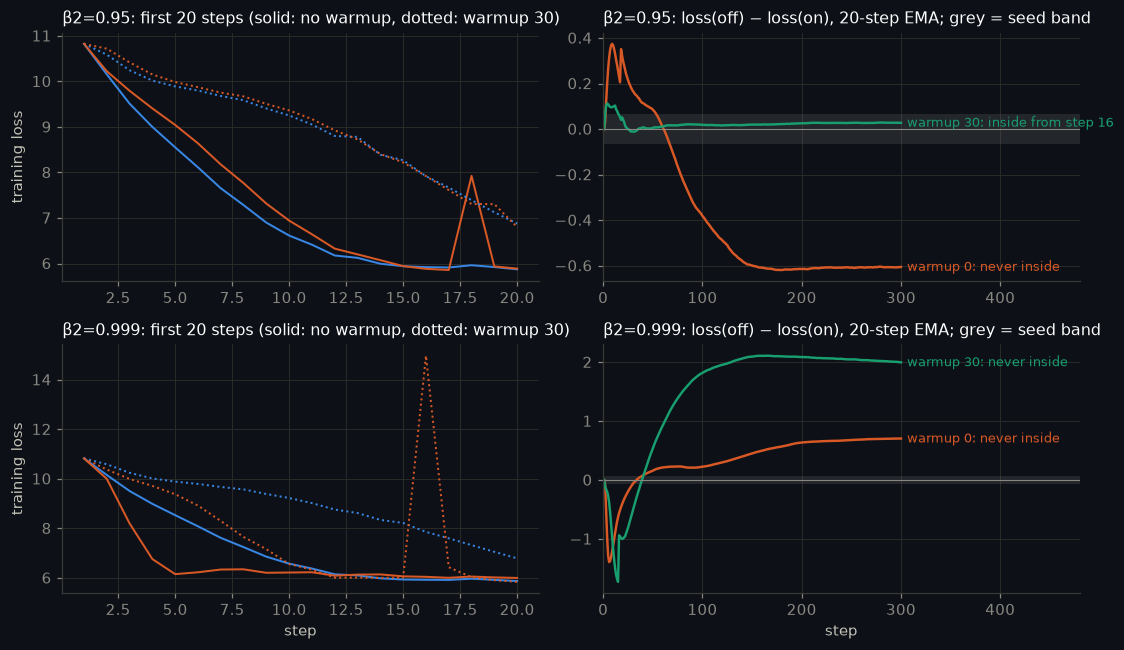

In [34]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6))
for row, b2 in enumerate((0.95, 0.999)):
    ax = axs[row, 0]
    for w, ls in ((0, "-"), (WARM, ":")):
        for bc, col in ((True, C["blue"]), (False, C["orange"])):
            ys = BC_RUNS[(b2, w, bc)]["hist"]["loss"][:20]
            ax.plot(np.arange(1, len(ys) + 1), ys, ls, color=col, lw=1.3)
    ax.set(title=f"β2={b2}: first 20 steps (solid: no warmup, dotted: warmup {WARM})", ylabel="training loss")
    ax = axs[row, 1]
    for w, col in ((0, C["orange"]), (WARM, C["aqua"])):
        on_r, off_r = BC_RUNS[(b2, w, True)], BC_RUNS[(b2, w, False)]
        n = min(len(on_r["hist"]["loss"]), len(off_r["hist"]["loss"]))
        gap = ema_curve(off_r["hist"]["loss"][:n], 20) - ema_curve(on_r["hist"]["loss"][:n], 20)
        ax.plot(np.arange(1, n + 1), gap, color=col)
        lab = f"warmup {w}: inside from step {MODEL_STOP[(b2, w)]}" if MODEL_STOP[(b2, w)] else f"warmup {w}: never inside"
        label_end(ax, n, gap[-1], lab, col)
    ax.axhspan(-band, band, color=MUTED, alpha=0.18, lw=0)
    ax.axhline(0, color=MUTED, lw=0.7)
    ax.set(title=f"β2={b2}: loss(off) − loss(on), 20-step EMA; grey = seed band", xlim=(0, TOTAL * 1.6))
axs[1, 0].set_xlabel("step"); axs[1, 1].set_xlabel("step")
fig.tight_layout()
finish(fig, "bias_correction_model")

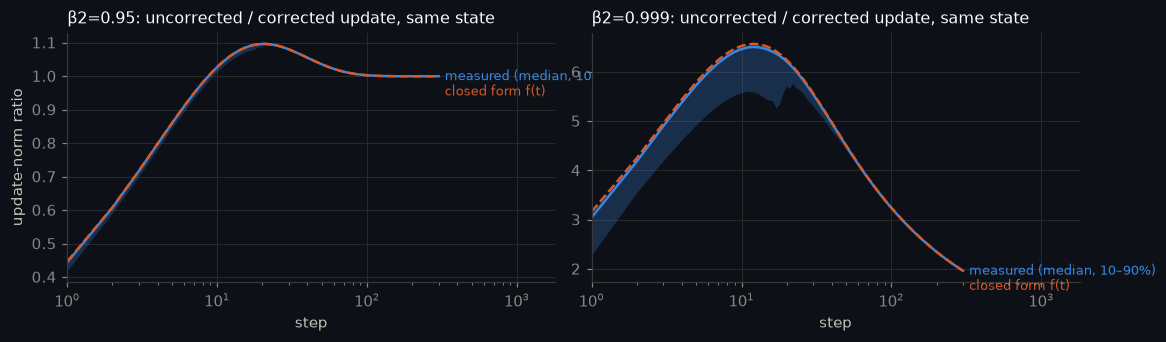

β2=0.95: the median tensor's counterfactual ratio is within 0.6% of the closed form at every logged step
β2=0.999: the median tensor's counterfactual ratio is within 3.7% of the closed form at every logged step
✓ observed: in the real model the uncorrected/corrected update ratio follows §2's closed form (median tensor within 5%)


In [35]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
CF_DEV = {}
for ax, b2 in zip(axs, (0.95, 0.999)):
    r = BC_RUNS[(b2, 0, True)]["counterfactual"]
    st = np.array(r["steps"]); ratio = np.array(r["ratio"], dtype=float)
    closed = (1 - 0.9 ** st) / np.sqrt(1 - b2 ** st)
    ax.fill_between(st, np.nanpercentile(ratio, 10, 1), np.nanpercentile(ratio, 90, 1), color=C["blue"], alpha=0.25, lw=0)
    ax.plot(st, np.nanmedian(ratio, 1), color=C["blue"]); label_end(ax, st[-1], np.nanmedian(ratio[-1]), "measured (median, 10–90%)", C["blue"])
    ax.plot(st, closed, "--", color=C["orange"]); label_end(ax, st[-1], closed[-1], "closed form f(t)", C["orange"], dy=-10)
    ax.set(xscale="log", xlabel="step", title=f"β2={b2}: uncorrected / corrected update, same state", xlim=(1, TOTAL * 6))
    CF_DEV[b2] = float(np.nanmax(np.abs(np.nanmedian(ratio, 1) / closed - 1)))
axs[0].set_ylabel("update-norm ratio")
fig.tight_layout()
finish(fig, "bias_correction_counterfactual")
for b2 in (0.95, 0.999):
    print(f"β2={b2}: the median tensor's counterfactual ratio is within {CF_DEV[b2]:.1%} of the closed form at every logged step")
observe("counterfactual_matches_closed_form", max(CF_DEV.values()) < 0.05,
        "in the real model the uncorrected/corrected update ratio follows §2's closed form (median tensor within 5%)")

if MODE != "learn":
    ANS["bias_correction"] = _clean(dict(
        closed_form_stop={str(b2): {f"{p:.0%}": n for p, n in v.items()} for b2, v in BC_STOP.items()},
        first_step=float(f_closed[0]), peak=float(f_closed.max()), peak_t=int(t20[f_closed.argmax()]), at20=float(f_closed[-1]),
        excess_displacement_0999=EXCESS_0999,
        model_stop={f"b2={b2},warmup={w}": s for (b2, w), s in MODEL_STOP.items()},
        val={f"b2={b2},warmup={w}": dict(on=v[0], off=v[1]) for (b2, w), v in VAL_TABLE.items()},
        counterfactual_max_dev=CF_DEV, seed_band=band))
    save_results()

**What the measurements say.** The closed form from §2 predicts the model's behaviour, and two of
the expectations recorded above did not hold.

- **$\beta_2 = 0.999$.** Switching correction off is not an early-steps problem. The uncorrected
  multiplier is still about 2× at step 300, so the whole run trains at 2–6.6× its tuned learning rate.
  The loss never comes back inside the seed band. Warmup does not hide it: the multiplier peaks
  around step 12 and stays above 2 long after a 30-step warmup has ended.
- **$\beta_2 = 0.95$.** The correction acts only over the first ~20 steps, and there it *raises* the
  step. Uncorrected, the first step is $0.45\,\eta$.
  - Without warmup, the uncorrected run is the *better* one: its own small early steps work as a
    built-in warmup.
  - With warmup, the two runs are indistinguishable from step 16.

> **Carry forward:** how long bias correction matters is set by $1/(1-\beta_2)$, and in a short run
> that can be the whole run. With $\beta_2 = 0.999$ a missing correction quietly multiplies the
> learning rate for thousands of steps. With $\beta_2 = 0.95$ its only visible job is shaping the
> first ~20 steps, which warmup also does.

## §5 The update-to-weight ratio, layer by layer, and when warmup stops shaping it

**Intuition.** A weight's absolute update means little on its own. A step of $10^{-3}$ is huge for a
weight of size $10^{-2}$ and negligible for one of size 10. The scale-free quantity is
$$r = \frac{\lVert \Delta W\rVert}{\lVert W\rVert},$$
the fraction of itself a tensor moves in one step. A healthy run keeps it near $10^{-3}$. (Some
write it upside down, "weight-to-update"; the information is the same.)

**Why warmup exists, in these terms.** Adam moves every weight by about $\eta\cdot\rho$:
- $\rho \approx 1$ when the gradients agree from step to step.
- $\rho$ is much smaller when they are noise.

At initialization almost every weight is wrong in the same direction, so gradients agree and
$\rho \approx 1$. This is exactly when weights are smallest relative to their updates. Warmup ramps
$\eta$ up while $\rho$ falls.

**What "warmup stops changing the ratio" means here (rule, §0).**
- Compare a run warmed up over $W$ steps with one that is not, at the same peak learning rate.
- After warmup the learning rate is held constant, so any later difference comes from the warmup
  alone.
- For each tensor, warmup has stopped changing the ratio at the first step after which the 9-step
  rolling median stays within 10% of the no-warmup run's.

Warmup changes the ratio from step 1 by construction, because the learning rate itself is smaller.
So the informative number is where its influence **ends**.

**Runs.**
- Warmup $W \in \{0, 6, 30, 100\}$ steps, then a constant peak learning rate, base model.
- Every tensor's ratio logged on every step.
- A **RAdam** run with no warmup at all. RAdam replaces warmup with a correction for the noise of
  $v$ in early steps.

In [36]:
WARMUPS = qk([0, 6, 30, 100], [0, 2, 6, 20])
ratio_runs = {w: run(base_cfg(LR_BASE, kind="constant", warmup=w, log_every=1, detail_every=qk(10, 5),
                              eval_at=[STOP, TOTAL], sample_at=[])) for w in WARMUPS}
radam = run(base_cfg(LR_BASE, kind="constant", warmup=0, opt="radam", log_every=1, eval_at=[STOP, TOTAL], sample_at=[]))

names = ratio_runs[0]["tensors"]
MATS = [i for i, n in enumerate(names) if n == "emb" or (n.startswith("b") and n.split(".")[-1] in ("q", "kv", "o", "up", "down"))]


def rolling_median(a, k=RULES["warmup_stop"]["window"]):
    pad = np.pad(a, ((k // 2, k // 2), (0, 0)), mode="edge")
    return np.median(np.lib.stride_tricks.sliding_window_view(pad, k, axis=0), axis=-1)


def ratio_matrix(res, key="total"):
    r = np.array(res["ratios"][key], dtype=float)                       # (steps, tensors)
    return r


rm = {w: rolling_median(ratio_matrix(ratio_runs[w])) for w in WARMUPS}
n_steps = min(len(v) for v in rm.values())
WSTOP = {}
for w in WARMUPS[1:]:
    rel = rm[w][:n_steps] / rm[0][:n_steps] - 1
    WSTOP[w] = {p: [stop_step(rel[:, i], p) for i in MATS] for p in RULES["warmup_stop"]["p"]}
    final = np.median(rm[w][-50:], axis=0)
    plateau = [stop_step(rm[w][:, i] / final[i] - 1, 0.10) for i in MATS]
    peak_gap = [int(np.argmax(np.abs(np.log(rm[w][:n_steps, i] / rm[0][:n_steps, i])))) + 1 for i in MATS]
    s10 = np.array(WSTOP[w][0.10])
    fmt = lambda v: f"{int(v)}" if v <= n_steps else f"never (>{n_steps})"
    print(f"warmup {w:>3}: warmup stops changing the ratio at step {fmt(np.median(s10))} (median over {len(MATS)} matrices; "
          f"range {fmt(s10.min())}–{fmt(s10.max())}).  At 5%: {fmt(np.median(WSTOP[w][0.05]))}; at 20%: {fmt(np.median(WSTOP[w][0.20]))}.  "
          f"The ratio itself settles by step {fmt(np.median(plateau))}; warmup's largest effect is at step {int(np.median(peak_gap))}")
    WSTOP[w]["plateau"], WSTOP[w]["peak_gap"] = plateau, peak_gap

# Exploratory, not pre-registered: when does the warmup *length* stop mattering? Compare warmed-up runs with each
# other (a shorter warmup against the next longer one) using the same ±10% rolling-median rule.
PAIRWISE = {}
for a_, b_ in zip(WARMUPS[1:], WARMUPS[2:]):
    rel = rm[a_][:n_steps] / rm[b_][:n_steps] - 1
    PAIRWISE[f"{a_} vs {b_}"] = int(np.median([stop_step(rel[:, i], 0.10) for i in MATS]))
print("exploratory (not pre-registered): warmup length stops mattering at step  "
      + ",  ".join(f"{k}: {v if v <= n_steps else 'never'}" for k, v in PAIRWISE.items()) + "  (median over matrices, ±10%)")

mx = {w: float(np.nanmax(ratio_matrix(ratio_runs[w])[:, MATS])) for w in WARMUPS}
first = {w: float(np.median(ratio_matrix(ratio_runs[w])[0, MATS])) for w in WARMUPS}
print("\nlargest ratio any matrix sees in the run: " + ", ".join(f"warmup {w}: {mx[w]:.2e}" for w in WARMUPS))
print("median ratio at step 1:                  " + ", ".join(f"warmup {w}: {first[w]:.2e}" for w in WARMUPS))
observe("warmup_effect_ends_in_run", all(np.median(WSTOP[w][0.10]) <= n_steps for w in WARMUPS[1:]),
        f"expected warmup's effect on the update/weight ratio (against no warmup) to end within the {n_steps}-step run, "
        f"for every warmup length")
observe("warmup_lowers_max_ratio", mx[WARM] < mx[0], f"warmup over {WARM} steps lowers the largest ratio from {mx[0]:.2e} to {mx[WARM]:.2e}")
observe("warmup_stop_after_warmup", all(np.median(WSTOP[w][0.10]) >= w for w in WARMUPS[1:]),
        "for every warmup length, the ratio stops being affected only after the warmup itself has ended")

warmup   6: warmup stops changing the ratio at step never (>300) (median over 41 matrices; range 100–never (>300)).  At 5%: never (>300); at 20%: never (>300).  The ratio itself settles by step 168; warmup's largest effect is at step 1
warmup  30: warmup stops changing the ratio at step never (>300) (median over 41 matrices; range 110–never (>300)).  At 5%: never (>300); at 20%: never (>300).  The ratio itself settles by step 159; warmup's largest effect is at step 1
warmup 100: warmup stops changing the ratio at step never (>300) (median over 41 matrices; range 198–never (>300)).  At 5%: never (>300); at 20%: never (>300).  The ratio itself settles by step 160; warmup's largest effect is at step 1
exploratory (not pre-registered): warmup length stops mattering at step  6 vs 30: 148,  30 vs 100: 138  (median over matrices, ±10%)

largest ratio any matrix sees in the run: warmup 0: 2.00e-01, warmup 6: 8.52e-02, warmup 30: 4.33e-02, warmup 100: 3.21e-02
median ratio at step 1:           

✓ observed: warmup over 30 steps lowers the largest ratio from 2.00e-01 to 4.33e-02


✓ observed: for every warmup length, the ratio stops being affected only after the warmup itself has ended


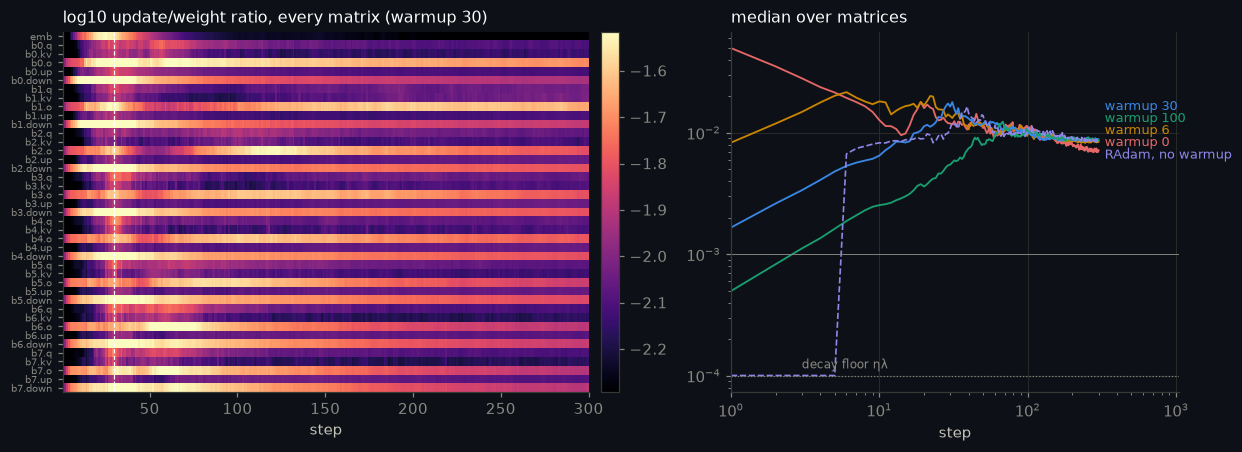

In [37]:
w_show = WARM
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]
mat = np.log10(ratio_matrix(ratio_runs[w_show])[:, MATS].T)
vlo, vhi = np.nanpercentile(mat, [2, 98])
im = ax.imshow(mat, aspect="auto", cmap="magma", vmin=vlo, vmax=vhi, interpolation="nearest",
               extent=(0.5, mat.shape[1] + 0.5, len(MATS) - 0.5, -0.5))
ax.set_yticks(range(len(MATS)), [names[i] for i in MATS], fontsize=6.5)
ax.grid(False)
ax.axvline(w_show, color=INK, lw=0.8, ls="--")
ax.set(xlabel="step", title=f"log10 update/weight ratio, every matrix (warmup {w_show})")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.ax.tick_params(colors=MUTED)
ax = axs[1]
med = {w: np.median(ratio_matrix(ratio_runs[w])[:, MATS], axis=1) for w in WARMUPS}
for w, col in zip(WARMUPS, (C["red"], C["yellow"], C["blue"], C["aqua"])):
    ax.plot(np.arange(1, len(med[w]) + 1), med[w], color=col, lw=1.2)
    label_end(ax, len(med[w]), med[w][-1], f"warmup {w}", col)
rmed = np.median(ratio_matrix(radam)[:, MATS], axis=1)
ax.plot(np.arange(1, len(rmed) + 1), rmed, "--", color=C["violet"], lw=1.1); label_end(ax, len(rmed), rmed[-1], "RAdam, no warmup", C["violet"], dy=-9)
ax.axhline(LR_BASE * 0.1, color=MUTED, lw=0.8, ls=":")
ax.text(3, LR_BASE * 0.1 * 1.15, "decay floor ηλ", color=MUTED, fontsize=8)
ax.axhline(1e-3, color=MUTED, lw=0.6)
ax.set(yscale="log", xscale="log", xlabel="step", xlim=(1, TOTAL * 3.5), title="median over matrices")
fig.tight_layout()
finish(fig, "update_ratio_warmup")

**Taking the ratio apart.** Three different things push the measured ratio around:
1. **The decay part.** AdamW shrinks every matrix by $\eta\lambda$ per step regardless of the
   gradient. That is a floor under the ratio, shown dotted above, and at short horizons it is not
   negligible.
2. **Adam's "fraction of η".** The gradient part of the update is $\eta\cdot\hat m/(\sqrt{\hat v}+\epsilon)$.
   Its RMS divided by $\eta$ is the $\rho$ above. It should start near 1 and fall as the gradients
   decorrelate.
3. **The weights themselves.** $\lVert W\rVert$ grows or shrinks as training proceeds.

Two more views from the same runs:
- The **spectral** ratio $\lVert\Delta W\rVert_2/\lVert W\rVert_2$ is how much the update can change
  the layer's output along its most-amplified direction. This is the quantity muP and Muon reason
  about.
- The **share of updates smaller than half a bf16 spacing** is the share that would be rounded away
  if the weights were stored in bf16. That is why training keeps an fp32 master copy.

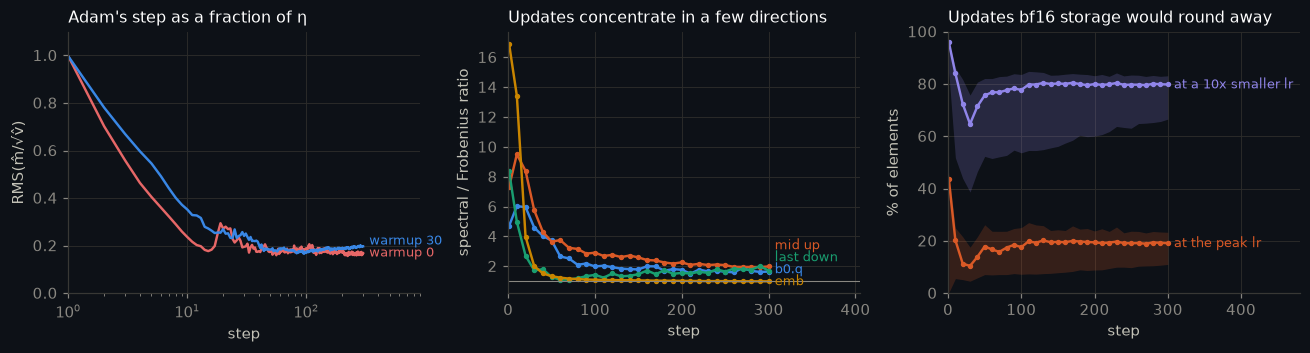

Adam's step as a fraction of η: step 1 1.00 (no warmup), last 50 steps 0.20
the decay floor ηλ = 1.0e-04; over the last 50 steps the median matrix ratio is 8.86e-03
spectral ratio / Frobenius ratio, last logged step: b0.q 1.6x, mid up 2.0x, last down 1.7x, emb 1.0x
share of matrix elements whose update is below half a bf16 spacing: 19% at the peak lr, 80% if the lr were 10x smaller, as at the end of a decay (median, last logged steps)
embedding rows, median update/weight ratio over the run:  100 most frequent 5.0e-03;  rank 100–1k 7.8e-03;  rank 1k–8k 6.1e-03;  rank ≥ 8k (rare/unseen) 5.5e-03;  in this batch 8.6e-03;  not in this batch 5.5e-03
✓ observed: Adam's step falls from 1.00 η at step 1 to 0.20 η once gradients decorrelate


✓ observed: at a decayed learning rate most updates are smaller than half a bf16 spacing: without an fp32 copy they would vanish


✓ observed: with a tied head, rare-token rows still move every step (the output softmax gives every row a gradient)



RAdam with no warmup: final validation loss 2.5769; AdamW warmup 0: 3.1002, AdamW warmup 6: 2.5163, AdamW warmup 30: 2.4540, AdamW warmup 100: 2.4345  (one seed each)


In [38]:
adam_frac = {w: np.median(ratio_matrix(ratio_runs[w], "adam_frac")[:, MATS], axis=1) for w in (0, WARM)}
grad_part = {w: np.median(ratio_matrix(ratio_runs[w], "grad")[:, MATS], axis=1) for w in (0, WARM)}
det = ratio_runs[WARM]["detail"]
dsteps = np.array(det["steps"])
spec = np.array(det["spectral"], dtype=float)
frob_ids = [names.index(n) for n in ("b0.q", f"b{BASE_ARCH['n_layer'] // 2}.up", f"b{BASE_ARCH['n_layer'] - 1}.down", "emb")]
frob = ratio_matrix(ratio_runs[WARM])[dsteps - 1][:, frob_ids]
lost = np.array(det["bf16_lost"], dtype=float)[:, MATS]
lost_floor = np.array(det["bf16_lost_floor"], dtype=float)[:, MATS]
rows = np.array([[np.nan if x is None else x for x in r] for r in det["emb_rows"]], dtype=float)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
ax = axs[0]
for w, col in ((0, C["red"]), (WARM, C["blue"])):
    ax.plot(np.arange(1, len(adam_frac[w]) + 1), adam_frac[w], color=col); label_end(ax, len(adam_frac[w]), adam_frac[w][-1], f"warmup {w}", col)
ax.set(xscale="log", xlabel="step", ylabel="RMS(m̂/√v̂)", title="Adam's step as a fraction of η", xlim=(1, TOTAL * 3), ylim=(0, 1.1))
ax = axs[1]
for j, (nm, col) in enumerate(zip(("b0.q", "mid up", "last down", "emb"), SERIES)):
    ax.plot(dsteps, spec[:, j] / frob[:, j], "-o", ms=2.5, color=col); label_end(ax, dsteps[-1], spec[-1, j] / frob[-1, j], nm, col)
ax.axhline(1, color=MUTED, lw=0.7)
ax.set(xlabel="step", ylabel="spectral / Frobenius ratio", title="Updates concentrate in a few directions", xlim=(0, TOTAL * 1.35))
ax = axs[2]
for arr, col, lab in ((lost, C["orange"], "at the peak lr"), (lost_floor, C["violet"], "at a 10x smaller lr")):
    ax.plot(dsteps, np.median(arr, 1) * 100, "-o", ms=2.5, color=col)
    ax.fill_between(dsteps, np.percentile(arr, 10, 1) * 100, np.percentile(arr, 90, 1) * 100, color=col, alpha=0.2, lw=0)
    label_end(ax, dsteps[-1], np.median(arr[-1]) * 100, lab, col)
ax.set(xlabel="step", ylabel="% of elements", ylim=(0, 100), xlim=(0, TOTAL * 1.6), title="Updates bf16 storage would round away")
fig.tight_layout()
finish(fig, "update_ratio_anatomy")

decay_share = float(np.median(1 - grad_part[WARM][-50:] / med[WARM][-50:]))
print(f"Adam's step as a fraction of η: step 1 {adam_frac[0][0]:.2f} (no warmup), last 50 steps {np.median(adam_frac[WARM][-50:]):.2f}")
print(f"the decay floor ηλ = {LR_BASE * 0.1:.1e}; over the last 50 steps the median matrix ratio is {np.median(med[WARM][-50:]):.2e}")
print(f"spectral ratio / Frobenius ratio, last logged step: " + ", ".join(f"{n} {v:.1f}x" for n, v in zip(("b0.q", "mid up", "last down", "emb"), spec[-1] / frob[-1])))
print(f"share of matrix elements whose update is below half a bf16 spacing: {np.median(lost[-5:]) * 100:.0f}% at the peak lr, "
      f"{np.median(lost_floor[-5:]) * 100:.0f}% if the lr were 10x smaller, as at the end of a decay (median, last logged steps)")
labels = ["100 most frequent", "rank 100–1k", "rank 1k–8k", "rank ≥ 8k (rare/unseen)", "in this batch", "not in this batch"]
print("embedding rows, median update/weight ratio over the run:  " + ";  ".join(f"{l} {np.nanmedian(rows[:, i]):.1e}" for i, l in enumerate(labels)))
observe("adam_fraction_falls", adam_frac[0][0] > 2 * np.median(adam_frac[WARM][-50:]),
        f"Adam's step falls from {adam_frac[0][0]:.2f} η at step 1 to {np.median(adam_frac[WARM][-50:]):.2f} η once gradients decorrelate")
observe("bf16_would_lose_updates_late", np.median(lost_floor[-5:]) > 0.5,
        "at a decayed learning rate most updates are smaller than half a bf16 spacing: without an fp32 copy they would vanish")
observe("rare_rows_move_tied", np.nanmedian(rows[:, 3]) > 0.1 * np.nanmedian(rows[:, 0]),
        "with a tied head, rare-token rows still move every step (the output softmax gives every row a gradient)")
print(f"\nRAdam with no warmup: final validation loss {final_loss(radam):.4f}; "
      + ", ".join(f"AdamW warmup {w}: {final_loss(ratio_runs[w]):.4f}" for w in WARMUPS) + "  (one seed each)")

if MODE != "learn":
    ANS["warmup"] = _clean(dict(
        warm=WARM, n_steps=n_steps, pairwise=PAIRWISE,
        stop={str(w): {f"{p:.0%}": int(np.median(v[p])) for p in RULES["warmup_stop"]["p"]} for w, v in WSTOP.items()},
        stop_range={str(w): [int(min(v[0.10])), int(max(v[0.10]))] for w, v in WSTOP.items()},
        plateau={str(w): int(np.median(v["plateau"])) for w, v in WSTOP.items()},
        peak_gap={str(w): int(np.median(v["peak_gap"])) for w, v in WSTOP.items()},
        max_ratio={str(w): v for w, v in mx.items()}, first_ratio={str(w): v for w, v in first.items()},
        adam_frac_first=adam_frac[0][0], adam_frac_late=float(np.median(adam_frac[WARM][-50:])),
        decay_floor=LR_BASE * 0.1, late_ratio=float(np.median(med[WARM][-50:])), decay_share=decay_share,
        spectral_over_frob=(spec[-1] / frob[-1]).tolist(), bf16_lost=float(np.median(lost[-5:])),
        bf16_lost_floor=float(np.median(lost_floor[-5:])),
        emb_rows={l: float(np.nanmedian(rows[:, i])) for i, l in enumerate(labels)},
        val={str(w): final_loss(r) for w, r in ratio_runs.items()}, radam_val=final_loss(radam)))
    save_results()

**What the measurements say.**

- **Skipping warmup is not transient.** Without warmup, the first steps move some matrices by up to
  20% of their size in one step. That run never catches up: its validation loss ends about 0.65
  higher, and its update/weight ratios stay well below those of the warmed-up runs to the end. By the
  rule fixed in §0, warmup's effect on the ratio **never ends** within 300 steps.
- **The length of warmup stops mattering much sooner.** Warmed-up runs of different lengths agree with
  each other from about step 140–150 (exploratory readout above). Their ratios settle near
  $9\times10^{-3}$ by about step 160, whatever the warmup length.
- **RAdam with no warmup recovers most, but not all, of the damage.**

> **Carry forward:** log $\lVert\Delta W\rVert/\lVert W\rVert$ for every matrix from step one.
> Warmup's job is the early steps where Adam moves every weight by nearly its full $\eta$. Skipping
> it leaves a lasting mark, while its exact length washes out within about 150 steps here.

## §6 Cosine vs WSD: planned for 300 steps, stopped at 200

**The situation.** Two runs of the same model are planned for 300 steps, one with a cosine schedule
and one with WSD. Both are stopped at step 200, because the budget changed, the cluster was
needed, or a better idea came along. Which of the two models do you keep?

**Intuition.**
- At step 200 the cosine run is about halfway down its decay. Its learning rate is already low, so
  its weights are relatively settled, and its loss is probably the lower of the two.
- The WSD run is still at its peak learning rate. Its loss is higher because the weights are still
  bouncing, but that state has a property cosine lacks: it is not committed to any length.
- Decaying a WSD checkpoint for a short while turns it into a finished model.
- Not decaying it lets training continue as if nothing happened.
- Cosine cannot do either. Its run length was fixed before the first step.

**Doing the comparison properly.**
1. **Tune both sides by the same rule.** Each schedule gets its own learning-rate grid (same points,
   same edge rule), then its own knob: the floor for cosine, the decay length for WSD (plus one 1−√
   shape trial). Each knob grid is extended by the same edge rule, so neither side's best setting
   is left sitting at the edge of what was tried.
2. **Three paired seeds** per arm. The same seed means the same initial weights and the same
   batches, so arms are compared by paired differences.
3. **Compute-matched alternatives.** Finished models that cost ≤ 200 steps are compared with each
   other, and those costing ≤ 240 with each other:
   - cosine planned for 200
   - a 40-step cooldown from WSD's step-160 checkpoint
   - an average of WSD's weights during its flat phase ("constant learning rate + weight EMA")
   - cosine planned for 240, against WSD's step-200 checkpoint plus a 40-step cooldown
4. **The keep decision follows the rule written in §0**, not the plot.

In [39]:
wsd_grid = lr_sweep(lambda lr: base_cfg(lr, kind="wsd", decay_frac=0.2), GRID_BASE, final_loss, max_ext=3)
LR_WSD = min((lr for lr in wsd_grid if math.isfinite(final_loss(wsd_grid[lr]))), key=lambda lr: final_loss(wsd_grid[lr]))
check(LR_WSD not in (min(wsd_grid), max(wsd_grid)), f"WSD's best peak learning rate ({LR_WSD:.0e}) is bracketed by its grid")

# Each schedule's own knob gets the same edge rule as the learning rate: if the best value sits at the edge of
# what was tried, try the next value out, until it is bracketed or the knob's feasible range ends.
def cos_cfg(fl):
    return base_cfg(LR_BASE) if fl == 0.1 else base_cfg(LR_BASE, floor=fl)       # floor 10% is the default


def wsd_cfg(df, shape="linear"):
    return base_cfg(LR_WSD, kind="wsd", decay_frac=df, **({} if shape == "linear" else dict(shape=shape)))


def knob_sweep(make, values, step_out, lo_lim, hi_lim, max_ext=8):
    """Extend at an edge until the best value is bracketed or the knob's feasible range ends."""
    res = {v: final_loss(run(make(v))) for v in values}
    for _ in range(max_ext):
        best = min(res, key=res.get)
        if best == max(res) and step_out(best, +1) <= hi_lim + 1e-9:
            new = step_out(best, +1)
        elif best == min(res) and step_out(best, -1) >= lo_lim - 1e-9:
            new = step_out(best, -1)
        else:
            break
        res[new] = final_loss(run(make(new)))
    return dict(sorted(res.items()))


# Feasible ranges: a cosine floor of 1.0 means no decay at all; WSD's decay length runs from 5% to 60% of the run.
LIMITS = {"cosine floor": (0.0, 1.0), "WSD decay length": (0.05, 0.6)}
cos_floor = knob_sweep(cos_cfg, [0.0, 0.1, 0.2], lambda v, d: round(v + 0.1 * d, 2), *LIMITS["cosine floor"])
wsd_decay = knob_sweep(wsd_cfg, [0.2, 0.3], lambda v, d: round(v * 2, 3) if d > 0 else round(v / 2, 3), *LIMITS["WSD decay length"])
for lab, sw in (("cosine floor", cos_floor), ("WSD decay length", wsd_decay)):
    b = min(sw, key=sw.get)
    at_limit = b in LIMITS[lab]
    observe(f"knob_bracketed_{lab.split()[0].lower()}", b not in (min(sw), max(sw)) or at_limit,
            f"the {lab} is bracketed: its best value ({b:g}) is inside the values tried ({min(sw):g}–{max(sw):g})"
            + (" or at the end of its feasible range" if at_limit else ""))
cos_variants = {f"cosine, floor {fl:.0%}": cos_cfg(fl) for fl in cos_floor}
wsd_variants = {f"WSD, last {df:.0%} linear": wsd_cfg(df) for df in wsd_decay}
wsd_variants["WSD, last 20% 1−√"] = wsd_cfg(0.2, "sqrt")
var_loss = {k: final_loss(run(c)) for k, c in {**cos_variants, **wsd_variants}.items()}
COS_KEY = min(cos_variants, key=var_loss.get)
WSD_KEY = min(wsd_variants, key=var_loss.get)
print(f"{'':<24}{'val@' + str(TOTAL):>9}")
for k, v in var_loss.items():
    print(f"{k:<24}{v:9.4f}{'  ← chosen' if k in (COS_KEY, WSD_KEY) else ''}")
BUDGET = {"cosine": len(cos_grid) + len(cos_variants) - 1, "WSD": len(wsd_grid) + len(wsd_variants) - 1}
print(f"tuning trials: cosine {BUDGET['cosine']}, WSD {BUDGET['WSD']} (learning-rate grid plus its own knob, "
      f"each extended at an edge by the same rule)")
print(f"peak learning rates: cosine {LR_BASE:.0e}, WSD {LR_WSD:.0e}")

✓ WSD's best peak learning rate (1e-03) is bracketed by its grid
✓ observed: the cosine floor is bracketed: its best value (1) is inside the values tried (0–1) or at the end of its feasible range


✓ observed: the WSD decay length is bracketed: its best value (0.1) is inside the values tried (0.05–0.3)


                          val@300
cosine, floor 0%           2.6427
cosine, floor 10%          2.5796
cosine, floor 20%          2.5437
cosine, floor 30%          2.5166
cosine, floor 40%          2.5031
cosine, floor 50%          2.4889
cosine, floor 60%          2.4748
cosine, floor 70%          2.4626
cosine, floor 80%          2.4580
cosine, floor 90%          2.4572
cosine, floor 100%         2.4540  ← chosen
WSD, last 5% linear        2.4146
WSD, last 10% linear       2.4057  ← chosen
WSD, last 20% linear       2.4092
WSD, last 30% linear       2.4228
WSD, last 20% 1−√          2.4181
tuning trials: cosine 15, WSD 9 (learning-rate grid plus its own knob, each extended at an edge by the same rule)
peak learning rates: cosine 1e-03, WSD 1e-03


In [40]:
COS_CFG, WSD_CFG = cos_variants[COS_KEY], wsd_variants[WSD_KEY]
EMA_DECAYS = [0.9, 0.95, 0.98]


def wsd_arms(seed):
    cfg = dict(WSD_CFG, seed=seed, ckpt_at=[BRANCH, STOP], ema=EMA_DECAYS)
    main, ck = train(cfg)
    shape = WSD_CFG["sched"].get("shape", "linear")
    out = dict(main=main)
    for name, start, total in (("cool_from_branch", BRANCH, STOP), ("cool_from_stop", STOP, STOP + COOL)):
        if start not in ck:                                             # the main run diverged before this step
            continue
        bcfg = dict(WSD_CFG, seed=seed, steps=total, resume=ck[start], eval_at=[total], sample_at=[total], log_every=0,
                    sched=dict(kind="wsd", warmup=WARM, decay_frac=COOL / total, shape=shape))
        out[name] = train(bcfg)[0]
    return out


arms = {}
for s in SEEDS:
    w = experiment(f"wsd_arms|{cfg_name(dict(WSD_CFG, seed=s))}", lambda s=s: wsd_arms(s))
    arms[s] = dict(cos300=run(dict(COS_CFG, seed=s)),
                   cos200=run(dict(COS_CFG, seed=s, steps=STOP)),
                   cos240=run(dict(COS_CFG, seed=s, steps=STOP + COOL)),
                   wsd300=w["main"], wsd_cool160=w.get("cool_from_branch"), wsd_cool200=w.get("cool_from_stop"))


def arm_loss(arm, step):
    vals = []
    for s in SEEDS:
        r = arms[s][arm]
        vals.append(final_loss(r, step) if r else float("inf"))
    return np.array(vals)


best_ema = min(EMA_DECAYS, key=lambda d: np.mean([arms[s]["wsd300"]["ema_evals"].get(str(d), {}).get(str(STOP), np.inf) for s in SEEDS]))
ema200 = np.array([arms[s]["wsd300"]["ema_evals"][str(best_ema)][str(STOP)] for s in SEEDS])
TABLE = {  # name: (compute in steps, per-seed losses)
    f"cosine-{TOTAL}, stopped at {STOP}": (STOP, arm_loss("cos300", STOP)),
    f"WSD-{TOTAL}, stopped at {STOP}": (STOP, arm_loss("wsd300", STOP)),
    f"cosine planned for {STOP}": (STOP, arm_loss("cos200", STOP)),
    f"WSD checkpoint {BRANCH} + {COOL}-step cooldown": (STOP, arm_loss("wsd_cool160", STOP)),
    f"WSD flat phase, weight EMA {best_ema} (constant lr + EMA)": (STOP, ema200),
    f"cosine-{TOTAL}, continued to {STOP + COOL}": (STOP + COOL, arm_loss("cos300", STOP + COOL)),
    f"WSD checkpoint {STOP} + {COOL}-step cooldown": (STOP + COOL, arm_loss("wsd_cool200", STOP + COOL)),
    f"cosine planned for {STOP + COOL}": (STOP + COOL, arm_loss("cos240", STOP + COOL)),
    f"cosine-{TOTAL}, completed": (TOTAL, arm_loss("cos300", TOTAL)),
    f"WSD-{TOTAL}, completed": (TOTAL, arm_loss("wsd300", TOTAL)),
}
ref = TABLE[f"cosine-{TOTAL}, stopped at {STOP}"][1]
print(f"{'':<52}{'compute':>8}{'val loss':>10}{'± s.d.':>8}{'vs cosine@' + str(STOP):>14}{'paired SE':>10}")
for k, (c, v) in TABLE.items():
    d = v - ref
    se = d.std(ddof=1) / math.sqrt(len(d)) if len(d) > 1 else float("nan")
    print(f"{k:<52}{c:>8}{v.mean():10.4f}{v.std(ddof=1):8.4f}{d.mean():+14.4f}{se:10.4f}")

                                                     compute  val loss  ± s.d. vs cosine@200 paired SE
cosine-300, stopped at 200                               200    2.7544  0.0185       +0.0000    0.0000
WSD-300, stopped at 200                                  200    2.7544  0.0185       +0.0000    0.0000
cosine planned for 200                                   200    2.7544  0.0185       +0.0000    0.0000
WSD checkpoint 160 + 40-step cooldown                    200    2.7431  0.0234       -0.0113    0.0029
WSD flat phase, weight EMA 0.9 (constant lr + EMA)       200    2.7169  0.0217       -0.0375    0.0021
cosine-300, continued to 240                             240    2.6175  0.0136       -0.1369    0.0029
WSD checkpoint 200 + 40-step cooldown                    240    2.5901  0.0163       -0.1643    0.0020
cosine planned for 240                                   240    2.6175  0.0136       -0.1369    0.0029
cosine-300, completed                                    300    2.4641  0

**The state each model is in at step 200.** A loss is one number, so here is the rest of the picture:
- where each learning rate sits
- how hard the gradients are pushing, and whether clipping is firing
- how far each step moves the weights
- what each model writes

In [41]:
def state_at(res, step, peak):
    h = res["hist"]
    i = step - 1
    rat = res["ratios"]
    j = rat["steps"].index(step) if step in rat["steps"] else None
    mats = [k for k, n in enumerate(res["tensors"]) if n == "emb" or n.split(".")[-1] in ("q", "kv", "o", "up", "down")]
    return dict(val=final_loss(res, step), train=float(np.mean(h["loss"][step - 10:step])),
                lr=h["lr"][i] * peak, gnorm=float(np.mean(h["gnorm"][i - 9:i + 1])),
                clipped=float(np.mean(h["clipped"][max(0, i - 49):i + 1])),
                ratio=float(np.median(np.array(rat["total"][j])[mats])) if j is not None else float("nan"))


STATE = {}
for arm, lab, peak in (("cos300", f"cosine-{TOTAL} at step {STOP}", LR_BASE), ("wsd300", f"WSD-{TOTAL} at step {STOP}", LR_WSD)):
    rows = [state_at(arms[s][arm], STOP, peak) for s in SEEDS]
    STATE[lab] = {k: float(np.mean([r[k] for r in rows])) for k in rows[0]}
print(f"{'':<26}{'val loss':>9}{'train loss':>11}{'lr now':>9}{'grad norm':>10}{'clipped':>9}{'update/weight':>14}")
for lab, st in STATE.items():
    print(f"{lab:<26}{st['val']:9.4f}{st['train']:11.4f}{st['lr']:9.1e}{st['gnorm']:10.3f}{st['clipped']:9.0%}{st['ratio']:14.2e}")
for arm, lab in (("cos300", f"cosine at {STOP}"), ("wsd300", f"WSD at {STOP}"), ("wsd_cool160", f"WSD {BRANCH} + cooldown")):
    smp = (arms[SEEDS[0]][arm] or {}).get("samples", {}).get(str(STOP))
    print(f"\n{lab}:  {smp}")

                           val loss train loss   lr now grad norm  clipped update/weight
cosine-300 at step 200       2.7544     2.8001  1.0e-03     0.726       3%      8.89e-03
WSD-300 at step 200          2.7544     2.8001  1.0e-03     0.726       3%      8.89e-03

cosine at 200:  Once upon a time, there was a little boy named Tim. Tim had a favorite toy. It loved to run and play outside. One day, Tim and his friend, Sam, came to play. It was a big mess! Tim told Sam, "

WSD at 200:  Once upon a time, there was a little boy named Tim. Tim had a favorite toy. It loved to run and play outside. One day, Tim and his friend, Sam, came to play. It was a big mess! Tim told Sam, "

WSD 160 + cooldown:  Once upon a time, there was a little boy named Tim. Tim was a very special boy. He had many friends who loved to play with. One day, Tim found a small toy that was very small. He wanted to see what made.
Tim


In [42]:
# The keep decision, by the rule fixed in §0
def paired(a, b):
    """Mean and standard error over seeds of the paired difference a - b."""
    d = np.asarray(a) - np.asarray(b)
    return float(d.mean()), float(d.std(ddof=1) / math.sqrt(len(d)))


def batch_losses(arm, step):
    """Per-eval-batch losses averaged over seeds, for an eval-sampling bootstrap."""
    return np.mean([np.array(arms[s][arm]["evals"][str(step)]["batches"]) for s in SEEDS], axis=0)


opt_cos = {f"cosine-{TOTAL} at {STOP}": ("cos300", STOP), f"cosine-{TOTAL} continued to {STOP + COOL}": ("cos300", STOP + COOL)}
opt_wsd = {f"WSD at {STOP}": ("wsd300", STOP), f"WSD {STOP} + {COOL}-step cooldown": ("wsd_cool200", STOP + COOL)}
best_c = min(opt_cos, key=lambda k: arm_loss(*opt_cos[k]).mean())
best_w = min(opt_wsd, key=lambda k: arm_loss(*opt_wsd[k]).mean())
diff, se = paired(arm_loss(*opt_wsd[best_w]), arm_loss(*opt_cos[best_c]))
bd = batch_losses(*opt_wsd[best_w]) - batch_losses(*opt_cos[best_c])
rng_b = np.random.default_rng(0)
se_eval = float(np.std([rng_b.choice(bd, len(bd)).mean() for _ in range(2000)]))
tie = abs(diff) <= RULES["keep_at_200"]["tie_se"] * se
KEEP = "WSD" if (tie or diff < 0) else "cosine"
print(f"best option within +20% compute: cosine → {best_c} ({arm_loss(*opt_cos[best_c]).mean():.4f});  "
      f"WSD → {best_w} ({arm_loss(*opt_wsd[best_w]).mean():.4f})")
print(f"paired difference WSD − cosine: {diff:+.4f} ± {se:.4f} (SE over seeds; eval-sampling SE {se_eval:.4f})"
      f"  →  {'within 2 SE, a tie, so ' if tie else ''}keep the {KEEP} run")
raw, raw_se = paired(arm_loss("wsd300", STOP), arm_loss("cos300", STOP))
print(f"as stopped, at step {STOP}: WSD − cosine = {raw:+.4f} ± {raw_se:.4f}")
observe("cosine_lower_at_stop", raw > 0,                                                         # raw = WSD − cosine
        f"expected the cosine model to have the lower loss as stopped at step {STOP}; measured WSD − cosine = {raw:+.4f}"
        + (" (the same run: tuned cosine never decays)" if raw == 0 else ""))
d1, s1 = paired(arm_loss("wsd_cool200", STOP + COOL), arm_loss("cos300", STOP + COOL))
observe("wsd_cooldown_beats_cosine", d1 < 0,
        f"a {COOL}-step cooldown from WSD's step-{STOP} checkpoint vs cosine-{TOTAL} at the same compute: {d1:+.4f} ± {s1:.4f}")
d2, s2 = paired(arm_loss("wsd_cool200", STOP + COOL), arm_loss("cos240", STOP + COOL))
observe("wsd_cooldown_vs_cos240", d2 <= 2 * s2,
        f"a {COOL}-step cooldown from WSD's step-{STOP} checkpoint vs a cosine run planned for {STOP + COOL} from the start: "
        f"{d2:+.4f} ± {s2:.4f} (within 2 SE or better)")
d3, s3 = paired(ema200, arm_loss("cos200", STOP))
observe("ema_matches_cosine200", d3 <= 2 * s3,
        f"averaging WSD's flat-phase weights (EMA {best_ema}) vs a cosine run planned for {STOP}: {d3:+.4f} ± {s3:.4f} (within 2 SE or better)")

# How the verdict moved as cosine's own knob was tuned. Every floor below has three seeds already measured.
VERDICT_BY_FLOOR = {}
for fl in sorted(cos_floor):
    runs = {s: R.get(cfg_name(dict(cos_cfg(fl), seed=s))) for s in SEEDS}
    if not all(runs.values()):
        continue
    c200 = np.array([final_loss(runs[s], STOP) for s in SEEDS])
    c240 = np.array([final_loss(runs[s], STOP + COOL) for s in SEEDS])
    opt = c240 if c240.mean() < c200.mean() else c200
    dd, ee = paired(arm_loss(*opt_wsd[best_w]), opt)
    VERDICT_BY_FLOOR[fl] = dict(diff=dd, se=ee, keep="WSD" if (dd < 0 or abs(dd) <= RULES["keep_at_200"]["tie_se"] * ee) else "cosine",
                                tie=abs(dd) <= RULES["keep_at_200"]["tie_se"] * ee)
print(f"\nthe keep decision as cosine's floor is tuned (WSD's best option − cosine's best option, 3 paired seeds):")
for fl, v in VERDICT_BY_FLOOR.items():
    print(f"  cosine floor {fl:>4.0%}: {v['diff']:+.4f} ± {v['se']:.4f}  →  keep {v['keep']}{' (tie)' if v['tie'] else ''}")

best option within +20% compute: cosine → cosine-300 continued to 240 (2.6175);  WSD → WSD 200 + 40-step cooldown (2.5901)
paired difference WSD − cosine: -0.0274 ± 0.0019 (SE over seeds; eval-sampling SE 0.0007)  →  keep the WSD run
as stopped, at step 200: WSD − cosine = +0.0000 ± 0.0000
✗ not observed: expected the cosine model to have the lower loss as stopped at step 200; measured WSD − cosine = +0.0000 (the same run: tuned cosine never decays)


✓ observed: a 40-step cooldown from WSD's step-200 checkpoint vs cosine-300 at the same compute: -0.0274 ± 0.0019


✓ observed: a 40-step cooldown from WSD's step-200 checkpoint vs a cosine run planned for 240 from the start: -0.0274 ± 0.0019 (within 2 SE or better)


✓ observed: averaging WSD's flat-phase weights (EMA 0.9) vs a cosine run planned for 200: -0.0375 ± 0.0021 (within 2 SE or better)



the keep decision as cosine's floor is tuned (WSD's best option − cosine's best option, 3 paired seeds):
  cosine floor  10%: -0.1039 ± 0.0050  →  keep WSD
  cosine floor  20%: -0.0862 ± 0.0039  →  keep WSD
  cosine floor  50%: -0.0563 ± 0.0018  →  keep WSD
  cosine floor 100%: -0.0274 ± 0.0019  →  keep WSD


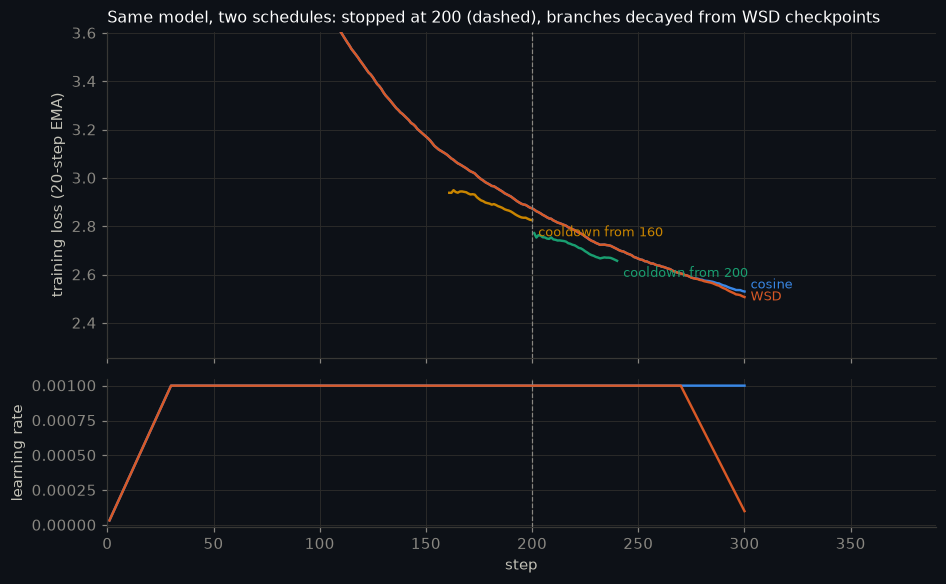

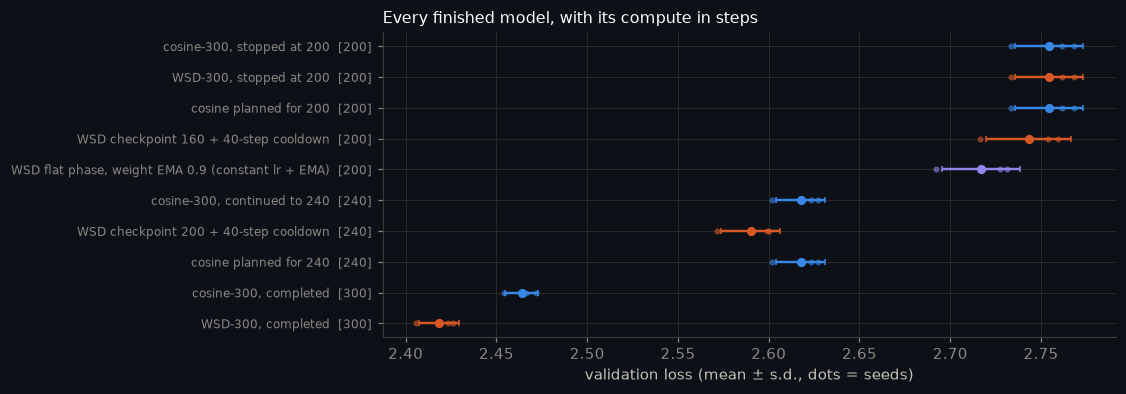

In [43]:
fig, axs = plt.subplots(2, 1, figsize=(8.6, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
ax = axs[0]
for arm, col, lab in (("cos300", C["blue"], "cosine"), ("wsd300", C["orange"], "WSD")):
    L = np.mean([ema_curve(arms[s][arm]["hist"]["loss"], 20) for s in SEEDS], axis=0)
    ax.plot(np.arange(1, len(L) + 1), L, color=col); label_end(ax, len(L), L[-1], lab, col)
for arm, col in (("wsd_cool160", C["yellow"]), ("wsd_cool200", C["aqua"])):
    if all(arms[s][arm] for s in SEEDS):
        L = np.mean([ema_curve(arms[s][arm]["hist"]["loss"], 20) for s in SEEDS], axis=0)
        x0 = BRANCH if arm == "wsd_cool160" else STOP
        ax.plot(np.arange(x0 + 1, x0 + len(L) + 1), L, color=col)
        label_end(ax, x0 + len(L), L[-1], f"cooldown from {x0}", col, dy=-8)
ax.axvline(STOP, color=MUTED, lw=0.8, ls="--")
lo = min(np.min(arm_loss("cos300", TOTAL)), np.min(arm_loss("wsd300", TOTAL)))
ax.set(ylim=(lo - 0.15, lo + 1.2), ylabel="training loss (20-step EMA)", xlim=(0, TOTAL * 1.3),
       title=f"Same model, two schedules: stopped at {STOP} (dashed), branches decayed from WSD checkpoints")
ax = axs[1]
for res, col, peak in ((arms[SEEDS[0]]["cos300"], C["blue"], LR_BASE), (arms[SEEDS[0]]["wsd300"], C["orange"], LR_WSD)):
    ax.plot(np.arange(1, len(res["hist"]["lr"]) + 1), np.array(res["hist"]["lr"]) * peak, color=col)
ax.axvline(STOP, color=MUTED, lw=0.8, ls="--")
ax.set(xlabel="step", ylabel="learning rate")
fig.tight_layout()
finish(fig, "cosine_vs_wsd")

fig, ax = plt.subplots(figsize=(8.6, 3.6))
keys = list(TABLE)
for i, k in enumerate(keys):
    c, v = TABLE[k]
    col = C["blue"] if "cosine" in k else (C["violet"] if "EMA" in k else C["orange"])
    ax.errorbar(v.mean(), i, xerr=v.std(ddof=1), fmt="o", color=col, ms=5, capsize=2)
    ax.plot(v, [i] * len(v), ".", color=col, alpha=0.5)
ax.set_yticks(range(len(keys)), [f"{k}  [{TABLE[k][0]}]" for k in keys], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="validation loss (mean ± s.d., dots = seeds)", title="Every finished model, with its compute in steps")
finish(fig, "cosine_vs_wsd_arms")

if MODE != "learn":
    ANS["schedules"] = _clean(dict(
        lr_cos=LR_BASE, lr_wsd=LR_WSD, cos_variant=COS_KEY, wsd_variant=WSD_KEY, budget=BUDGET, variants=var_loss,
        table={k: dict(compute=c, mean=float(v.mean()), sd=float(v.std(ddof=1)), seeds=v.tolist()) for k, (c, v) in TABLE.items()},
        state=STATE, raw_diff=raw, raw_se=raw_se, cooldown_vs_cos300=[d1, s1], cooldown_vs_cos240=[d2, s2], ema_vs_cos200=[d3, s3],
        best_cos=best_c, best_wsd=best_w, diff=diff, se=se, se_eval=se_eval, tie=bool(tie), keep=KEEP,
        best_ema=best_ema, by_floor={f"{k:g}": v for k, v in VERDICT_BY_FLOOR.items()}, cos_floor_grid={f"{k:g}": v for k, v in cos_floor.items()},
        samples={a: (arms[SEEDS[0]][a] or {}).get("samples", {}).get(str(STOP)) for a in ("cos300", "wsd300", "wsd_cool160")}))
    save_results()

**What the measurements say.** Keep the WSD run.

- **Tuned on its own knob, cosine stopped decaying.** Every step up in cosine's floor improved the
  loss at 300, from 0% to 100%. Its best floor is 100%, which means no decay at all. So in this regime
  the tuned "cosine" run is a constant learning rate, the same run as WSD's flat phase. At step 200
  the two models are therefore *identical*, as the state table shows, and the as-stopped comparison
  is an exact tie.
- **What separates them is WSD's ability to decay late.** A 40-step cooldown from WSD's step-200
  checkpoint beats simply continuing for the same compute, by a small but clear margin over 3 paired
  seeds. At the planned 300 steps WSD's final 10% decay wins as well.
- **Averaging WSD's flat-phase weights (EMA)** gives the best model of all at 200 steps of compute.
- **Every decay that starts early hurts here** (0.16 tokens per parameter, still far from
  convergence). Cosine's floor wanted to go to 100%, and WSD's best decay was only the last 10%.
  Longer runs are where earlier decay is expected to pay off, and they are not tested here.
- **Procedure, measured.** The first pass tried cosine floors only up to 20%, and the best sat at that
  edge. Extending the floor grid by the same edge rule used for learning rates, until it hit the
  floor's physical limit, shrank WSD's margin roughly threefold. The verdict never flipped (table
  above). This is the "tune both sides" principle at work inside this notebook.

> **Carry forward:** compare schedules by what you can *do* with the model when the run is cut
> short, compute-matched and tuned on both sides. Here, tuning the baseline properly turned "cosine
> vs WSD" into "constant vs decay-at-the-end". WSD's real advantage is the option to decay late, from
> any checkpoint.

## §M Muon against AdamW, both tuned

Muon (R.6) is the clearest current case of an optimizer whose reported advantage depends on how
well the baseline was tuned. Published speedups over AdamW range from about 2× down to about 1.1×.
The lower figures come from comparisons in which both sides were tuned to the same standard.

**Setup.**
- The base model, cosine schedule, 300 steps.
- Muon updates the 40 hidden matrices: momentum 0.95, Nesterov, weight decay 0.1, and the learning
  rate scaled to match AdamW's update RMS (`match_rms_adamw`).
- The embedding and the norm gains stay on AdamW at its tuned learning rate. Muon only applies to
  2-D hidden matrices.
- **Equal budgets.** Muon's learning rate is tuned on the same grid, with the same edge rule and the
  same number of trials as AdamW's in §3, and then run on the same three seeds.

**Rule (§0).**
- A speedup is claimed only if the tuned-vs-tuned paired loss difference exceeds 2 standard errors.
- Speedup = how many steps AdamW needs to reach its own final loss, divided by how many Muon needs
  to reach that same loss.

Finally, the same tuned Muon run is set against AdamW at *mis-tuned* learning rates: the grid
neighbours of its best, and PyTorch's default of 1e-3. That reproduces how an inflated claim is
produced.

✓ Muon's best learning rate (4e-03) is bracketed by its grid
tuning trials: AdamW 5 grid points + 2 seeds; Muon 5 grid points + 2 seeds
tuned Muon vs tuned AdamW, final validation loss: 2.3809 vs 2.6064; paired difference -0.2255 ± 0.0154 (SE, 3 seeds)
speedup to AdamW's final loss: 1.43x (per seed: 1.37, 1.43, 1.48)
by the rule fixed in §0: a Muon speedup is claimed

the same tuned Muon run (seed 0) against differently tuned AdamW baselines:
  vs AdamW at 5e-04 (half its best)       loss difference -0.3436   apparent speedup 1.59x
  vs AdamW at 2e-03 (double its best)     loss difference -0.2618   apparent speedup 1.48x
  vs AdamW at its tuned lr                loss difference -0.1989   apparent speedup 1.37x
✓ observed: a mis-tuned AdamW baseline inflates Muon's apparent speedup from 1.37x to 1.59x


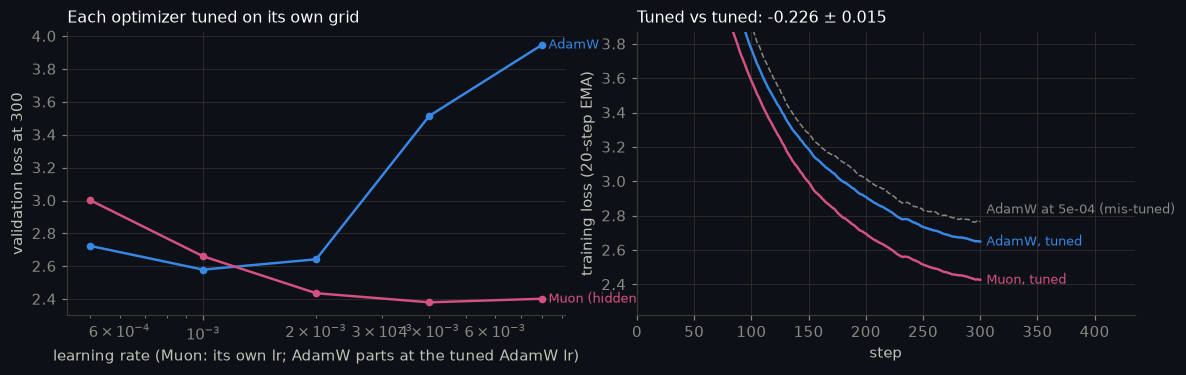

In [44]:
muon_grid = lr_sweep(lambda lr: base_cfg(LR_BASE, opt="muon", muon_lr=lr), GRID_BASE, final_loss, max_ext=3)
LR_MUON = min((lr for lr in muon_grid if math.isfinite(final_loss(muon_grid[lr]))), key=lambda lr: final_loss(muon_grid[lr]))
check(LR_MUON not in (min(muon_grid), max(muon_grid)), f"Muon's best learning rate ({LR_MUON:.0e}) is bracketed by its grid")
muon_seeds = {s: run(base_cfg(LR_BASE, opt="muon", muon_lr=LR_MUON, seed=s)) for s in SEEDS}
print(f"tuning trials: AdamW {len(cos_grid)} grid points + {len(SEEDS) - 1} seeds; Muon {len(muon_grid)} grid points + {len(SEEDS) - 1} seeds")


def steps_to(curve, target):
    hit = np.nonzero(curve <= target)[0]
    return int(hit[0]) + 1 if hit.size else None


def speedup(challenger, baseline):
    """Steps the baseline needs to reach its final (smoothed) loss / steps the challenger needs for the same loss."""
    c, b = ema_curve(challenger["hist"]["loss"], 20), ema_curve(baseline["hist"]["loss"], 20)
    n = min(len(c), len(b))
    t = steps_to(c[:n], b[n - 1])
    if t:
        return n / t
    t = steps_to(b[:n], c[n - 1])                       # the challenger is slower: invert
    return t / n if t else float("nan")


mu_l = np.array([final_loss(muon_seeds[s]) for s in SEEDS])
ad_l = np.array([final_loss(cos_seeds[s]) for s in SEEDS])
md = mu_l - ad_l
m_diff, m_se = float(md.mean()), float(md.std(ddof=1) / math.sqrt(len(md)))
spd = np.array([speedup(muon_seeds[s], cos_seeds[s]) for s in SEEDS])
claim = m_diff < -RULES["optimizer_claim"]["se"] * m_se
print(f"tuned Muon vs tuned AdamW, final validation loss: {mu_l.mean():.4f} vs {ad_l.mean():.4f}; "
      f"paired difference {m_diff:+.4f} ± {m_se:.4f} (SE, {len(SEEDS)} seeds)")
print(f"speedup to AdamW's final loss: {spd.mean():.2f}x (per seed: {', '.join(f'{x:.2f}' for x in spd)})")
print(f"by the rule fixed in §0: {'a Muon speedup is claimed' if claim else 'no speedup is claimed: the difference is within 2 SE'}")

APPARENT = {}
for lab, lr in ((f"AdamW at {LR_BASE / 2:.0e} (half its best)", LR_BASE / 2), (f"AdamW at {LR_BASE * 2:.0e} (double its best)", LR_BASE * 2),
                ("AdamW at 1e-3 (PyTorch's default)", 1e-3)):
    if lr in cos_grid and lr != LR_BASE:
        base = cos_grid[lr]
        APPARENT[lab] = (final_loss(muon_seeds[0]) - final_loss(base), speedup(muon_seeds[0], base))
APPARENT["AdamW at its tuned lr"] = (final_loss(muon_seeds[0]) - final_loss(cos_seeds[0]), speedup(muon_seeds[0], cos_seeds[0]))
print("\nthe same tuned Muon run (seed 0) against differently tuned AdamW baselines:")
for lab, (d, sp) in APPARENT.items():
    print(f"  vs {lab:<36} loss difference {d:+.4f}   apparent speedup {sp:.2f}x")
if len(APPARENT) > 1:
    worst = max(v[1] for k, v in APPARENT.items() if k != "AdamW at its tuned lr")
    observe("mistuned_baseline_inflates", worst > APPARENT["AdamW at its tuned lr"][1],
            f"a mis-tuned AdamW baseline inflates Muon's apparent speedup from {APPARENT['AdamW at its tuned lr'][1]:.2f}x to {worst:.2f}x")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.5))
for grid, col, lab in ((cos_grid, C["blue"], "AdamW"), (muon_grid, C["magenta"], "Muon (hidden matrices)")):
    xs = list(grid)
    a1.plot(xs, [final_loss(grid[x]) for x in xs], "-o", ms=4, color=col)
    label_end(a1, xs[-1], final_loss(grid[xs[-1]]), lab, col)
a1.set(xscale="log", xlabel="learning rate (Muon: its own lr; AdamW parts at the tuned AdamW lr)", ylabel=f"validation loss at {TOTAL}",
       title="Each optimizer tuned on its own grid")
for res_d, col, lab in ((cos_seeds, C["blue"], "AdamW, tuned"), (muon_seeds, C["magenta"], "Muon, tuned")):
    L = np.mean([ema_curve(res_d[s]["hist"]["loss"], 20) for s in SEEDS], axis=0)
    a2.plot(np.arange(1, len(L) + 1), L, color=col); label_end(a2, len(L), L[-1], lab, col)
for lab, lr in ((f"AdamW at {LR_BASE / 2:.0e}", LR_BASE / 2),):
    if lr in cos_grid:
        L = ema_curve(cos_grid[lr]["hist"]["loss"], 20)
        a2.plot(np.arange(1, len(L) + 1), L, "--", color=MUTED, lw=1); label_end(a2, len(L), L[-1], lab + " (mis-tuned)", MUTED, dy=8)
lo = min(mu_l.min(), ad_l.min())
a2.set(ylim=(lo - 0.15, lo + 1.5), xlim=(0, TOTAL * 1.45), xlabel="step", ylabel="training loss (20-step EMA)",
       title=f"Tuned vs tuned: {m_diff:+.3f} ± {m_se:.3f}")
fig.tight_layout()
finish(fig, "muon_vs_adamw")

if MODE != "learn":
    ANS["muon"] = _clean(dict(lr_muon=LR_MUON, lr_adamw=LR_BASE, grid={f"{k:.3g}": final_loss(v) for k, v in muon_grid.items()},
                              muon=mu_l.tolist(), adamw=ad_l.tolist(), diff=m_diff, se=m_se, speedup=spd.tolist(),
                              claim=bool(claim), apparent={k: list(v) for k, v in APPARENT.items()},
                              trials=dict(adamw=len(cos_grid), muon=len(muon_grid))))
    save_results()

**What the measurements say.** With both sides tuned on the same grid and the same seeds, Muon's
advantage is real here: about 1.4× fewer steps to AdamW's final loss, close to what has been
reported for well-tuned comparisons at around 0.1B parameters. Running AdamW at half its best
learning rate makes the same Muon run look about 1.6× faster. The gap between those two numbers is
pure tuning effort.

> **Carry forward:** an optimizer comparison is a statement about two tuning efforts as much as about
> two algorithms. Give both sides the same grid, the same trial count and the same seeds, and
> report the paired difference with its error bar, then the speedup.

## §7 How the best learning rate moves with width, and what muP changes

**The question.** Sweeping the learning rate on a small model is cheap, and on a large one it is
not. Can the value found at width 256 be used at width 4,096?

**Intuition.** Under the standard parameterization (SP):
- Every hidden matrix is initialized at $1/\sqrt{\text{fan-in}}$.
- Adam moves each of its entries by about $\eta$.
- A wider matrix sums more of those entries into each output. Its output therefore changes more per
  step, roughly in proportion to width, unless $\eta$ shrinks to compensate.

So the best $\eta$ should fall roughly as $1/\text{width}$. muP rescales the per-layer learning rates
and the output multiplier so that this dependence cancels, and the best $\eta$ stays put.

**Protocol.**
- The width family from §3 (4 layers, head size 64) at widths 256, 512, 1,024.
- Everything except width held fixed: depth, the 16,384-token batch, 300 steps, warmup 30 + cosine.
- Coarse factor-2 grid, 1.25e-4 … 1.6e-2, one seed, extended at an edge if needed.
- Then refined with √2-spaced points around each width's best, and three seeds on the five points
  there.
- **Minimum (rule, §0):** the vertex of a parabola in $\log_2\eta$ through those five points, with a
  90% bootstrap interval over seeds.

**Extrapolation, then a test of it.**
- Fit $\log_2\eta^* = a + b\log_2(\text{width})$ and predict width 2,048.
- Then measure width 2,048 around the prediction. The prediction error at 2,048 calibrates the
  confidence in the 4,096 answer.

In [45]:
WIDTHS, HOLD = qk([256, 512, 1024], [64, 128, 256]), qk(2048, 512)
CF = qk(2.0, 4.0)                                                    # coarse grid factor
COARSE = [qk(1.25e-4, 5e-4) * CF ** k for k in range(qk(8, 4))]
SWEEP_SEEDS = qk([0, 1, 2], [0, 1])


def width_cfg(width, lr, seed=0, mup=False):
    mup = mup and width != BASE_WIDTH_MUP                            # at the reference width muP *is* SP: reuse those runs
    return dict(family="width", width=width, mup=mup, seed=seed, steps=TOTAL, sched=dict(kind="cosine", warmup=WARM),
                opt=dict(kind="adamw", lr=lr, betas=(0.9, 0.95), wd=0.1), clip=1.0,
                eval_at=[qk(150, 30), TOTAL], log_every=qk(25, 10), diag=True)


def lat(lr):
    """Snap to the √(factor) lattice the grids live on, so equal learning rates get identical names."""
    k = round(2 * math.log(lr / COARSE[0], CF))
    return COARSE[0] * CF ** (k / 2)


def sweep_width(width, mup=False, refine=True):
    coarse = lr_sweep(lambda lr: width_cfg(width, lat(lr), mup=mup), COARSE, final_loss, factor=CF)
    pts = {lat(lr): r for lr, r in coarse.items()}
    fin = {lr: final_loss(r) for lr, r in pts.items() if math.isfinite(final_loss(r))}
    a = min(fin, key=fin.get)
    if not refine:
        return dict(points={lr: [final_loss(r)] for lr, r in pts.items()}, runs=pts, center=a)
    five = [lat(a * CF ** (k / 2)) for k in (-2, -1, 0, 1, 2)]
    losses = {}
    for lr in sorted(set(pts) | set(five)):
        seeds = SWEEP_SEEDS if lr in five else [0]
        losses[lr] = [final_loss(run(width_cfg(width, lr, seed=s, mup=mup))) for s in seeds]
    return dict(points=losses, runs={lr: run(width_cfg(width, lr, mup=mup)) for lr in losses}, center=a, five=five)


def vertex(lrs, losses_per_lr, rng=None):
    """Parabola vertex in log2(lr); with rng, resample seeds at every point (bootstrap)."""
    xs, ys = [], []
    for lr, ls in zip(lrs, losses_per_lr):
        ls = [l for l in ls if math.isfinite(l)]
        if not ls:
            continue
        xs.append(math.log2(lr))
        ys.append(np.mean(rng.choice(ls, len(ls))) if rng is not None else np.mean(ls))
    xs, ys = np.array(xs), np.array(ys)
    if len(xs) < 3:                                                  # too few finite points for a parabola: use the grid argmin
        i = int(np.argmin(ys))
        return float(xs[i]), float(ys[i]), np.array([0.0, 0.0, ys[i]])
    c = np.polyfit(xs, ys, 2)
    x = -c[1] / (2 * c[0]) if c[0] > 0 else xs[np.argmin(ys)]
    x = float(np.clip(x, xs.min(), xs.max()))
    return x, float(np.polyval(c, x)), c


def analyse(sw, boot=RULES["lr_minimum"]["boot"]):
    five = sw.get("five") or sorted(sw["points"], key=lambda lr: abs(math.log(lr / sw["center"])))[:3]
    five = sorted(five)
    L = [sw["points"][lr] for lr in five]
    x, y, c = vertex(five, L)
    rng = np.random.default_rng(0)
    bx = np.array([vertex(five, L, rng)[0] for _ in range(boot)])
    lo, hi = np.percentile(bx, [5, 95])
    cost2 = float(max(np.polyval(c, x + 1), np.polyval(c, x - 1)) - y)          # loss cost of a 2x error either way
    return dict(lr=2 ** x, lo=2 ** lo, hi=2 ** hi, loss=y, boot=bx, cost2x=cost2, five=five)


SP = {w: sweep_width(w) for w in WIDTHS}
SPA = {w: analyse(SP[w]) for w in WIDTHS}
print(f"{'width':>6} {'params':>8} {'best lr (vertex)':>17} {'90% interval':>21} {'loss there':>11} {'cost of 2x error':>17}")
for w in WIDTHS:
    a = SPA[w]
    print(f"{w:>6} {WIDTH_PARAMS[w] / 1e6:7.1f}M {a['lr']:17.2e}   [{a['lo']:.2e}, {a['hi']:.2e}] {a['loss']:11.4f} {a['cost2x']:+17.4f}")
for w in WIDTHS:
    lrs = sorted(SP[w]["points"])
    check(SP[w]["center"] not in (lrs[0], lrs[-1]), f"width {w}: the best learning rate is bracketed by the grid")
observe("best_loss_falls_with_width", all(SPA[a]["loss"] > SPA[b]["loss"] for a, b in zip(WIDTHS, WIDTHS[1:])),
        "the best achievable loss falls as width grows (wider is better at its own best learning rate)")

 width   params  best lr (vertex)          90% interval  loss there  cost of 2x error
   256     7.2M          5.63e-03   [5.54e-03, 5.73e-03]      2.4944           +0.0810
   512    20.8M          2.53e-03   [2.48e-03, 2.59e-03]      2.3651           +0.0954
  1024    66.6M          1.20e-03   [1.19e-03, 1.21e-03]      2.2527           +0.1079
✓ width 256: the best learning rate is bracketed by the grid
✓ width 512: the best learning rate is bracketed by the grid
✓ width 1024: the best learning rate is bracketed by the grid
✓ observed: the best achievable loss falls as width grows (wider is better at its own best learning rate)


In [46]:
X = np.log2(WIDTHS)
Y = np.log2([SPA[w]["lr"] for w in WIDTHS])
slope, icpt = np.polyfit(X, Y, 1)
B = np.stack([SPA[w]["boot"] for w in WIDTHS], 1)                   # bootstrap vertices, paired by index
bfit = np.array([np.polyfit(X, b, 1) for b in B])
pred = lambda width, fit=(slope, icpt): 2 ** (fit[0] * math.log2(width) + fit[1])
pred_hold = pred(HOLD)
pred_hold_ci = 2 ** np.percentile(bfit[:, 0] * math.log2(HOLD) + bfit[:, 1], [5, 95])
print(f"fit: log2(best lr) = {slope:.2f} · log2(width) + {icpt:.2f}   (slope 90% interval "
      f"[{np.percentile(bfit[:, 0], 5):.2f}, {np.percentile(bfit[:, 0], 95):.2f}]; the inverse-width rule says −1)")
print(f"prediction for width {HOLD}: {pred_hold:.2e}  (90% interval {pred_hold_ci[0]:.2e} … {pred_hold_ci[1]:.2e})")

# Held-out width: five √2-spaced points centred on the prediction, extended once at an edge if needed.
hold_pts = [lat(pred_hold * CF ** (k / 2)) for k in (-2, -1, 0, 1, 2)]
HOLD_RUNS = {lr: run(width_cfg(HOLD, lr)) for lr in hold_pts}
for _ in range(4):
    fin = {lr: final_loss(r) for lr, r in HOLD_RUNS.items() if math.isfinite(final_loss(r))}
    best = min(fin, key=fin.get)
    lo_, hi_ = min(HOLD_RUNS), max(HOLD_RUNS)
    if best not in (lo_, hi_):
        break
    new = lat(best / CF ** 0.5) if best == lo_ else lat(best * CF ** 0.5)
    HOLD_RUNS[new] = run(width_cfg(HOLD, new))
HOLD_RUNS = dict(sorted(HOLD_RUNS.items()))
fin = {lr: final_loss(r) for lr, r in HOLD_RUNS.items() if math.isfinite(final_loss(r))}
hb = min(fin, key=fin.get)
near = sorted(HOLD_RUNS, key=lambda lr: abs(math.log(lr / hb)))[:5]
hx, hy, _ = vertex(sorted(near), [[final_loss(HOLD_RUNS[lr])] for lr in sorted(near)])
hold_lr = 2 ** hx
err_oct = math.log2(hold_lr / pred_hold)
print(f"measured at width {HOLD}: best lr {hold_lr:.2e} (one seed)  →  the prediction was off by {err_oct:+.2f} octaves")
HOLD_BRACKETED = hb not in (min(HOLD_RUNS), max(HOLD_RUNS))
observe("hold_bracketed", HOLD_BRACKETED, f"width {HOLD}: the best learning rate is bracketed by the points measured around the prediction")

X4, Y4 = np.append(X, math.log2(HOLD)), np.append(Y, hx)
slope4, icpt4 = np.polyfit(X4, Y4, 1)
b4 = np.array([np.polyfit(X4, np.append(b, hx), 1) for b in B])
TARGET = 4096
ans_lr = pred(TARGET, (slope4, icpt4))
ans_ci = 2 ** np.percentile(b4[:, 0] * math.log2(TARGET) + b4[:, 1], [5, 95])
ci_oct = math.log2(ans_ci[1] / ans_ci[0])
cr = RULES["confidence_4096"]
CONF = "high" if (abs(err_oct) < cr["high_err_oct"] and ci_oct < cr["high_ci_oct"]) else ("medium" if abs(err_oct) < cr["medium_err_oct"] else "low")
if not HOLD_BRACKETED:
    CONF = "low"                                                     # an unbracketed check gives only a lower bound on the error
naive = SPA[WIDTHS[0]]["lr"] * WIDTHS[0] / TARGET
print(f"\nrefit on {len(X4)} widths: slope {slope4:.2f}.  Width {TARGET}: use {ans_lr:.2e} "
      f"(90% interval {ans_ci[0]:.2e} … {ans_ci[1]:.2e}, {ci_oct:.2f} octaves wide).  Confidence by the rule in §0: {CONF.upper()}")
print(f"for comparison, scaling width {WIDTHS[0]}'s best by 1/width gives {naive:.2e}; carrying it over unchanged gives {SPA[WIDTHS[0]]['lr']:.2e}")
# The bootstrap interval only resamples seeds; it says nothing about whether a straight line in log-log is the right
# model. The held-out width measures that directly: one octave of extrapolation missed by err_oct. 4,096 is again one
# octave beyond the data, so use that miss as the honest error band.
band = ans_lr * 2.0 ** (np.array([-1, 1]) * max(abs(err_oct), ci_oct / 2))
print(f"honest band: the same procedure missed by {abs(err_oct):.2f} octaves one octave out at {HOLD}, so expect the best lr at "
      f"{TARGET} within {band[0]:.2e} … {band[1]:.2e}; the bootstrap interval above reflects seed noise only")

fit: log2(best lr) = -1.11 · log2(width) + 1.42   (slope 90% interval [-1.13, -1.10]; the inverse-width rule says −1)
prediction for width 2048: 5.51e-04  (90% interval 5.39e-04 … 5.61e-04)
measured at width 2048: best lr 5.92e-04 (one seed)  →  the prediction was off by +0.10 octaves
✓ observed: width 2048: the best learning rate is bracketed by the points measured around the prediction



refit on 4 widths: slope -1.08.  Width 4096: use 2.74e-04 (90% interval 2.71e-04 … 2.76e-04, 0.03 octaves wide).  Confidence by the rule in §0: HIGH
for comparison, scaling width 256's best by 1/width gives 3.52e-04; carrying it over unchanged gives 5.63e-03
honest band: the same procedure missed by 0.10 octaves one octave out at 2048, so expect the best lr at 4096 within 2.55e-04 … 2.94e-04; the bootstrap interval above reflects seed noise only


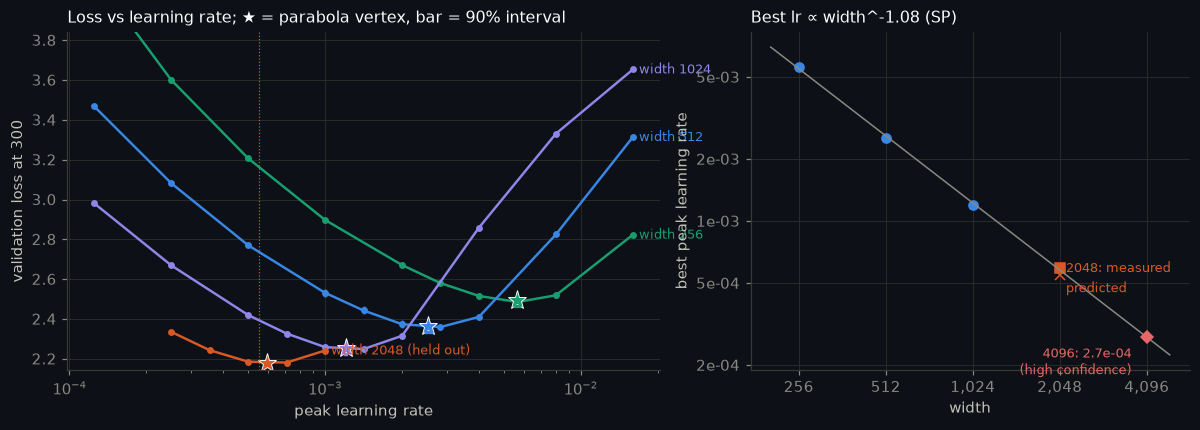

In [47]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1.35, 1]))
cols = dict(zip(WIDTHS + [HOLD], (C["aqua"], C["blue"], C["violet"], C["orange"])))
for w in WIDTHS:
    lrs = sorted(SP[w]["points"])
    m = [np.mean([l for l in SP[w]["points"][lr] if math.isfinite(l)] or [np.nan]) for lr in lrs]
    a1.plot(lrs, m, "-o", ms=3.5, color=cols[w])
    for lr in lrs:
        ls = SP[w]["points"][lr]
        if len(ls) > 1:
            a1.plot([lr] * len(ls), ls, ".", color=cols[w], alpha=0.45, ms=4)
    a = SPA[w]
    a1.plot(a["lr"], a["loss"], "*", ms=13, color=cols[w], mec=INK, mew=0.6)
    a1.plot([a["lo"], a["hi"]], [a["loss"] - 0.03] * 2, color=cols[w], lw=2.2)
    label_end(a1, lrs[-1], m[-1], f"width {w}", cols[w])
hl = list(HOLD_RUNS)
a1.plot(hl, [final_loss(HOLD_RUNS[lr]) for lr in hl], "-o", ms=3.5, color=cols[HOLD])
a1.plot(hold_lr, hy, "*", ms=13, color=cols[HOLD], mec=INK, mew=0.6)
label_end(a1, hl[-1], final_loss(HOLD_RUNS[hl[-1]]), f"width {HOLD} (held out)", cols[HOLD])
a1.axvline(pred_hold, color=cols[HOLD], lw=0.8, ls=":")
finite_all = [l for w in WIDTHS for ls in SP[w]["points"].values() for l in ls if math.isfinite(l)]
a1.set(xscale="log", ylim=(min(finite_all) - 0.1, min(finite_all) + 1.6), xlabel="peak learning rate",
       ylabel=f"validation loss at {TOTAL}", title="Loss vs learning rate; ★ = parabola vertex, bar = 90% interval")
ws = np.array(WIDTHS + [HOLD, TARGET])
a2.loglog(WIDTHS, [SPA[w]["lr"] for w in WIDTHS], "o", color=C["blue"], ms=6)
for w in WIDTHS:
    a2.plot([w, w], [SPA[w]["lo"], SPA[w]["hi"]], color=C["blue"], lw=1.6)
a2.plot(HOLD, hold_lr, "s", color=cols[HOLD], ms=6); label_end(a2, HOLD, hold_lr, f"{HOLD}: measured", cols[HOLD])
a2.plot(HOLD, pred_hold, "x", color=cols[HOLD], ms=7); label_end(a2, HOLD, pred_hold, "predicted", cols[HOLD], dy=-9)
xx = np.geomspace(WIDTHS[0] * 0.8, TARGET * 1.2, 50)
a2.plot(xx, [pred(x, (slope4, icpt4)) for x in xx], color=MUTED, lw=1)
a2.plot([TARGET, TARGET], ans_ci, color=C["red"], lw=2); a2.plot(TARGET, ans_lr, "D", color=C["red"], ms=6)
a2.annotate(f"{TARGET}: {ans_lr:.1e}\n({CONF} confidence)", (TARGET, ans_lr), xytext=(-10, -6), textcoords="offset points",
             color=C["red"], fontsize=8.5, ha="right", va="top")
a2.set(xlabel="width", ylabel="best peak learning rate", title=f"Best lr ∝ width^{slope4:.2f} (SP)")
a2.minorticks_off()
a2.set_xticks([int(w) for w in ws], [f"{int(w):,}" for w in ws])
yt = [y for y in (2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2) if a2.get_ylim()[0] <= y <= a2.get_ylim()[1]]
a2.set_yticks(yt, [f"{y:.0e}" for y in yt])
fig.tight_layout()
finish(fig, "lr_vs_width")

**Why the right-hand side of each curve is a cliff.** Every sweep run ends with two diagnostics:
- the largest attention logit $q\cdot k/\sqrt{d}$ in any layer and head
- the RMS of the output logits

Both grow with the learning rate, and they grow faster in wider models. That growth is the failure
that QK-norm, logit soft-capping and MuonClip exist to prevent.

The same runs also log the update/weight ratio of the input embedding, the hidden matrices and the
untied output head separately. That shows whether one learning rate suits all three.

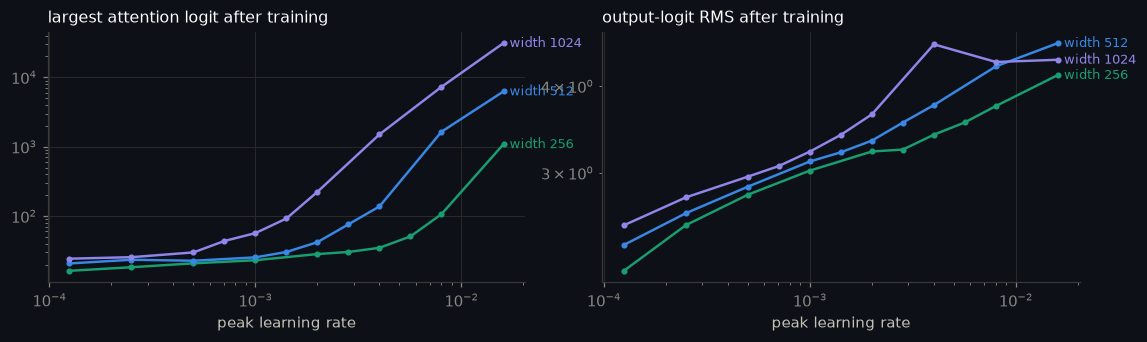

width   256 at its best lr, second half of the run: update/weight  embedding 5.9e-04   hidden matrices 9.6e-03   output head 6.4e-03
width   512 at its best lr, second half of the run: update/weight  embedding 2.8e-04   hidden matrices 7.8e-03   output head 5.2e-03
width  1024 at its best lr, second half of the run: update/weight  embedding 1.4e-04   hidden matrices 5.9e-03   output head 4.1e-03


In [48]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for w in WIDTHS:
    lrs = [lr for lr in sorted(SP[w]["runs"]) if SP[w]["runs"][lr] and SP[w]["runs"][lr].get("diag")]
    for ax, key in zip(axs, ("max_attn_logit", "logit_rms")):
        ys = [SP[w]["runs"][lr]["diag"][key] for lr in lrs]
        ax.plot(lrs, ys, "-o", ms=3, color=cols[w]); label_end(ax, lrs[-1], ys[-1], f"width {w}", cols[w])
axs[0].set(xscale="log", yscale="log", xlabel="peak learning rate", title="largest attention logit after training")
axs[1].set(xscale="log", yscale="log", xlabel="peak learning rate", title="output-logit RMS after training")
fig.tight_layout()
finish(fig, "lr_cliff_diagnostics")

HEADBODY = {}
for w in WIDTHS:
    r = SP[w]["runs"][lat(SPA[w]["lr"])] if lat(SPA[w]["lr"]) in SP[w]["runs"] else SP[w]["runs"][SP[w]["center"]]
    names_w = r["tensors"]
    tot = np.array(r["ratios"]["total"], dtype=float)
    late = tot[len(tot) // 2:]
    body = [i for i, n in enumerate(names_w) if n.split(".")[-1] in ("q", "kv", "o", "up", "down")]
    HEADBODY[w] = dict(emb=float(np.median(late[:, names_w.index("emb")])), body=float(np.median(late[:, body])),
                       head=float(np.median(late[:, names_w.index("head")])))
    print(f"width {w:>5} at its best lr, second half of the run: update/weight  embedding {HEADBODY[w]['emb']:.1e}   "
          f"hidden matrices {HEADBODY[w]['body']:.1e}   output head {HEADBODY[w]['head']:.1e}")

### What muP changes

**Coordinate check first.** A muP implementation is trusted only after this check passes:
- Train each width for 10 steps at the *same* learning rate.
- Measure the RMS of the output logits and of the last block's output.

Under SP the logits blow up with width, because the output layer's updates add up coherently over
more inputs. Under a correct muP they stay roughly flat.

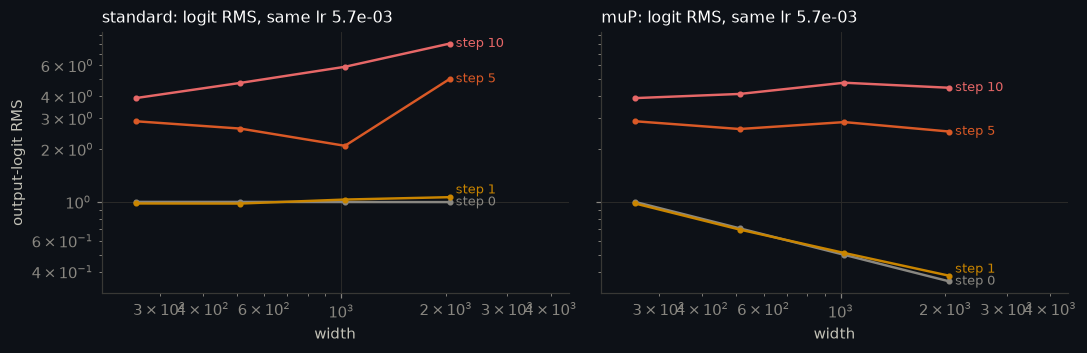

logit RMS after 10 steps grows 2.0x from width 256 to 2048 under SP, 1.1x under muP
✓ observed: muP keeps the output logits flatter across width than SP does


In [49]:
def coord_check(width, mup, lr, steps=10):
    seed_all(0)
    cfg = width_cfg(width, lr, mup=mup)
    model = make_model(cfg).to(DEV)
    opt = make_opts(model, cfg["opt"])[0]
    for g in opt.param_groups:
        g["lr"] = g["peak"]
    xb, _ = eval_batches("width", 16)[0]
    rows = []
    for s in range(steps + 1):
        col = []
        with torch.no_grad(), autocast():
            model(xb[:8], collect=col)
        rows.append(dict(col))
        if s == steps:
            break
        win = REMAP[WIN["width"].batch(0, s, 16)].to(DEV)
        with autocast():
            loss = model(win[:, :-1], win[:, 1:])
        loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
    del model, opt
    free_gpu()
    return rows


CC_LR = lat(SPA[WIDTHS[0]]["lr"])
CC = experiment("coord_check", lambda: {f"{'mup' if m else 'sp'}-{w}": coord_check(w, m, CC_LR)
                                        for m in (False, True) for w in WIDTHS + [HOLD]})
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
growth = {}
for ax, m in zip(axs, ("sp", "mup")):
    for step, col in zip((0, 1, 5, 10), (MUTED, C["yellow"], C["orange"], C["red"])):
        ys = [CC[f"{m}-{w}"][step]["logits"] for w in WIDTHS + [HOLD]]
        ax.plot(WIDTHS + [HOLD], ys, "-o", ms=3, color=col); label_end(ax, HOLD, ys[-1], f"step {step}", col)
    growth[m] = CC[f"{m}-{HOLD}"][10]["logits"] / CC[f"{m}-{WIDTHS[0]}"][10]["logits"]
    ax.set(xscale="log", yscale="log", xlabel="width", xlim=(WIDTHS[0] * 0.8, HOLD * 2.2),
           title=f"{'standard' if m == 'sp' else 'muP'}: logit RMS, same lr {CC_LR:.1e}")
axs[0].set_ylabel("output-logit RMS")
fig.tight_layout()
finish(fig, "mup_coord_check")
print(f"logit RMS after 10 steps grows {growth['sp']:.1f}x from width {WIDTHS[0]} to {HOLD} under SP, {growth['mup']:.1f}x under muP")
observe("coord_check_mup_flatter", growth["mup"] < growth["sp"], "muP keeps the output logits flatter across width than SP does")

**The muP sweep.** The same coarse grid at widths 512 and 1,024 (width 256 is shared: there the two
parameterizations are the same model). If muP is working, the three minima line up.

muP width   256: best lr 5.39e-03   loss 2.4951   (SP, same estimator: 5.39e-03, 2.4951)
muP width   512: best lr 4.77e-03   loss 2.3698   (SP, same estimator: 2.47e-03, 2.3592)
muP width  1024: best lr 4.45e-03   loss 2.2922   (SP, same estimator: 1.18e-03, 2.2492)
spread of the best learning rate across widths 256–1024 (seed 0, coarse grid, same estimator): SP 2.19 octaves, muP 0.27 octaves
✓ observed: muP narrows the spread of best learning rates (2.19 → 0.27 octaves)



width 2048 at width 256's best lr (5.7e-03), no retuning:  SP 3.3320   muP 2.2280   (SP tuned at 2048: 2.1804)
✓ observed: carrying width 256's learning rate to width 2048 works better under muP than under SP


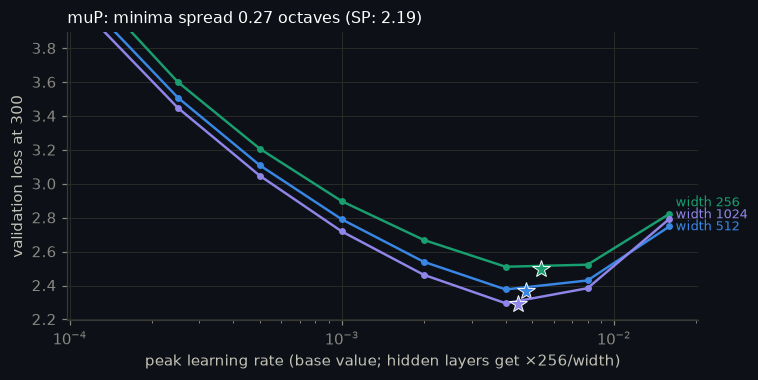

In [50]:
MUP = {w: sweep_width(w, mup=True, refine=False) for w in WIDTHS}
MUPA = {w: analyse(MUP[w], boot=1) for w in WIDTHS}


def on_coarse(lr):
    k = math.log(lr / COARSE[0], CF)
    return abs(k - round(k)) < 1e-6


# the same estimator for both parameterizations: seed 0, coarse grid only, 3-point vertex
SPC = {w: analyse(dict(points={lr: [final_loss(r)] for lr, r in SP[w]["runs"].items() if on_coarse(lr)}, center=SP[w]["center"]), boot=1)
       for w in WIDTHS}
for w in WIDTHS:
    print(f"muP width {w:>5}: best lr {MUPA[w]['lr']:.2e}   loss {MUPA[w]['loss']:.4f}   (SP, same estimator: {SPC[w]['lr']:.2e}, {SPC[w]['loss']:.4f})")
mup_spread = math.log2(max(MUPA[w]["lr"] for w in WIDTHS) / min(MUPA[w]["lr"] for w in WIDTHS))
sp_spread = math.log2(max(SPC[w]["lr"] for w in WIDTHS) / min(SPC[w]["lr"] for w in WIDTHS))
print(f"spread of the best learning rate across widths {WIDTHS[0]}–{WIDTHS[-1]} (seed 0, coarse grid, same estimator): "
      f"SP {sp_spread:.2f} octaves, muP {mup_spread:.2f} octaves")
observe("mup_aligns_minima", mup_spread < sp_spread, f"muP narrows the spread of best learning rates ({sp_spread:.2f} → {mup_spread:.2f} octaves)")

# Transfer test at the held-out width: the width-256 optimum, used unchanged, under SP and under muP.
T_LR = lat(SPA[WIDTHS[0]]["lr"])
sp_naive = run(width_cfg(HOLD, T_LR))
mup_naive = run(width_cfg(HOLD, T_LR, mup=True))
print(f"\nwidth {HOLD} at width {WIDTHS[0]}'s best lr ({T_LR:.1e}), no retuning:  SP {final_loss(sp_naive):.4f}   "
      f"muP {final_loss(mup_naive):.4f}   (SP tuned at {HOLD}: {hy:.4f})")
observe("mup_transfer_beats_naive_sp", final_loss(mup_naive) < final_loss(sp_naive),
        f"carrying width {WIDTHS[0]}'s learning rate to width {HOLD} works better under muP than under SP")

fig, ax = plt.subplots(figsize=(7.4, 3.4))
for w in WIDTHS:
    lrs = sorted(MUP[w]["points"])
    ys = [MUP[w]["points"][lr][0] for lr in lrs]
    ax.plot(lrs, ys, "-o", ms=3.5, color=cols[w]); label_end(ax, lrs[-1], ys[-1], f"width {w}", cols[w])
    ax.plot(MUPA[w]["lr"], MUPA[w]["loss"], "*", ms=12, color=cols[w], mec=INK, mew=0.6)
fin_m = [l for w in WIDTHS for ls in MUP[w]["points"].values() for l in ls if math.isfinite(l)]
ax.set(xscale="log", ylim=(min(fin_m) - 0.1, min(fin_m) + 1.6), xlabel="peak learning rate (base value; hidden layers get ×256/width)",
       ylabel=f"validation loss at {TOTAL}", title=f"muP: minima spread {mup_spread:.2f} octaves (SP: {sp_spread:.2f})")
finish(fig, "mup_sweep")

if MODE != "learn":
    ANS["width"] = _clean(dict(
        sp={str(w): dict(lr=SPA[w]["lr"], lo=SPA[w]["lo"], hi=SPA[w]["hi"], loss=SPA[w]["loss"], cost2x=SPA[w]["cost2x"],
                         n_params=WIDTH_PARAMS[w], points={f"{lr:.4g}": v for lr, v in SP[w]["points"].items()}) for w in WIDTHS},
        slope=slope, slope_ci=np.percentile(bfit[:, 0], [5, 95]).tolist(), pred_hold=pred_hold, pred_hold_ci=pred_hold_ci.tolist(),
        hold=dict(width=HOLD, lr=hold_lr, loss=hy, err_oct=err_oct, points={f"{lr:.4g}": final_loss(r) for lr, r in HOLD_RUNS.items()}),
        slope4=slope4, answer=dict(width=TARGET, lr=ans_lr, ci=ans_ci.tolist(), ci_oct=ci_oct, confidence=CONF, band=band.tolist()),
        naive_inverse_width=naive, headbody=HEADBODY, coord_growth=growth,
        mup={str(w): dict(lr=MUPA[w]["lr"], loss=MUPA[w]["loss"]) for w in WIDTHS}, mup_spread=mup_spread, sp_spread=sp_spread,
        transfer=dict(lr=T_LR, sp=final_loss(sp_naive), mup=final_loss(mup_naive), sp_tuned=hy)))
    save_results()

**What the measurements say.**

- **Under SP the best learning rate fell slightly faster than 1/width.** The fitted slope is about
  −1.1. A fit on three widths predicted width 2,048 to within 0.1 octave (about 7%), which is why
  the width-4,096 answer is given with a band of that size. The band is wider than the bootstrap
  interval, which only sees seed noise.
- **Under muP the three minima moved by only about a quarter of an octave**, against more than two
  octaves under SP.
- **Carrying width 256's best learning rate straight to width 2,048** cost more than a full nat of
  loss under SP, and only a few hundredths under muP.
- **One learning rate does not suit every layer under SP.** At each width's best learning rate the
  input embedding (initialized at scale 1) moved 15–40× less, relative to its size, than the hidden
  matrices. muP gives it its own constant rate for this reason.

> **Carry forward:** under the standard parameterization the best learning rate moves with width,
> so a small-model sweep has to be extrapolated, and the extrapolation has to be tested at a held-out
> width before it is trusted. muP's whole value is that it removes that step: it does not make the
> model better, it makes the small model's measurement valid for the large one.

## §8 Tune both sides before accepting a comparison

Every comparison in this notebook gave each side its own tuning, by the same rule. This section uses
the grids already measured to show what happens when that discipline slips: the challenger is
tuned, and the baseline is not. No new training is needed.

**How to read the plots.**
- **Left:** the baseline's *learning rate* is off. The x-axis is how far it sits from the baseline's
  own best, in octaves (factors of 2). At $x = 0$ the comparison is fair, and everywhere else the
  apparent advantage is partly a tuning artifact.
- **Right:** the baseline's *own knob* is off. This happened in this very notebook. Cosine's floor was
  first tried only at 0, 10 and 20%, and the best sat at the edge. Extending the grid by the same edge
  rule used for learning rates moved cosine's best floor all the way to 100% (no decay), and
  WSD's advantage shrank accordingly.

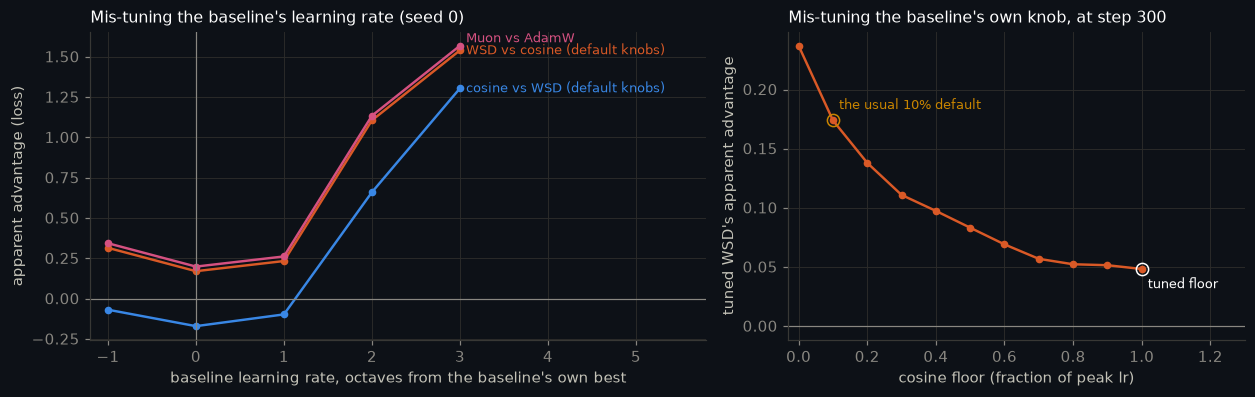

WSD vs cosine (default knobs)  fair comparison: +0.1704    worst mis-tuned baseline (+3 octaves): +1.5399
Muon vs AdamW                  fair comparison: +0.1989    worst mis-tuned baseline (+3 octaves): +1.5684
cosine vs WSD (default knobs)  fair comparison: -0.1704    worst mis-tuned baseline (+3 octaves): +1.3040
WSD (tuned) vs cosine floor    fair comparison: +0.0483    at cosine's 10% default floor: +0.1739
the step-200 keep decision itself: with cosine's floor at its default the WSD margin would have been larger; tuning the floor shrank it to -0.0274 (see §6)

tuning budget per side, and what was held fixed:
  cosine vs WSD      15 vs 9 trials                     tuned: lr grid + own knob, edge-extended (floor / decay length) fixed: warmup, β, weight decay, batch, data, seeds
  Muon vs AdamW      5 vs 5 lr points, 3 seeds each     tuned: Muon's lr; AdamW's lr                            fixed: momentum 0.95 / β (0.9, 0.95), decay 0.1, schedule
  SP vs muP (width)  30 vs 24 runs   

In [51]:
def apparent(challenger_best_loss, baseline_grid, baseline_best_lr):
    xs, ys = [], []
    for lr, r in baseline_grid.items():
        L = final_loss(r)
        if math.isfinite(L):
            xs.append(math.log2(lr / baseline_best_lr))
            ys.append(L - challenger_best_loss)                         # > 0: the challenger looks better
    return np.array(xs), np.array(ys)


PAIRS = {   # learning-rate grids; both schedules at their default knob (cosine floor 10%, WSD decay 20%)
    "WSD vs cosine (default knobs)": (final_loss(wsd_grid[LR_WSD]), cos_grid, LR_BASE, C["orange"]),
    "Muon vs AdamW": (final_loss(muon_grid[LR_MUON]), cos_grid, LR_BASE, C["magenta"]),
    "cosine vs WSD (default knobs)": (final_loss(cos_grid[LR_BASE]), wsd_grid, LR_WSD, C["blue"]),
}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw=dict(width_ratios=[1.35, 1]))
TB = {}
for lab, (best, grid, blr, col) in PAIRS.items():
    xs, ys = apparent(best, grid, blr)
    ax.plot(xs, ys, "-o", ms=4, color=col); label_end(ax, xs[-1], ys[-1], lab, col)
    TB[lab] = dict(fair=float(ys[xs == 0][0]) if (xs == 0).any() else float("nan"),
                   worst=float(ys.max()), worst_at_oct=float(xs[ys.argmax()]))
ax.axvline(0, color=MUTED, lw=0.8); ax.axhline(0, color=MUTED, lw=0.8)
ax.set(xlabel="baseline learning rate, octaves from the baseline's own best", ylabel="apparent advantage (loss)",
       xlim=(ax.get_xlim()[0], ax.get_xlim()[1] + 2.6), title="Mis-tuning the baseline's learning rate (seed 0)")
# The baseline's own knob matters as much: tuned WSD against cosine at every floor that was tried.
wsd_best = var_loss[WSD_KEY]
fls = sorted(cos_floor)
adv = [cos_floor[fl] - wsd_best for fl in fls]
bx.plot(fls, adv, "-o", ms=4, color=C["orange"])
best_fl = min(cos_floor, key=cos_floor.get)
bx.plot(best_fl, cos_floor[best_fl] - wsd_best, "o", ms=8, mfc="none", color=INK)
label_end(bx, best_fl, cos_floor[best_fl] - wsd_best, "tuned floor", INK, dy=-10)
bx.plot(0.1, cos_floor[0.1] - wsd_best, "o", ms=8, mfc="none", color=C["yellow"])
label_end(bx, 0.1, cos_floor[0.1] - wsd_best, "the usual 10% default", C["yellow"], dy=10)
bx.axhline(0, color=MUTED, lw=0.8)
bx.set(xlabel="cosine floor (fraction of peak lr)", ylabel="tuned WSD's apparent advantage", xlim=(-0.03, max(fls) + 0.3),
       title=f"Mis-tuning the baseline's own knob, at step {TOTAL}")
fig.tight_layout()
finish(fig, "tune_both_sides")
TB["WSD (tuned) vs cosine floor"] = dict(fair=float(cos_floor[best_fl] - wsd_best), worst=float(max(adv)),
                                         at_default_floor=float(cos_floor[0.1] - wsd_best), tuned_floor=best_fl)
for lab, v in TB.items():
    extra = f"    at cosine's 10% default floor: {v['at_default_floor']:+.4f}" if "at_default_floor" in v else \
        f"    worst mis-tuned baseline ({v['worst_at_oct']:+.0f} octaves): {v['worst']:+.4f}"
    print(f"{lab:<30} fair comparison: {v['fair']:+.4f}{extra}")
print(f"the step-{STOP} keep decision itself: with cosine's floor at its default the WSD margin would have been larger; "
      f"tuning the floor shrank it to {ANS.get('schedules', {}).get('diff', float('nan')):+.4f} (see §6)")

print("\ntuning budget per side, and what was held fixed:")
PARITY = [
    ("cosine vs WSD", f"{BUDGET['cosine']} vs {BUDGET['WSD']} trials", "lr grid + own knob, edge-extended (floor / decay length)", "warmup, β, weight decay, batch, data, seeds"),
    ("Muon vs AdamW", f"{len(muon_grid)} vs {len(cos_grid)} lr points, {len(SEEDS)} seeds each", "Muon's lr; AdamW's lr", "momentum 0.95 / β (0.9, 0.95), decay 0.1, schedule"),
    ("SP vs muP (width)", f"{sum(len(SP[w]['points']) for w in WIDTHS)} vs {sum(len(MUP[w]['points']) for w in WIDTHS)} runs", "lr grid per width", "depth, batch, steps, schedule"),
]
for row in PARITY:
    print(f"  {row[0]:<18} {row[1]:<34} tuned: {row[2]:<48} fixed: {row[3]}")
print(f"\nwidth {HOLD}: carrying width {WIDTHS[0]}'s best lr over unchanged costs {final_loss(sp_naive) - hy:+.4f} under SP "
      f"and {final_loss(mup_naive) - hy:+.4f} under muP, relative to tuning SP at width {HOLD}")
if MODE != "learn":
    ANS["tune_both"] = _clean(dict(pairs=TB, parity=PARITY, transfer_cost=dict(sp=final_loss(sp_naive) - hy, mup=final_loss(mup_naive) - hy)))
    save_results()

> **Carry forward:** before believing "X beats Y", ask how many trials each side got and where each
> side's learning rate sat relative to its own best. A baseline even one octave off its best can
> produce an advantage as large as most published optimizer gains.

## §9 Answers, limitations, references

The five questions from the top, answered with the numbers measured above. The same table is
generated into the README.

In [52]:
A = R.get("answers", {})
bc, wu, sc, wd_, mu = A.get("bias_correction", {}), A.get("warmup", {}), A.get("schedules", {}), A.get("width", {}), A.get("muon", {})
rows = []
if bc:
    rows.append(("1. Adam by hand vs PyTorch",
                 "all five steps match the 50-digit reference: float64 to ~1e-16, float32 to ~1e-8; the fused float32 kernel's v differs "
                 "by 1.3e-5 relative (its 1−β2 is rounded in float32), the step itself by ~1e-8"))
    cf = bc["closed_form_stop"]

    def bc_setting(k):                        # "b2=0.95,warmup=0" -> "β2 0.95, no warmup"
        b2, w = (x.split("=")[1] for x in k.split(","))
        return f"β2 {b2}, " + ("no warmup" if w == "0" else f"warmup {w}")

    rows.append(("2. Bias correction off",
                 f"first step {bc['first_step']:.2f}× too large, peaking at {bc['peak']:.2f}× (step {bc['peak_t']}), still {bc['at20']:.2f}× at step 20. "
                 f"Within 1% after {cf['0.999']['1%']:,} steps (β2=0.999) or {cf['0.95']['1%']} steps (β2=0.95). "
                 f"In the 31.5M model the loss gap re-enters seed noise at: "
                 + "; ".join(f"{bc_setting(k)}: {'step ' + str(v) if v else 'never within ' + str(TOTAL)}" for k, v in bc["model_stop"].items())))
if wu:
    st = wu["stop"]
    rows.append(("3. When warmup stops changing the update/weight ratio",
                 "it changes the ratio from step 1 by construction. Against no warmup at all (the rule fixed in §0) its effect "
                 + ("never ends within the run" if all(v['10%'] > TOTAL for v in st.values()) else
                    "ends at " + "; ".join(f"warmup {w}: step {v['10%']}" for w, v in st.items()))
                 + f": the largest ratio is {wu['max_ratio']['0']:.1e} without warmup vs {wu['max_ratio'][str(WARM)]:.1e} with {WARM} steps, "
                 f"and the loss never catches up. Among warmed-up runs the warmup length stops mattering at step "
                 + ", ".join(f"{v} ({k})" for k, v in wu.get("pairwise", {}).items()) + " (exploratory)"))
if sc:
    t = sc["table"]
    c_ = t[f"cosine-{TOTAL}, stopped at {STOP}"]; w_ = t[f"WSD-{TOTAL}, stopped at {STOP}"]
    degenerate = sc.get("cos_variant", "").endswith("100%")
    rows.append((f"4. Cosine vs WSD, stopped at {STOP}",
                 f"cosine {c_['mean']:.4f} ± {c_['sd']:.4f}, WSD {w_['mean']:.4f} ± {w_['sd']:.4f} (3 seeds)"
                 + (" — the same run, because tuned cosine never decays" if degenerate else "")
                 + f". Keep {sc['keep']}: best option within +20% compute, WSD − cosine = {sc['diff']:+.4f} ± {sc['se']:.4f}"))
if wd_:
    a = wd_["answer"]
    rows.append((f"5. Learning rate at width {a['width']}",
                 "minima " + ", ".join(f"{w}: {v['lr']:.1e}" for w, v in wd_["sp"].items())
                 + f"; slope {wd_['slope4']:.2f}; held-out {wd_['hold']['width']} off by {wd_['hold']['err_oct']:+.2f} octaves. "
                 f"Use {a['lr']:.1e}, expected within {a.get('band', a['ci'])[0]:.1e}–{a.get('band', a['ci'])[1]:.1e} "
                 f"(the error the same fit made one octave out); confidence {a['confidence']} by the stated rule"))
if mu:
    rows.append(("Tune both sides: Muon vs AdamW",
                 f"tuned vs tuned {mu['diff']:+.4f} ± {mu['se']:.4f}, speedup {np.mean(mu['speedup']):.2f}× "
                 f"({'claimed' if mu['claim'] else 'not claimed: within 2 SE'}); against a mis-tuned AdamW the same run looks "
                 f"{max(v[1] for v in mu['apparent'].values()):.2f}× faster"))
for q, a_ in rows:
    print(f"{q}\n    {a_}\n")

obs = R.get("_observations", {})
if obs:
    held = sum(v["held"] for v in obs.values())
    print(f"measured outcomes recorded with observe(): {held} of {len(obs)} held")
    for k, v in obs.items():
        if not v["held"]:
            print(f"  ✗ {v['msg']}")

1. Adam by hand vs PyTorch
    all five steps match the 50-digit reference: float64 to ~1e-16, float32 to ~1e-8; the fused float32 kernel's v differs by 1.3e-5 relative (its 1−β2 is rounded in float32), the step itself by ~1e-8

2. Bias correction off
    first step 3.16× too large, peaking at 6.57× (step 12), still 6.24× at step 20. Within 1% after 3,925 steps (β2=0.999) or 76 steps (β2=0.95). In the 31.5M model the loss gap re-enters seed noise at: β2 0.95, no warmup: never within 300; β2 0.95, warmup 30: step 16; β2 0.999, no warmup: never within 300; β2 0.999, warmup 30: never within 300

3. When warmup stops changing the update/weight ratio
    it changes the ratio from step 1 by construction. Against no warmup at all (the rule fixed in §0) its effect never ends within the run: the largest ratio is 2.0e-01 without warmup vs 4.3e-02 with 30 steps, and the loss never catches up. Among warmed-up runs the warmup length stops mattering at step 148 (6 vs 30), 138 (30 vs 100) (explorator

### Limitations: what could change these answers

- **Horizon.** 300 steps × 16,384 tokens is 4.9M tokens, about 0.16 tokens per parameter for the
  31.5M base model. This is very early training. Schedule rankings and learning-rate optima are
  known to shift with training length, generally toward lower learning rates for longer runs, and
  this notebook does not test longer horizons.
- **Seeds.** Three paired seeds give a usable but wide error bar (2 degrees of freedom). Differences
  within about 2 standard errors are reported as ties.
- **One dataset.** TinyStories is simple and homogeneous, and harder data has noisier gradients.
- **Fixed everything else.** Depth, batch size, warmup and β are held fixed in the width sweep, so
  the width-4,096 answer holds only for those settings. A different batch needs the √batch
  adjustment (R.5), and greater depth needs its own transfer rule.
- **muP-lite.** This muP rescales hidden-layer learning rates and the output multiplier. It does not
  treat depth, the embedding multiplier or weight decay. Its coordinate check passes, but it is not
  the full recipe.
- **Weight decay barely acts.** $\eta\lambda T \approx 0.06$, so the decay timescale $1/(\eta\lambda)$ is
  far longer than any run here. Claims about decay as weight averaging cannot be tested at this
  length.
- **Reuse of the validation set.** The EMA decay and each schedule's extra knob were chosen on the
  same validation set used to compare them, which flatters both sides a little.
- **Tuned cosine is constant LR.** Cosine's best floor was 100%, so the tuned "cosine" arm never
  decays. The comparison WSD wins is therefore "decay at the end" against "no decay". The same holds
  for a genuine cosine decay at any floor, which loses by more (§6).
- **Learning rate and knob were tuned one after the other**, not jointly. A no-decay schedule might
  prefer a slightly different peak learning rate than the cosine grid found.
- **Width 2,048 used one seed**, and the bootstrap interval at 4,096 sees only seed noise. The
  stated band uses the held-out error instead.
- **The machine slept during one run.** That run's result is unaffected but its wall time is not, so
  it is left out of the timing totals.

### References

- Kingma & Ba (2015), *Adam: A Method for Stochastic Optimization*. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- Loshchilov & Hutter (2019), *Decoupled Weight Decay Regularization* (AdamW). [arXiv:1711.05101](https://arxiv.org/abs/1711.05101)
- Liu et al. (2020), *On the Variance of the Adaptive Learning Rate and Beyond* (RAdam). [arXiv:1908.03265](https://arxiv.org/abs/1908.03265)
- Kosson et al. (2024), *Analyzing & Reducing the Need for Learning Rate Warmup in GPT Training*. [arXiv:2410.23922](https://arxiv.org/abs/2410.23922)
- Wortsman et al. (2023), *Small-scale proxies for large-scale Transformer training instabilities*. [arXiv:2309.14322](https://arxiv.org/abs/2309.14322)
- Yang et al. (2022), *Tensor Programs V: Tuning Large Neural Networks via Zero-Shot Hyperparameter Transfer* (μTransfer). [arXiv:2203.03466](https://arxiv.org/abs/2203.03466)
- Yang, Simon & Bernstein (2023), *A Spectral Condition for Feature Learning*. [arXiv:2310.17813](https://arxiv.org/abs/2310.17813)
- Everett et al. (2024), *Scaling Exponents Across Parameterizations and Optimizers*. [arXiv:2407.05872](https://arxiv.org/abs/2407.05872)
- Hägele et al. (2024), *Scaling Laws and Compute-Optimal Training Beyond Fixed Training Durations* (cooldowns, 1−√). [arXiv:2405.18392](https://arxiv.org/abs/2405.18392)
- Hu et al. (2024), *MiniCPM: Unveiling the Potential of Small Language Models with Scalable Training Strategies* (WSD). [arXiv:2404.06395](https://arxiv.org/abs/2404.06395)
- Wen et al. (2024), *Understanding Warmup-Stable-Decay Learning Rates: A River Valley Loss Landscape Perspective*. [arXiv:2410.05192](https://arxiv.org/abs/2410.05192)
- Wang & Aitchison (2024), *How to set AdamW's weight decay as you scale model and dataset size*. [arXiv:2405.13698](https://arxiv.org/abs/2405.13698)
- Malladi et al. (2022), *On the SDEs and Scaling Rules for Adaptive Gradient Algorithms* (√ batch scaling). [arXiv:2205.10287](https://arxiv.org/abs/2205.10287)
- McCandlish et al. (2018), *An Empirical Model of Large-Batch Training* (critical batch size). [arXiv:1812.06162](https://arxiv.org/abs/1812.06162)
- Jordan et al. (2024), *Muon: An optimizer for hidden layers in neural networks*. [kellerjordan.github.io/posts/muon](https://kellerjordan.github.io/posts/muon/)
- Liu et al. (2025), *Muon is Scalable for LLM Training*. [arXiv:2502.16982](https://arxiv.org/abs/2502.16982)
- Kimi Team (2025), *Kimi K2: Open Agentic Intelligence* (MuonClip). [arXiv:2507.20534](https://arxiv.org/abs/2507.20534)
- Dehghani et al. (2023), *Scaling Vision Transformers to 22 Billion Parameters* (QK-norm against attention-logit growth). [arXiv:2302.05442](https://arxiv.org/abs/2302.05442)
- Eldan & Li (2023), *TinyStories*. [arXiv:2305.07759](https://arxiv.org/abs/2305.07759)
- Allal et al. (2025), *SmolLM2* (the tokenizer). [arXiv:2502.02737](https://arxiv.org/abs/2502.02737)

In [53]:
sec_raw = R.get("_seconds", {})
# No single run here takes more than ~8 minutes. One that "took" longer was paused by the machine sleeping, which leaves
# its result unchanged (training is deterministic) but makes its wall time meaningless, so it is left out of the totals.
SUSPENDED = {k: v for k, v in sec_raw.items() if v > 1800}
sec = {k: v for k, v in sec_raw.items() if k not in SUSPENDED}
groups = {"§3 base tuning + checks": ("base|adamw", "handadamw"), "§4 bias correction": ("base|hand",),
          "§6 WSD arms": ("wsd_arms",), "§M Muon": ("base|muon",), "§5 RAdam": ("base|radam",),
          "§7 width sweeps": tuple(f"w{w}|" for w in WIDTHS + [HOLD]) + tuple(f"w{w}-mup|" for w in WIDTHS + [HOLD]),
          "§7 coordinate check": ("coord_check",)}
tot = 0.0
print(f"{'experiments':<28}{'runs':>6}{'minutes':>9}")
for lab, prefixes in groups.items():
    ks = [k for k in sec if k.startswith(prefixes)]
    m = sum(sec[k] for k in ks) / 60
    tot += m
    print(f"{lab:<28}{len(ks):>6}{m:9.1f}")
print(f"{'total':<28}{len(sec):>6}{sum(sec.values()) / 60:9.1f}")
for k, v in SUSPENDED.items():
    print(f"left out of the totals: [{k}] recorded {v / 3600:.1f} h of wall time; the machine slept during it (its result is unaffected)")
tok_base = TOTAL * BASE_B * BASE_T
print(f"\neach base-model run: {tok_base / 1e6:.1f}M tokens, ≈ {6 * N_BASE * tok_base:.1e} FLOPs (6·N·D)")
if MODE != "learn":
    R["env_end"] = _clean(env_info())
    save_results()
show_env(R.get("env"), "environment of the measured run:")
show_env(R.get("env_end"), "environment at the latest run's end:")
if MODE == "full" and _RAN:
    print(f"\nthis session ran {len(_RAN)} experiments; everything else was reused from {RESULTS_FILE}")

experiments                   runs  minutes
§3 base tuning + checks         56    128.6
§4 bias correction               8     21.0
§6 WSD arms                      6     24.1
§M Muon                          7     19.0
§5 RAdam                         1      2.5
§7 width sweeps                 82    115.3
§7 coordinate check              1      0.3
total                          161    310.7
left out of the totals: [w1024-mup|adamw-b20.95|lr0.008|cosine-w30|T300|s0] recorded 10.8 h of wall time; the machine slept during it (its result is unaffected)

each base-model run: 4.9M tokens, ≈ 9.3e+14 FLOPs (6·N·D)


environment of the measured run:  date: 2026-10-11  ·  gpu: NVIDIA GeForce RTX 3070 Laptop GPU  ·  precision: bf16  ·  torch: 2.11.0+cu128  ·  python: 3.14.5  ·  driver: 566.07  ·  on_ac_power: True  ·  power_plan: Turbo  ·  git_commit: f8cb932
environment at the latest run's end:  date: 2026-10-13  ·  gpu: NVIDIA GeForce RTX 3070 Laptop GPU  ·  precision: bf16  ·  torch: 2.11.0+cu128  ·  python: 3.14.5  ·  driver: 566.07  ·  on_ac_power: True  ·  power_plan: Turbo  ·  git_commit: 39aed44
